# Fraud Shield AI
## Credit Card Fraud Detection Using Machine Learning and Deep Learning

### Capstone Project

The objective of Fraud Shield AI is to develop a scalable fraud detection system
capable of identifying fraudulent financial transactions using machine learning
and deep learning techniques.

The project focuses on detecting known fraud patterns, reducing missed fraudulent
transactions, minimizing unnecessary false alerts, and eventually supporting
real-time fraud detection.

## 1. Problem Statement

Credit card fraud is a major financial security challenge. As digital transaction
volumes increase, fraud detection systems must be capable of identifying suspicious
transactions quickly and accurately.

The goal of this project is to build a binary classification system that predicts
whether an individual credit card transaction is fraudulent or legitimate.

The target variable is:

- `is_fraud = 0` → Legitimate transaction
- `is_fraud = 1` → Fraudulent transaction

The project will compare multiple machine learning and deep learning approaches
while focusing particularly on fraud recall and controlling false positives.

## 2. Project Objectives

The main objectives of this project are:

1. Perform comprehensive exploratory data analysis (EDA) to understand transaction
   behavior and fraud patterns.

2. Clean and preprocess transactional data for machine learning.

3. Engineer meaningful fraud-related features such as:
   - Transaction time characteristics
   - Customer age
   - Geographic distance between customer and merchant
   - Transaction velocity
   - Customer spending behavior

4. Address the severe class imbalance between fraudulent and legitimate transactions.

5. Train and compare supervised machine learning models including:
   - Logistic Regression
   - Random Forest
   - XGBoost

6. Develop deep learning models including:
   - Feedforward Neural Network (FNN)
   - Long Short-Term Memory Network (LSTM)

7. Evaluate models using metrics appropriate for imbalanced classification:
   - Precision
   - Recall
   - F1-score
   - ROC-AUC
   - PR-AUC

8. Develop an interpretable fraud detection solution capable of explaining why
   transactions are flagged as suspicious.

9. Build a deployable fraud prediction pipeline and optional web interface.

## 3. Environment Setup and Library Imports

The required Python libraries are imported for data manipulation, numerical
analysis, visualization, preprocessing, modeling, and evaluation.

Additional libraries will be imported later as required during model development.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')


## 4. Data Loading

The dataset is stored in Google Drive so that the files remain available even if
the Google Colab runtime disconnects.

Google Drive is mounted to access the training and test datasets.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Dataset Overview

The training dataset contains 1,296,675 transactions and 22 columns.
The target variable is `is_fraud`, where:

- 0 = Legitimate transaction
- 1 = Fraudulent transaction

### 4.1 Load Dataset

The Kaggle Credit Card Transactions Fraud Detection dataset is provided as
separate training and test files.

The datasets are loaded into Pandas DataFrames for analysis.

In [ ]:
from IPython.testing import test
train_df= pd.read_csv('/content/drive/MyDrive/fraudShieldTrain.csv')
test_df = pd.read_csv('/content/drive/MyDrive/fraudShieldTest.csv')
pd.set_option('display.max_columns', None)
train_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [ ]:
test_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,SC,29209,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,UT,84002,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,NY,11710,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,FL,32780,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,MI,49632,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


### 4.2 Remove Unnecessary Index Column

Initial inspection identified the column `Unnamed: 0`, which represents a previously
saved DataFrame index rather than meaningful transaction information.

Since it does not contain predictive information about fraud, it is removed from
both the training and test datasets.

In [ ]:
train_df.drop(columns=['Unnamed: 0'], inplace=True)
test_df.drop(columns=['Unnamed: 0'], inplace=True)

In [ ]:
train_df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


## 5. Initial Dataset Understanding

Before performing detailed analysis, the size, structure, column names, data types,
and completeness of the dataset are examined.

In [ ]:
print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

Training dataset shape: (1296675, 22)
Test dataset shape: (555719, 22)


### Observation

The training dataset contains approximately 1.3 million transactions and 22
features after removing the unnecessary index column.

The large dataset size is useful for developing robust fraud detection models,
but memory usage and computational efficiency will need to be considered during
feature engineering and model training.

In [ ]:
# Preserve original Kaggle datasets for QA

raw_train_df = train_df.copy()
raw_test_df = test_df.copy()

print("RAW TRAIN:")
print(raw_train_df.shape)
print(
    raw_train_df['trans_date_trans_time'].min(),
    "to",
    raw_train_df['trans_date_trans_time'].max()
)

print("\nRAW TEST:")
print(raw_test_df.shape)
print(
    raw_test_df['trans_date_trans_time'].min(),
    "to",
    raw_test_df['trans_date_trans_time'].max()
)

RAW TRAIN:
(1296675, 22)
2019-01-01 00:00:18 to 2020-06-21 12:13:37

RAW TEST:
(555719, 22)
2020-06-21 12:14:25 to 2020-12-31 23:59:34


### 5.1 Dataset Features

The dataset contains transaction information, customer information, merchant
information, geographical information, timestamps, and the fraud target variable.

The target variable is `is_fraud`.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud'],
      dtype='object')

The features can broadly be grouped as:

**Transaction Information**
- `trans_date_trans_time`
- `amt`
- `trans_num`
- `unix_time`

**Customer Information**
- `cc_num`
- `first`
- `last`
- `gender`
- `street`
- `city`
- `state`
- `zip`
- `lat`
- `long`
- `city_pop`
- `job`
- `dob`

**Merchant Information**
- `merchant`
- `category`
- `merch_lat`
- `merch_long`

**Target**
- `is_fraud`

### Observation

The training dataset contains numerical, categorical, and date-related features.

Several columns currently stored as `object` require special treatment:

- `trans_date_trans_time` represents transaction date and time.
- `dob` represents customer date of birth.

These columns will later be converted to datetime format for feature engineering.

Initial inspection also shows that all training columns contain the same number
of non-null records, suggesting that there are no missing values.

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  object 
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  object 
 3   category               1296675 non-null  object 
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  object 
 6   last                   1296675 non-null  object 
 7   gender                 1296675 non-null  object 
 8   street                 1296675 non-null  object 
 9   city                   1296675 non-null  object 
 10  state                  1296675 non-null  object 
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop          

It is important to note that a numerical Pandas data type does not necessarily
mean that a feature should be treated as a continuous numerical variable.

For example:

- `cc_num` is a credit card identifier.
- `zip` is a geographical code.

Therefore, feature treatment will be determined by business meaning rather than
Pandas data type alone.

## 6. Data Quality Assessment

### 6.1 Missing Values

Missing values are checked explicitly to confirm the completeness of the dataset.

In [ ]:
train_df.isnull().sum()


,0
trans_date_trans_time,0
cc_num,0
merchant,0
category,0
amt,0
first,0
last,0
gender,0
street,0
city,0


In [ ]:
missing_values = train_df.isnull().sum()

missing_values[missing_values > 0]

,0


### Observation

No missing values were detected in the training dataset.

Therefore, missing-value imputation is not currently required.

In [ ]:
test_df.isnull().sum().sum()

np.int64(0)

### 6.2 Duplicate Records

Duplicate transactions are checked because repeated records could distort the
distribution of fraud and influence model training.

In [ ]:
train_df.duplicated().sum()

np.int64(0)

### Observation

No completely duplicated rows were identified in the training dataset.

## 7. Exploratory Data Analysis

### 7.1 Categorical Feature Summary

Categorical features are summarized to examine the number of unique values,
most common categories, and feature cardinality.

In [ ]:
train_df.describe(include='object')

,trans_date_trans_time,merchant,category,first,last,gender,street,city,state,job,dob,trans_num
count,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675
unique,1274791,693,14,352,481,2,983,894,51,494,968,1296675
top,2019-04-22 16:02:01,fraud_Kilback LLC,gas_transport,Christopher,Smith,F,864 Reynolds Plains,Birmingham,TX,Film/video editor,1977-03-23,8f7c8e4ab7f25875d753b422917c98c9
freq,4,4403,131659,26669,28794,709863,3123,5617,94876,9779,5636,1


### Key Observations

- `gender` has only 2 unique values and therefore has very low cardinality.
- `category` contains 14 transaction categories, making it a potentially useful
  categorical feature for fraud analysis.
- `merchant`, `city`, `street`, and `job` contain hundreds of unique values and
  are therefore high-cardinality categorical features.
- `trans_num` is unique for every transaction and behaves like a transaction
  identifier rather than a predictive feature.
- `dob` represents customer birth date and can later be used to derive customer age.
- `trans_date_trans_time` contains transaction timing information that can be used
  to derive features such as transaction hour, day of week, month, and transaction
  velocity.

High-cardinality variables will require careful encoding because applying simple
one-hot encoding to hundreds of categories may substantially increase dataset size.

### 7.2 Numerical Feature Summary

Descriptive statistics are calculated for numerical features to understand their
central tendency, variability, range, potential skewness, and extreme values.

In [ ]:
train_df.describe()

,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


### Key Observations

**Transaction Amount (`amt`)**

The median transaction amount is approximately $47.52, while the mean is
approximately $70.35. The maximum transaction amount is approximately $28,948.90.

The mean being higher than the median, combined with the very large maximum,
suggests that transaction amount is right-skewed and contains large-value
transactions that should be investigated further.

**City Population (`city_pop`)**

The median city population is approximately 2,456 while the mean is approximately
88,824. The maximum population exceeds 2.9 million.

This large difference between the mean and median suggests that `city_pop` is
strongly right-skewed.

**Fraud Target (`is_fraud`)**

Because `is_fraud` is binary, its mean represents the approximate proportion of
fraudulent transactions.

The mean is approximately 0.0058, indicating that only about 0.58% of transactions
are fraudulent.

This confirms that the dataset is severely imbalanced and that accuracy alone
will not be an appropriate metric for evaluating fraud detection performance.

**Location Features**

Customer coordinates (`lat`, `long`) and merchant coordinates (`merch_lat`,
`merch_long`) can later be combined to calculate geographical distance between
the customer and merchant.

This may provide a useful indicator of unusual transaction behavior.

**Identifier and Time Features**

Although `cc_num`, `zip`, and `unix_time` appear as numerical columns, their
descriptive statistics should not be interpreted like ordinary continuous variables.

- `cc_num` represents a credit card identifier.
- `zip` represents a geographical code.
- `unix_time` represents transaction timing.

Their business meaning should guide preprocessing rather than their Pandas data type.

### 7.3 Fraud Class Distribution

Fraud datasets are typically highly imbalanced because fraudulent transactions
represent only a small fraction of total transactions.

The distribution of the target variable is examined to quantify the imbalance
between legitimate and fraudulent transactions.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud'],
      dtype='object')

In [ ]:
fraud_counts= train_df['is_fraud'].value_counts()
fraud_counts

,count
is_fraud,
0,1289169
1,7506


In [ ]:
fraud_percentage = train_df['is_fraud'].value_counts(normalize=True) * 100

fraud_percentage

,proportion
is_fraud,
0,99.421135
1,0.578865


In [ ]:
print("Legitimate transactions:", fraud_counts[0])
print("Fraudulent transactions:", fraud_counts[1])

print("\nLegitimate percentage:",
      round(fraud_percentage[0], 2), "%")

print("Fraud percentage:",
      round(fraud_percentage[1], 2), "%")

Legitimate transactions: 1289169
Fraudulent transactions: 7506

Legitimate percentage: 99.42 %
Fraud percentage: 0.58 %


### Observation

The dataset is extremely imbalanced:

- Approximately 99.42% of transactions are legitimate.
- Only approximately 0.58% of transactions are fraudulent.

This imbalance is one of the central challenges of the project.

A model predicting every transaction as legitimate could achieve over 99%
accuracy while detecting no fraud at all. Therefore, evaluation will focus on
metrics such as Recall, Precision, F1-score, ROC-AUC, and PR-AUC rather than
accuracy alone.

Class imbalance techniques such as class weighting, SMOTE, under-sampling, and
threshold optimization will be evaluated later during model development.

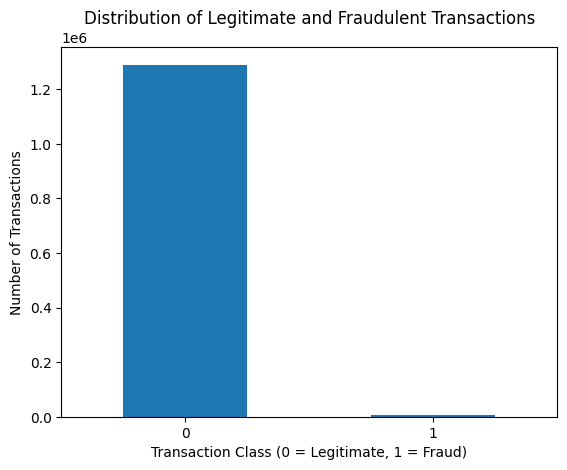

In [ ]:
fraud_counts.plot(kind='bar')

plt.title('Distribution of Legitimate and Fraudulent Transactions')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel ('Number of Transactions')
plt.xticks(rotation=0)
plt.show()


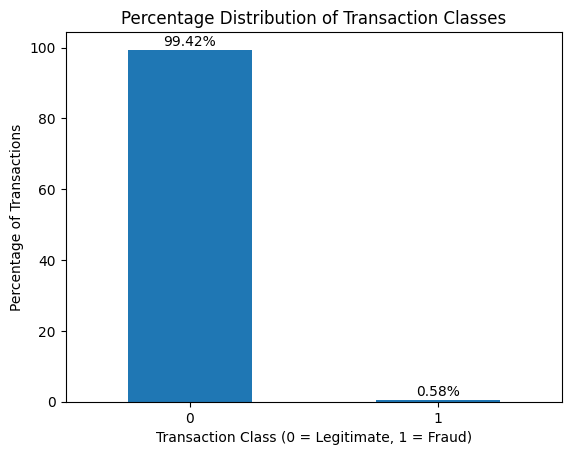

In [ ]:
ax = fraud_percentage.plot(kind='bar')

plt.title('Percentage Distribution of Transaction Classes')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Percentage of Transactions')
plt.xticks(rotation=0)

for i, value in enumerate(fraud_percentage):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

### 7.4 Transaction Amount Analysis

Transaction amount (`amt`) is an important numerical feature in fraud detection.

The distribution of transaction amounts is examined to understand typical spending
behavior, identify skewness, and detect unusually large transactions that may
represent potential outliers.

A histogram is used to examine the overall distribution, while a boxplot is used
to identify extreme transaction amounts.

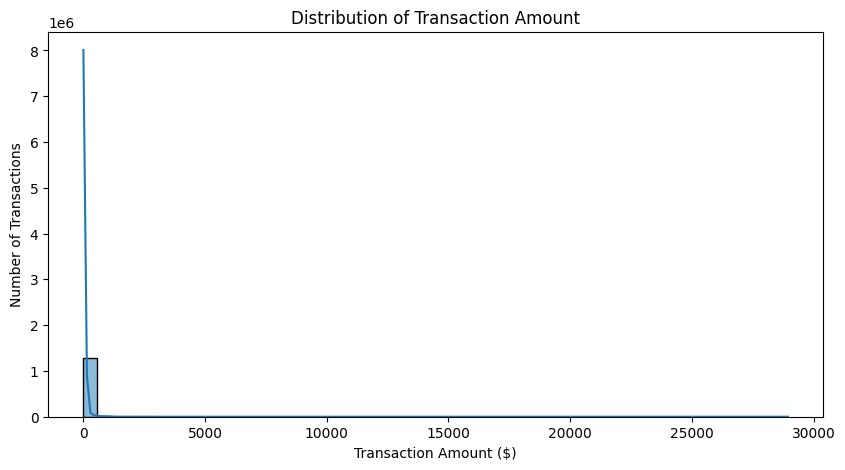

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(train_df['amt'], bins=50, kde=True)

plt.title('Distribution of Transaction Amount')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Number of Transactions')

plt.show()

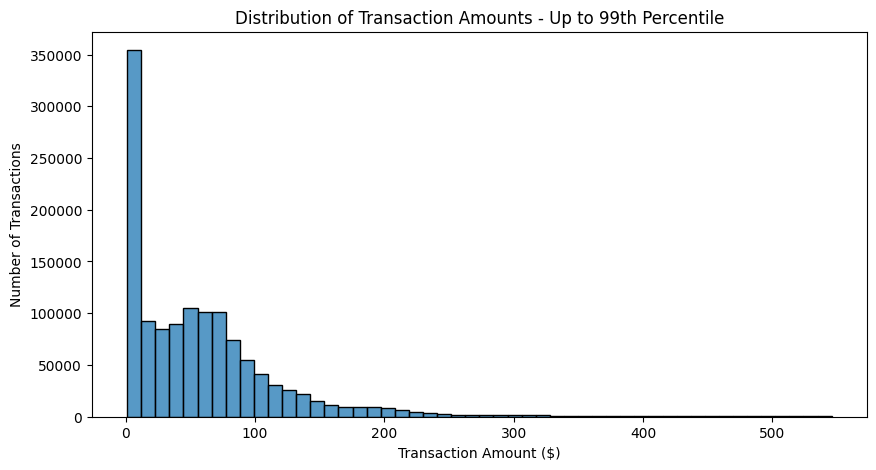

In [ ]:
amt_99 = train_df['amt'].quantile(0.99)

plt.figure(figsize=(10,5))

sns.histplot(
    data=train_df[train_df['amt'] <= amt_99],
    x='amt',
    bins=50
)

plt.title('Distribution of Transaction Amounts - Up to 99th Percentile')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Number of Transactions')

plt.show()

In [ ]:
print("99th percentile transaction amount:", amt_99)

99th percentile transaction amount: 545.9926000000002


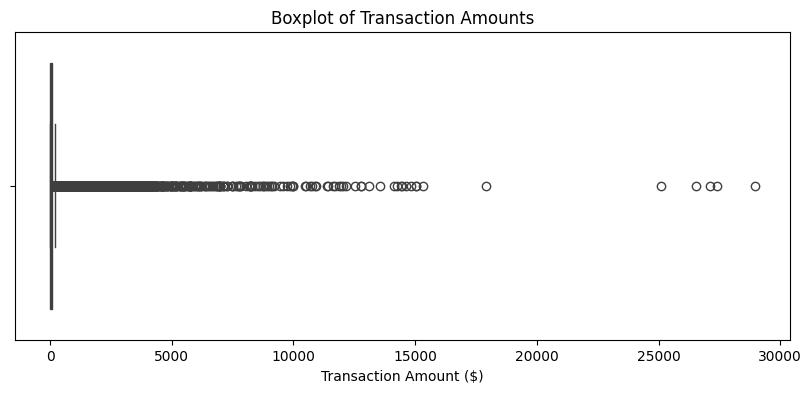

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=train_df, x='amt')

plt.title('Boxplot of Transaction Amounts')
plt.xlabel('Transaction Amount ($)')

plt.show()

In [ ]:
Q1 = train_df['amt'].quantile(0.25)
Q3 = train_df['amt'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 9.65
Q3: 83.14
IQR: 73.49
Lower Bound: -100.58499999999998
Upper Bound: 193.375


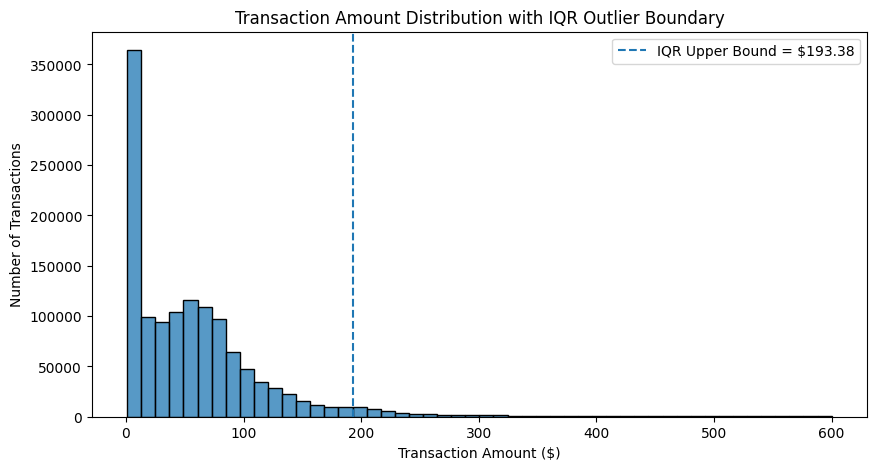

In [ ]:
Q1 = train_df['amt'].quantile(0.25)
Q3 = train_df['amt'].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

plt.figure(figsize=(10,5))

sns.histplot(
    data=train_df[train_df['amt'] <= 600],
    x='amt',
    bins=50
)

plt.axvline(
    upper_bound,
    linestyle='--',
    label=f'IQR Upper Bound = ${upper_bound:.2f}'
)

plt.title('Transaction Amount Distribution with IQR Outlier Boundary')
plt.xlabel('Transaction Amount ($)')
plt.ylabel('Number of Transactions')
plt.legend()

plt.show()

### IQR Outlier Boundary Observation

The IQR-based upper outlier boundary for transaction amount is approximately
**$193.38**.

The dashed vertical line represents this threshold. Transactions above this
amount are considered potential statistical outliers according to the
1.5 × IQR rule.

The visualization confirms that most transactions are concentrated at lower
amounts, while a smaller number of high-value transactions extend beyond the
IQR boundary.

These observations will not be removed automatically because unusually large
transaction amounts may contain meaningful information for fraud detection.

### Transaction Amount Analysis - Key Observations

The transaction amount (`amt`) shows a strongly right-skewed distribution.

- The median transaction amount is approximately **$47.52**, while the mean is
  approximately **$70.35**. The higher mean indicates that large transaction
  values are pulling the distribution toward the right.

- The maximum transaction amount is approximately **$28,948.90**, which is
  substantially higher than the 75th percentile of approximately **$83.14**.

- In the full histogram, most transactions are concentrated at relatively low
  amounts, while a small number of very large transactions create a long right
  tail.

- To better visualize the majority of transactions, the distribution was also
  examined up to the **99th percentile**, which is approximately **$545.99**.
  This shows that 99% of transactions have amounts at or below approximately
  $546. This filtering was performed only for visualization and no records were
  removed from the original dataset.

- The boxplot also identifies a large number of potential high-value outliers.
  Using the standard IQR rule, values above approximately **$193** may be
  considered statistical outliers.

These high-value transactions will not be removed automatically because unusual
transaction amounts may contain important information for identifying fraudulent
behavior.

Further analysis will compare transaction amounts between legitimate and fraudulent
transactions to determine whether transaction amount is associated with fraud.

In [ ]:
legit_transactions = train_df[train_df['is_fraud'] == 0]
fraud_transactions = train_df[train_df['is_fraud'] == 1]

In [ ]:
legit_transactions.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [ ]:
fraud_transactions.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
2449,2019-01-02 01:06:37,4613314721966,fraud_Rutherford-Mertz,grocery_pos,281.06,Jason,Murphy,M,542 Steve Curve Suite 011,Collettsville,NC,28611,35.9946,-81.7266,885,Soil scientist,1988-09-15,e8a81877ae9a0a7f883e15cb39dc4022,1325466397,36.430124,-81.179483,1
2472,2019-01-02 01:47:29,340187018810220,"fraud_Jenkins, Hauck and Friesen",gas_transport,11.52,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,TX,78208,29.4400,-98.4590,1595797,Horticultural consultant,1960-10-28,bc7d41c41103877b03232f03f1f8d3f5,1325468849,29.819364,-99.142791,1
2523,2019-01-02 03:05:23,340187018810220,fraud_Goodwin-Nitzsche,grocery_pos,276.31,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,TX,78208,29.4400,-98.4590,1595797,Horticultural consultant,1960-10-28,b98f12f4168391b2203238813df5aa8c,1325473523,29.273085,-98.836360,1
2546,2019-01-02 03:38:03,4613314721966,fraud_Erdman-Kertzmann,gas_transport,7.03,Jason,Murphy,M,542 Steve Curve Suite 011,Collettsville,NC,28611,35.9946,-81.7266,885,Soil scientist,1988-09-15,397894a5c4c02e3c61c784001f0f14e4,1325475483,35.909292,-82.091010,1
2553,2019-01-02 03:55:47,340187018810220,fraud_Koepp-Parker,grocery_pos,275.73,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,TX,78208,29.4400,-98.4590,1595797,Horticultural consultant,1960-10-28,7863235a750d73a244c07f1fb7f0185a,1325476547,29.786426,-98.683410,1


In [ ]:
legit_amt = legit_transactions['amt']
fraud_amt = fraud_transactions['amt']

In [ ]:
print("Legitimate transaction amounts:")
print(legit_amt.describe())

print("\nFraud transaction amounts:")
print(fraud_amt.describe())

Legitimate transaction amounts:
count    1.289169e+06
mean     6.766711e+01
std      1.540080e+02
min      1.000000e+00
25%      9.610000e+00
50%      4.728000e+01
75%      8.254000e+01
max      2.894890e+04
Name: amt, dtype: float64

Fraud transaction amounts:
count    7506.000000
mean      531.320092
std       390.560070
min         1.060000
25%       245.662500
50%       396.505000
75%       900.875000
max      1376.040000
Name: amt, dtype: float64


### Fraud vs Legitimate Transaction Amounts

Transaction amounts were compared between legitimate and fraudulent transactions.

The analysis shows a substantial difference between the two classes:

- The average legitimate transaction amount is approximately **$67.07**,
  compared with approximately **$531.32** for fraudulent transactions.

- The median legitimate transaction amount is approximately **$47.28**,
  while the median fraudulent transaction amount is approximately **$396.51**.

- The middle 50% of fraudulent transactions range approximately from
  **$245.66 to $900.88**, whereas the middle 50% of legitimate transactions
  range approximately from **$9.61 to $82.54**.

This indicates that transaction amount may be an important predictor of fraud.

However, high transaction amounts should not automatically be classified as
fraudulent. The maximum legitimate transaction exceeds **$28,000**, while the
maximum fraudulent transaction is approximately **$1,376**.

Therefore, transaction amount should be considered together with other customer,
merchant, geographical, and behavioral features rather than being used as a
standalone fraud rule.

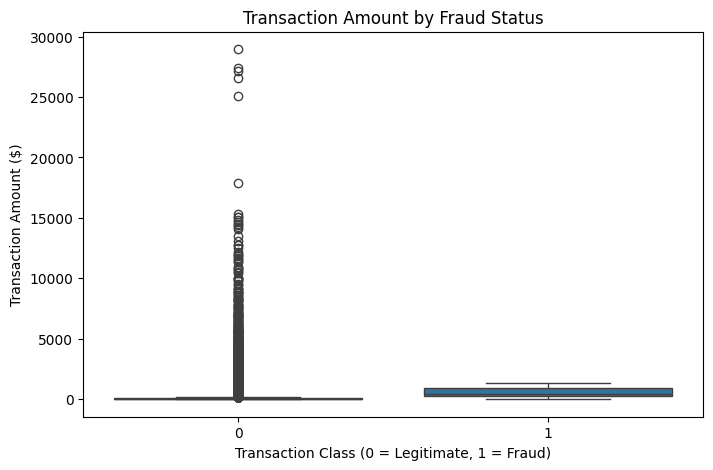

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=train_df,
    x='is_fraud',
    y='amt'
)

plt.title('Transaction Amount by Fraud Status')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Transaction Amount ($)')

plt.show()


### Fraud vs Legitimate Transaction Amounts - Boxplot Observation

The boxplot shows a clear difference in transaction amount distributions between
legitimate and fraudulent transactions.

- Legitimate transactions generally occur at much lower amounts, but they contain
  many high-value statistical outliers.

- Fraudulent transactions have substantially higher typical transaction amounts.
  The median fraudulent transaction is much higher than the median legitimate
  transaction.

- Few or no fraudulent transactions appear as IQR-based outliers because the
  fraud transaction distribution itself is centered at higher values. Therefore,
  amounts that would be unusual for legitimate transactions may be relatively
  normal within the fraud class.

- This suggests that `amt` is likely to be an important feature for fraud detection.

However, transaction amount alone cannot determine whether a transaction is
fraudulent, since legitimate transactions can also have very large amounts.
Therefore, `amt` should be combined with other customer, merchant, geographic,
and behavioral features when building the fraud detection model.

### 7.5 Transaction Category Analysis

The `category` feature represents the type of transaction performed.

Since different types of purchases may exhibit different fraud patterns, the
distribution of transaction categories and their associated fraud rates are
examined.

The analysis will first examine overall transaction volume by category and then
compare the percentage of fraudulent transactions within each category.

In [ ]:
category_counts = train_df['category'].value_counts()
category_counts

,count
category,
gas_transport,131659
grocery_pos,123638
home,123115
shopping_pos,116672
kids_pets,113035
shopping_net,97543
entertainment,94014
food_dining,91461
personal_care,90758


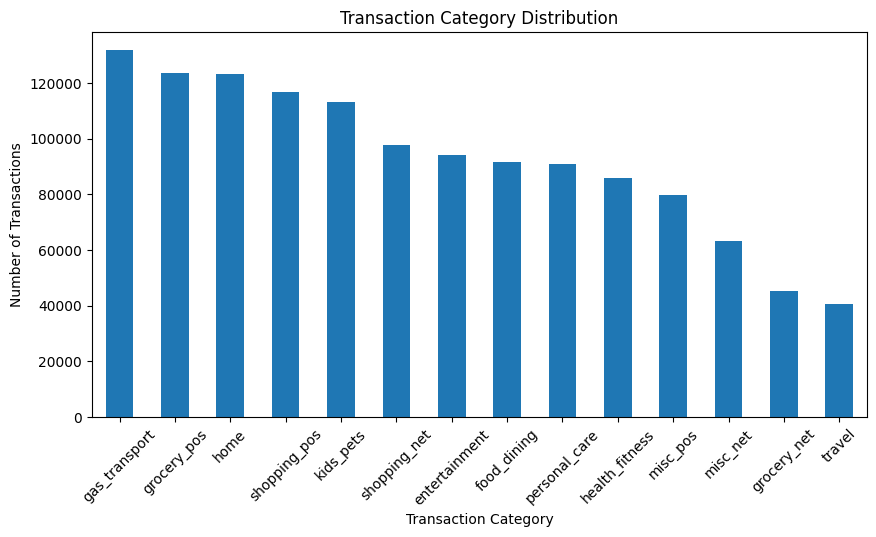

In [ ]:
plt.figure(figsize=(10,5))

category_counts.plot(kind='bar')

plt.title('Transaction Category Distribution')
plt.xlabel('Transaction Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.show()

In [ ]:
category_fraud_rate = (
    train_df.groupby('category')['is_fraud']
    .mean()
    .sort_values(ascending=False)
    * 100
)

category_fraud_rate

,is_fraud
category,
shopping_net,1.756149
misc_net,1.445795
grocery_pos,1.409761
shopping_pos,0.722538
gas_transport,0.469394
misc_pos,0.313853
grocery_net,0.294817
travel,0.286370
entertainment,0.247835


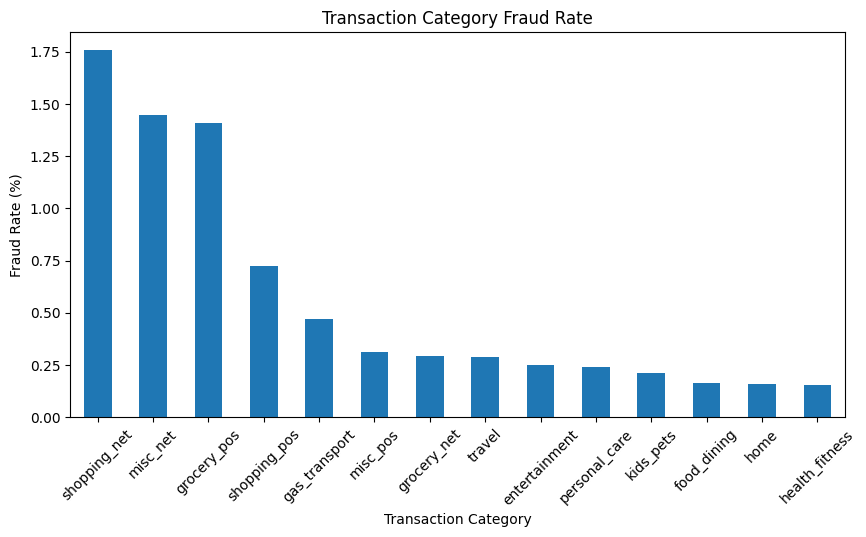

In [ ]:
plt.figure(figsize =(10,5))

category_fraud_rate.plot(kind='bar')

plt.title('Transaction Category Fraud Rate')
plt.xlabel('Transaction Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)

plt.show()


### Fraud Rate by Transaction Category - Observation

Fraud rates vary substantially across transaction categories.

- `shopping_net` has the highest observed fraud rate at approximately **1.76%**.
- `misc_net` and `grocery_pos` also show relatively high fraud rates of
  approximately **1.45%** and **1.41%**, respectively.
- Categories such as `health_fitness`, `home`, and `food_dining` have much
  lower observed fraud rates.

Considering that the overall fraud rate in the dataset is approximately **0.58%**,
certain categories show a substantially elevated fraud rate.

This suggests that transaction category may be an informative feature for fraud
prediction. However, category alone is not sufficient to classify a transaction
as fraudulent and should be considered together with other transaction and
customer characteristics.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud'],
      dtype='object')

In [ ]:
train_df['trans_date_trans_time']=pd.to_datetime(train_df['trans_date_trans_time'])
test_df['trans_date_trans_time']= pd.to_datetime(train_df['trans_date_trans_time'])

print(train_df['trans_date_trans_time'].head())
print(test_df['trans_date_trans_time'].head())

0   2019-01-01 00:00:18
1   2019-01-01 00:00:44
2   2019-01-01 00:00:51
3   2019-01-01 00:01:16
4   2019-01-01 00:03:06
Name: trans_date_trans_time, dtype: datetime64[ns]
0   2019-01-01 00:00:18
1   2019-01-01 00:00:44
2   2019-01-01 00:00:51
3   2019-01-01 00:01:16
4   2019-01-01 00:03:06
Name: trans_date_trans_time, dtype: datetime64[ns]


In [ ]:
train_df['hour'] = train_df['trans_date_trans_time'].dt.hour
train_df['day_of_week'] = train_df['trans_date_trans_time'].dt.day_name()
train_df['month'] = train_df['trans_date_trans_time'].dt.month
train_df['is_weekend'] = (
    train_df['trans_date_trans_time'].dt.dayofweek >= 5
).astype(int)

In [ ]:
train_df[
    ['trans_date_trans_time', 'hour', 'day_of_week', 'month', 'is_weekend']
].head()

,trans_date_trans_time,hour,day_of_week,month,is_weekend
0,2019-01-01 00:00:18,0,Tuesday,1,0
1,2019-01-01 00:00:44,0,Tuesday,1,0
2,2019-01-01 00:00:51,0,Tuesday,1,0
3,2019-01-01 00:01:16,0,Tuesday,1,0
4,2019-01-01 00:03:06,0,Tuesday,1,0


In [ ]:
hourly_fraud_rate = (
    train_df.groupby('hour')['is_fraud']
    .mean()
    * 100
)

hourly_fraud_rate

,is_fraud
hour,
0,1.494047
1,1.534909
2,1.465210
3,1.423929
4,0.109882
5,0.142278
6,0.094563
7,0.132692
8,0.115281


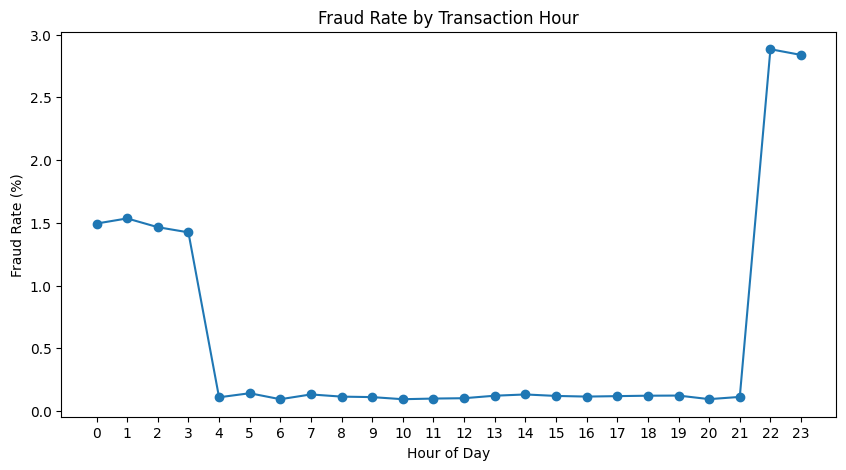

In [ ]:
plt.figure(figsize=(10,5))

hourly_fraud_rate.plot(
    kind='line',
    marker='o'
)

plt.title('Fraud Rate by Transaction Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(0,24))

plt.show()

### Fraud Rate by Transaction Hour - Observation

Fraud rates vary significantly depending on the transaction hour.

- The highest fraud rates are observed during late-night hours, particularly
  around **22:00–23:00 (10 PM–11 PM)**.
- Fraud rates are also elevated during the early morning hours between
  approximately **00:00 and 03:00**.
- Fraud rates remain substantially lower during most daytime and evening hours.

This suggests that transaction time may be an informative feature for fraud
prediction. Late-night and early-morning transactions appear to carry a higher
historical fraud risk in this dataset.

However, fraud rate should also be interpreted together with the number of
transactions occurring during each hour, since a high rate based on a small
number of transactions may be less reliable.

In [ ]:
hourly_counts = train_df['hour'].value_counts().sort_index()
hourly_counts

,count
hour,
0,42502
1,42869
2,42656
3,42769
4,41863
5,42171
6,42300
7,42203
8,42505


In [ ]:
hourly_fraud_counts = (
    train_df[train_df['is_fraud'] == 1]
    ['hour']
    .value_counts()
    .sort_index()
)

hourly_fraud_counts

,count
hour,
0,635
1,658
2,625
3,609
4,46
5,60
6,40
7,56
8,49


In [ ]:
hourly_summary = pd.DataFrame({
    'total_transactions': hourly_counts,
    'fraud_transactions': hourly_fraud_counts
})

hourly_summary['fraud_rate_pct'] = (
    hourly_summary['fraud_transactions']
    / hourly_summary['total_transactions']
    * 100
)

hourly_summary

,total_transactions,fraud_transactions,fraud_rate_pct
hour,,,
0,42502,635,1.494047
1,42869,658,1.534909
2,42656,625,1.465210
3,42769,609,1.423929
4,41863,46,0.109882
5,42171,60,0.142278
6,42300,40,0.094563
7,42203,56,0.132692
8,42505,49,0.115281


### Transaction Hour Analysis - Observation

Transaction hour shows a strong relationship with fraud occurrence.

- Fraud activity is substantially elevated between approximately **00:00 and 03:00**.
- During these hours, more than 600 fraudulent transactions are observed per hour,
  with fraud rates around 1.4%–1.5%.
- From approximately 04:00 onward, fraud counts and fraud rates fall sharply for
  most of the day.
- The elevated fraud rates during early-morning hours are not simply caused by very
  low transaction volume, since total transaction counts during these hours remain
  comparable to other periods.

This suggests that transaction hour may be an informative feature for fraud prediction.

7.7 Fraud by Day of Week

In [ ]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_fraud_rate = (
    train_df.groupby('day_of_week')['is_fraud']
    .mean()
    .reindex(day_order)
    * 100
)

day_fraud_rate

,is_fraud
day_of_week,
Monday,0.464838
Tuesday,0.583547
Wednesday,0.655360
Thursday,0.684387
Friday,0.708600
Saturday,0.610578
Sunday,0.485276


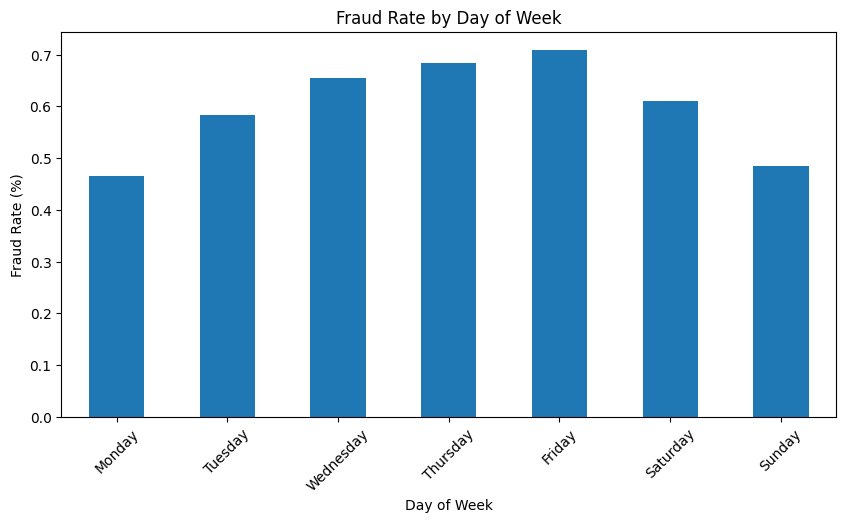

In [ ]:
plt.figure(figsize=(10,5))

day_fraud_rate.plot(kind='bar')

plt.title('Fraud Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)

plt.show()

In [ ]:
day_counts = (
    train_df['day_of_week']
    .value_counts()
    .reindex(day_order)
)

day_fraud_counts = (
    train_df[train_df['is_fraud'] == 1]['day_of_week']
    .value_counts()
    .reindex(day_order)
)

day_summary = pd.DataFrame({
    'total_transactions': day_counts,
    'fraud_transactions': day_fraud_counts,
    'fraud_rate_pct': day_fraud_rate
})

day_summary

,total_transactions,fraud_transactions,fraud_rate_pct
day_of_week,,,
Monday,254282,1182,0.464838
Tuesday,160227,935,0.583547
Wednesday,131073,859,0.655360
Thursday,147285,1008,0.684387
Friday,152272,1079,0.708600
Saturday,200957,1227,0.610578
Sunday,250579,1216,0.485276


### Fraud Analysis by Day of Week - Observation

Fraud rates vary moderately across the days of the week.

- Friday shows the highest observed fraud rate at approximately **0.71%**.
- Thursday and Wednesday also show relatively elevated fraud rates.
- Monday and Sunday show lower fraud rates of approximately **0.46%** and
  **0.49%**, respectively.

Although some variation exists across days, the differences are less pronounced
than the fraud patterns observed by transaction hour.

This suggests that day of week may provide some predictive information, but it
is likely to be less influential than transaction hour when identifying fraud.

### 7.8 Monthly Analysis

In [ ]:
print(train_df['trans_date_trans_time'].min())
print(train_df['trans_date_trans_time'].max())

2019-01-01 00:00:18
2020-06-21 12:13:37


### 7.8 Monthly Fraud Analysis

The training dataset spans from January 2019 through June 2020.

Monthly fraud patterns are analyzed to determine whether fraud rates change over
time or show possible seasonal behavior.

Because the dataset spans more than one year, year and month are considered
together to preserve the chronological sequence of transactions.

In [ ]:
train_df['year_month'] = (
    train_df['trans_date_trans_time']
    .dt.to_period('M')
)

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud', 'hour', 'day_of_week', 'month', 'is_weekend',
       'year_month'],
      dtype='object')

In [ ]:
train_df[['year_month', 'month']].head()

,year_month,month
0,2019-01,1
1,2019-01,1
2,2019-01,1
3,2019-01,1
4,2019-01,1


In [ ]:
monthly_fraud_rate = (
    train_df.groupby('year_month')['is_fraud']
    .mean()
    * 100
)

monthly_fraud_rate

,is_fraud
year_month,
2019-01,0.963351
2019-02,1.036779
2019-03,0.696373
2019-04,0.552308
2019-05,0.562510
2019-06,0.411322
2019-07,0.382235
2019-08,0.437276
2019-09,0.591632


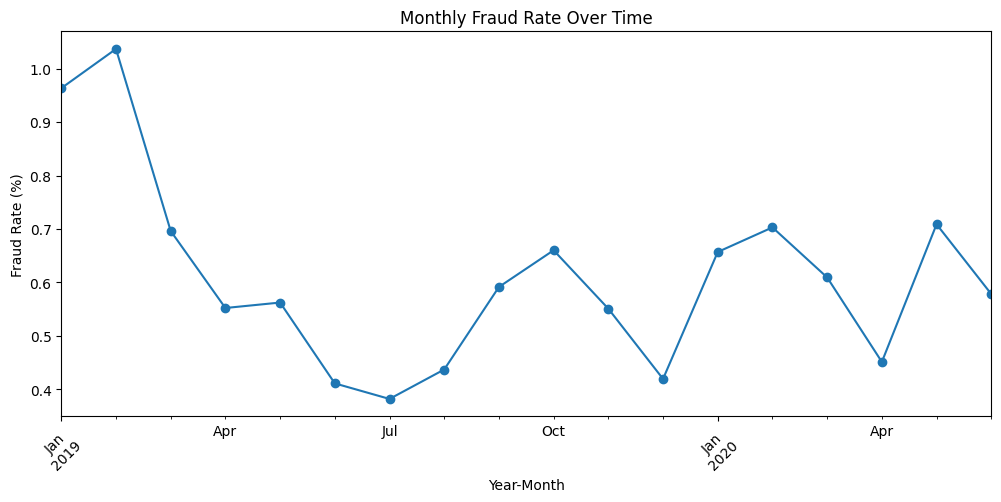

In [ ]:
plt.figure(figsize=(12,5))

monthly_fraud_rate.plot(kind='line', marker='o')

plt.title('Monthly Fraud Rate Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)

plt.show()

### Monthly Fraud Rate Over Time - Observation

The monthly fraud rate shows noticeable variation throughout the dataset period.

- The highest fraud rates are observed during the early months of 2019,
  particularly January and February.
- Fraud rates decline during the middle of 2019 before increasing again
  toward the later months of the year.
- During 2020, fraud rates continue to fluctuate rather than following a
  consistent upward or downward trend.
- This suggests that fraud activity may vary over time and that temporal
  information could provide useful predictive information.

However, the dataset covers only January 2019 through June 2020, so the observed
pattern is not sufficient to establish a reliable long-term seasonal trend.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud', 'hour', 'day_of_week', 'month', 'is_weekend',
       'year_month'],
      dtype='object')

In [ ]:
weekend_counts= train_df['is_weekend'].value_counts()
weekend_counts

,count
is_weekend,
0,845139
1,451536


In [ ]:
weekend_fraud_count = train_df[train_df['is_fraud'] ==1 ]['is_weekend'].value_counts().sort_index()
weekend_fraud_count

,count
is_weekend,
0,5063
1,2443


In [ ]:
weekend_fraud_rate = (
    train_df.groupby('is_weekend')['is_fraud']
    .mean()
    * 100
)
weekend_fraud_rate

,is_fraud
is_weekend,
0,0.599073
1,0.541042


In [ ]:
weekend_summary = pd.DataFrame({
    'total_transactions': weekend_counts,
    'fraud_transactions': weekend_fraud_count,
    'fraud_rate_pct': weekend_fraud_rate
})

weekend_summary

,total_transactions,fraud_transactions,fraud_rate_pct
is_weekend,,,
0,845139,5063,0.599073
1,451536,2443,0.541042


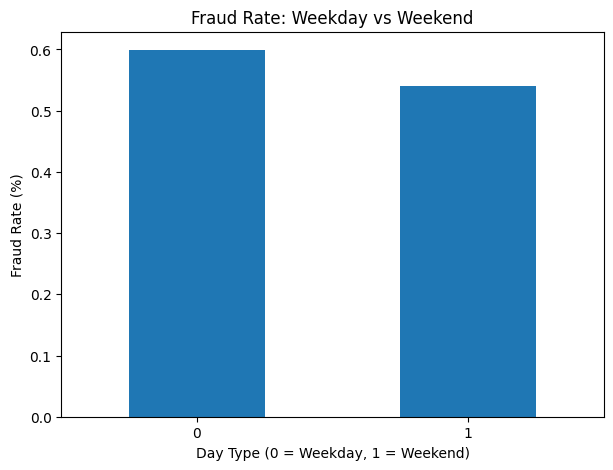

In [ ]:
plt.figure(figsize=(7,5))

weekend_fraud_rate.plot(kind='bar')

plt.title('Fraud Rate: Weekday vs Weekend')
plt.xlabel('Day Type (0 = Weekday, 1 = Weekend)')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=0)

plt.show()

### Weekend vs Weekday Fraud Analysis - Observation

The fraud rate is slightly higher on weekdays than on weekends.

- Weekday fraud rate is approximately **0.60%**.
- Weekend fraud rate is approximately **0.54%**.

The difference is relatively small compared with stronger patterns observed in
features such as transaction hour and transaction category.

This suggests that `is_weekend` may provide some additional predictive information,
but it is unlikely to be a strong fraud indicator by itself.

### 7.10 Customer Age Analysis

Customer date of birth (`dob`) is converted into a useful numerical feature representing
the customer's age at the time of each transaction.

Age may help identify whether fraud patterns differ across customer age groups.

The age is calculated relative to the transaction date rather than using the current age,
so that each historical transaction reflects the customer's age at that specific time.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud', 'hour', 'day_of_week', 'month', 'is_weekend',
       'year_month'],
      dtype='object')

In [ ]:
train_df['dob'] = pd.to_datetime(train_df['dob'])
test_df['dob'] = pd.to_datetime(test_df['dob'])

train_df['trans_date_trans_time'] = pd.to_datetime(
    train_df['trans_date_trans_time']
)

test_df['trans_date_trans_time'] = pd.to_datetime(
    test_df['trans_date_trans_time']
)

In [ ]:
train_df['age'] = (
    train_df['trans_date_trans_time'].dt.year
    - train_df['dob'].dt.year
    - (
        train_df['trans_date_trans_time'].dt.strftime('%m%d')
        <
        train_df['dob'].dt.strftime('%m%d')
    )
)

test_df['age'] = (
    test_df['trans_date_trans_time'].dt.year
    - test_df['dob'].dt.year
    - (
        test_df['trans_date_trans_time'].dt.strftime('%m%d')
        <
        test_df['dob'].dt.strftime('%m%d')
    )
)


In [ ]:
train_df[['dob', 'trans_date_trans_time', 'age']].head()

,dob,trans_date_trans_time,age
0,1988-03-09,2019-01-01 00:00:18,30
1,1978-06-21,2019-01-01 00:00:44,40
2,1962-01-19,2019-01-01 00:00:51,56
3,1967-01-12,2019-01-01 00:01:16,51
4,1986-03-28,2019-01-01 00:03:06,32


### 7.10 Customer Age Analysis

Customer age was derived from date of birth (`dob`) and the transaction date.

Age is analyzed to determine whether fraud rates differ across customer age groups.
This may help identify whether certain age segments experience relatively higher
fraud risk.

In [ ]:
train_df['age'].describe()

,age
count,1.296675e+06
mean,4.549688e+01
std,1.739702e+01
min,1.300000e+01
25%,3.200000e+01
50%,4.300000e+01
75%,5.700000e+01
max,9.500000e+01


### Customer Age Distribution - Observation

Customer age ranges from approximately **13 to 95 years**.

- The average customer age is approximately **45.5 years**.
- The median customer age is approximately **43 years**.
- The middle 50% of transactions involve customers between approximately
  **32 and 57 years old**.

The wide age range suggests that fraud patterns may differ across age groups.
Therefore, customer age will be grouped into age bands to compare fraud rates
across different customer segments.

The minimum observed age is 13 years. Since the dataset is synthetic, these
records will not be removed automatically without further investigation.

In [ ]:
age_bins = [0, 29, 39, 49, 59, 69, 120]

age_labels = [
    'Under 30',
    '30-39',
    '40-49',
    '50-59',
    '60-69',
    '70+'
]

train_df['age_group'] = pd.cut(
    train_df['age'],
    bins=age_bins,
    labels=age_labels
)

train_df['age_group'].head()

,age_group
0,30-39
1,40-49
2,50-59
3,50-59
4,30-39


In [ ]:
age_fraud_rate= train_df.groupby('age_group')['is_fraud'].mean() * 100
age_fraud_rate

,is_fraud
age_group,
Under 30,0.592492
30-39,0.441445
40-49,0.455115
50-59,0.750416
60-69,0.626442
70+,0.845526


In [ ]:
age_counts = train_df['age_group'].value_counts().sort_index()

age_fraud_counts = (
    train_df[train_df['is_fraud'] == 1]['age_group'].value_counts()
)


age_summary= pd.DataFrame({
    'total_transactions': age_counts,
    'fraud_transactions': age_fraud_counts,
    'fraud_rate_pct': age_fraud_rate
})

age_summary

,total_transactions,fraud_transactions,fraud_rate_pct
age_group,,,
Under 30,244054,1446,0.592492
30-39,291316,1286,0.441445
40-49,304319,1385,0.455115
50-59,184964,1388,0.750416
60-69,136485,855,0.626442
70+,135537,1146,0.845526


### Customer Age and Fraud - Observation

Fraud rates vary noticeably across customer age groups.

- Customers aged **70+** show the highest observed fraud rate at approximately
  **0.85%**.
- Customers aged **50–59** also show an elevated fraud rate of approximately
  **0.75%**.
- Customers aged **60–69** have a fraud rate of approximately **0.63%**.
- Customers aged **30–49** show comparatively lower fraud rates, around
  **0.44%–0.46%**.

The higher fraud rates among older age groups are supported by substantial transaction
volumes, rather than being driven by very small sample sizes.

This suggests that customer age may be a useful predictive feature for fraud detection.
However, age alone should not be used to classify transactions and should instead be
combined with transaction, merchant, geographical, and behavioral features.

### 7.11 Cardholder-to-Merchant Geographical Distance

The dataset provides latitude and longitude coordinates for both the cardholder
location and the merchant location.

A new feature, `cardholder_merchant_distance_km`, is created to measure the
geographical distance between these two locations.

This feature may help identify transactions occurring unusually far from the
cardholder's reference location.

It is important to note that the cardholder coordinates provided in the dataset
should not be interpreted as the customer's real-time GPS location at the moment
of the transaction. Therefore, a large distance does not automatically indicate
fraud and should be considered together with other transaction and behavioral
features.

In [ ]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate geographical distance between two latitude/longitude points
    using the Haversine formula.

    Returns distance in kilometers.
    """

    R = 6371  # Radius of Earth in kilometers

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [ ]:
train_df['cardholder_merchant_distance_km'] = haversine_distance(
    train_df['lat'],
    train_df['long'],
    train_df['merch_lat'],
    train_df['merch_long']
)

In [ ]:
train_df.groupby('is_fraud')['cardholder_merchant_distance_km'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,76.113756,29.119051,0.022255,55.332701,78.233012,98.504498,152.117173
1,7506.0,76.268330,28.752602,0.738769,55.632890,77.931954,98.391090,144.522410


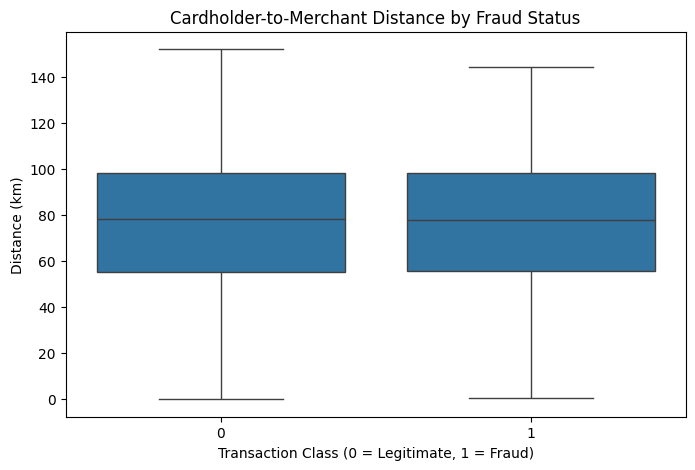

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=train_df,
    x='is_fraud',
    y='cardholder_merchant_distance_km'
)

plt.title('Cardholder-to-Merchant Distance by Fraud Status')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Distance (km)')

plt.show()

### Cardholder-to-Merchant Distance - Observation

The geographical distance between the cardholder's reference location and the
merchant location was calculated using the Haversine formula.

The distance distributions for legitimate and fraudulent transactions are very
similar:

- Mean distance for legitimate transactions is approximately **76.11 km**.
- Mean distance for fraudulent transactions is approximately **76.27 km**.
- Median distances are also nearly identical for the two classes.

This suggests that geographical distance alone does not show a strong relationship
with fraud in this dataset.

However, the feature may still provide useful information when combined with
transaction amount, transaction time, merchant category, and customer behavioral
features in a machine learning model.

### 7.12 Transaction Velocity Analysis

Fraud may involve multiple transactions occurring within a short period of time.

To capture this behavior, a new feature called `time_since_prev_txn_min` is created.
It measures the number of minutes between the current transaction and the previous
transaction made using the same credit card.

A shorter time interval may indicate unusually rapid transaction activity.

For this exploratory analysis, the feature is calculated on the training data using
only transaction timestamps. No fraud labels are used in the calculation.

In [ ]:
train_df = train_df.sort_values(
    ['cc_num', 'trans_date_trans_time']
).reset_index(drop=True)

In [ ]:
train_df['time_since_prev_txn_min'] = (
    train_df.groupby('cc_num')['trans_date_trans_time']
    .diff()
    .dt.total_seconds()
    / 60
)

In [ ]:
train_df[
    [
        'cc_num',
        'trans_date_trans_time',
        'time_since_prev_txn_min',
        'is_fraud'
    ]
].head(10)

,cc_num,trans_date_trans_time,time_since_prev_txn_min,is_fraud
0,60416207185,2019-01-01 12:47:15,NaN,0
1,60416207185,2019-01-02 08:44:57,1197.700000,0
2,60416207185,2019-01-02 08:47:36,2.650000,0
3,60416207185,2019-01-02 12:38:14,230.633333,0
4,60416207185,2019-01-02 13:10:46,32.533333,0
5,60416207185,2019-01-03 13:56:35,1485.816667,0
6,60416207185,2019-01-03 17:05:10,188.583333,0
7,60416207185,2019-01-04 13:59:55,1254.750000,0
8,60416207185,2019-01-04 21:17:22,437.450000,0
9,60416207185,2019-01-05 00:42:24,205.033333,0


In [ ]:
train_df['time_since_prev_txn_min'].describe()

,time_since_prev_txn_min
count,1.295692e+06
mean,5.414169e+02
std,7.900163e+02
min,0.000000e+00
25%,1.002167e+02
50%,2.760000e+02
75%,6.703833e+02
max,2.235785e+04


In [ ]:
train_df.groupby('is_fraud')['time_since_prev_txn_min'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1288261.0,542.489944,790.821174,0.000000,101.066667,277.05,671.033333,22357.85
1,7431.0,355.394377,607.278258,0.016667,24.550000,81.80,482.908333,14417.95


### Transaction Velocity - Observation

The time between consecutive transactions differs substantially between legitimate
and fraudulent transactions.

- The median time since the previous transaction is approximately **277 minutes
  (4.6 hours)** for legitimate transactions.
- For fraudulent transactions, the median interval is only approximately
  **82 minutes (1.4 hours)**.
- The 25th percentile for fraudulent transactions is approximately **25 minutes**,
  compared with approximately **101 minutes** for legitimate transactions.

These results suggest that fraudulent transactions tend to occur more rapidly
after a previous transaction.

Therefore, `time_since_prev_txn_min` may be an informative behavioral feature for
fraud detection and supports the use of transaction velocity in the modeling pipeline.

### 7.13 Customer Spending Behavior Analysis

Fraudulent transactions may differ substantially from a cardholder's normal
spending behavior.

To capture this behavior, historical spending features are created for each
credit card using only transactions that occurred before the current transaction.

Two features are created:

- `customer_prev_avg_amt`: Average amount of the cardholder's previous transactions.
- `amt_ratio_to_prev_avg`: Current transaction amount divided by the cardholder's
  previous average transaction amount.

Using only previous transactions prevents future transaction information from
being used when evaluating the current transaction.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud', 'hour', 'day_of_week', 'month', 'is_weekend',
       'year_month', 'age', 'age_group', 'cardholder_merchant_distance_km',
       'time_since_prev_txn_min'],
      dtype='object')

In [ ]:
previous_spend_sum = (
    train_df.groupby('cc_num')['amt'].cumsum()
    - train_df['amt']
)

previous_txn_count = train_df.groupby('cc_num').cumcount()

train_df['customer_prev_avg_amt'] = (
    previous_spend_sum
    / previous_txn_count.replace(0, np.nan)
)

In [ ]:
train_df['amt_ratio_to_prev_avg'] = (
    train_df['amt']
    / train_df['customer_prev_avg_amt']
)

In [ ]:
train_df[
    [
        'cc_num',
        'trans_date_trans_time',
        'amt',
        'customer_prev_avg_amt',
        'amt_ratio_to_prev_avg',
        'is_fraud'
    ]
].head(15)

,cc_num,trans_date_trans_time,amt,customer_prev_avg_amt,amt_ratio_to_prev_avg,is_fraud
0,60416207185,2019-01-01 12:47:15,7.27,NaN,NaN,0
1,60416207185,2019-01-02 08:44:57,52.94,7.270000,7.281981,0
2,60416207185,2019-01-02 08:47:36,82.08,30.105000,2.726457,0
3,60416207185,2019-01-02 12:38:14,34.79,47.430000,0.733502,0
4,60416207185,2019-01-02 13:10:46,27.18,44.270000,0.613960,0
5,60416207185,2019-01-03 13:56:35,6.87,40.852000,0.168168,0
6,60416207185,2019-01-03 17:05:10,8.43,35.188333,0.239568,0
7,60416207185,2019-01-04 13:59:55,117.11,31.365714,3.733695,0
8,60416207185,2019-01-04 21:17:22,26.74,42.083750,0.635400,0
9,60416207185,2019-01-05 00:42:24,105.20,40.378889,2.605322,0


### Customer Spending Behavior - Observation

A customer's historical spending behavior was analyzed by comparing each current
transaction amount with the average amount of that cardholder's previous transactions.

Two features were created:

- `customer_prev_avg_amt` = average amount of all previous transactions for the same card
- `amt_ratio_to_prev_avg` = current transaction amount divided by the previous average amount

The current transaction is intentionally excluded from the historical average so that
only past spending behavior is used.

Interpretation of `amt_ratio_to_prev_avg`:

- A value of **1** means the current transaction is equal to the customer's previous average.
- A value greater than **1** means the current transaction is higher than the customer's normal historical spending.
- A value less than **1** means the current transaction is lower than the customer's previous average.

For example, if a customer's historical average transaction amount is $25 and the
current transaction is $100, the ratio would be:

\[
100 / 25 = 4
\]

This means the current transaction is four times larger than the customer's historical
average.

Large deviations from normal spending do not automatically indicate fraud, since
legitimate transactions may also be much higher than a customer's usual spending.

However, this behavioral feature may become useful when combined with other fraud
signals such as transaction amount, transaction velocity, merchant category, time,
and customer characteristics.

### 7.14 Spending Behavior vs Fraud

The relationship between customer historical spending behavior and fraud is examined.

The feature `amt_ratio_to_prev_avg` measures how large the current transaction is
relative to the cardholder's average previous transaction amount.

If fraudulent transactions tend to have higher ratios, this feature may provide
useful behavioral information for fraud detection.

In [ ]:
train_df.groupby('is_fraud')['amt_ratio_to_prev_avg'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1288261.0,0.986726,2.573890,0.002176,0.156342,0.664100,1.194620,676.388128
1,7431.0,6.983198,6.844908,0.006900,1.176721,5.229653,11.928483,160.147673


In [ ]:
train_df.groupby('is_fraud')['customer_prev_avg_amt'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1288261.0,70.118065,17.684811,1.030000,58.005353,65.022974,83.785075,1433.54
1,7431.0,117.470212,144.875156,3.203333,61.038665,70.423957,94.880088,1324.80


### Spending Behavior vs Fraud - Observation

Fraudulent transactions show a substantial deviation from cardholders' historical
spending patterns.

- The median `amt_ratio_to_prev_avg` for legitimate transactions is approximately
  **0.66**, indicating that a typical legitimate transaction is below the customer's
  previous average transaction amount.
- The median ratio for fraudulent transactions is approximately **5.23**, meaning
  that half of fraudulent transactions are more than five times the cardholder's
  previous average transaction amount.
- The 75th percentile for fraudulent transactions reaches approximately **11.93**.

This indicates that unusually large transactions relative to a customer's historical
spending behavior may be a strong fraud signal.

However, some legitimate transactions also have very high ratios, so this feature
should not be used as a standalone fraud rule. It should be combined with other
transaction and behavioral features in the fraud detection model.

### Historical Average Spending - Observation

The historical average transaction amount differs between legitimate and fraudulent
transactions.

- The median previous average amount is approximately **$65.02** for legitimate
  transactions and **$70.42** for fraudulent transactions.
- The mean previous average amount is approximately **$70.12** for legitimate
  transactions and **$117.47** for fraudulent transactions.
- The much larger standard deviation among fraudulent transactions indicates greater
  variability in historical spending behavior.

Although fraudulent transactions are associated with somewhat higher historical
average spending, the difference in median values is relatively modest.

Therefore, `customer_prev_avg_amt` alone may have limited discriminatory power.
The derived feature `amt_ratio_to_prev_avg`, which measures how unusual the current
transaction is relative to the customer's own historical spending, appears to provide
a much stronger fraud signal.

### Historical Average Spending - Observation

The historical average transaction amount differs between legitimate and fraudulent
transactions.

- The median previous average amount is approximately **$65.02** for legitimate
  transactions and **$70.42** for fraudulent transactions.
- The mean previous average amount is approximately **$70.12** for legitimate
  transactions and **$117.47** for fraudulent transactions.
- The much larger standard deviation among fraudulent transactions indicates greater
  variability in historical spending behavior.

Although fraudulent transactions are associated with somewhat higher historical
average spending, the difference in median values is relatively modest.

Therefore, `customer_prev_avg_amt` alone may have limited discriminatory power.
The derived feature `amt_ratio_to_prev_avg`, which measures how unusual the current
transaction is relative to the customer's own historical spending, appears to provide
a much stronger fraud signal.

### 7.15 Recent Transaction Frequency

Fraud may involve several transactions occurring within a short period of time.

To capture transaction frequency, a new feature called `txn_count_prev_1h` is created.
It represents the number of transactions made by the same credit card during the
previous one-hour window.

Only transactions occurring before the current transaction are counted, ensuring
that future information is not used.

In [ ]:
train_df['txn_count_prev_1h'] = (
    train_df
    .groupby('cc_num', sort=False)
    .rolling(
        '1h',
        on='trans_date_trans_time',
        closed='left'
    )['amt']
    .count()
    .fillna(0)
    .to_numpy()
)

### Recent Transaction Frequency vs Fraud

The relationship between recent transaction frequency and fraud is examined using
the engineered feature `txn_count_prev_1h`.

This feature represents the number of transactions made by the same credit card
during the previous one-hour window.

If fraudulent transactions tend to occur after a larger number of recent
transactions, this feature may provide useful behavioral information for fraud detection.

In [ ]:
train_df.groupby('is_fraud')['txn_count_prev_1h'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,0.186689,0.455817,0.0,0.0,0.0,0.0,6.0
1,7506.0,0.678124,0.954414,0.0,0.0,0.0,1.0,6.0


In [ ]:
txn_freq_fraud_rate = (
    train_df.groupby('txn_count_prev_1h')['is_fraud']
    .mean()
    * 100
)

txn_freq_fraud_rate

,is_fraud
txn_count_prev_1h,
0.0,0.391098
1.0,1.099959
2.0,3.319871
3.0,8.918754
4.0,20.404040
5.0,29.069767
6.0,18.750000


### Recent Transaction Frequency vs Fraud - Initial Observation

Recent transaction frequency shows a strong relationship with fraud.

The average number of transactions occurring during the previous one-hour window
is approximately **0.19** for legitimate transactions and **0.68** for fraudulent
transactions.

The observed fraud rate also increases substantially as recent transaction
frequency increases:

- 0 previous transactions: approximately **0.39% fraud**
- 1 previous transaction: approximately **1.10% fraud**
- 2 previous transactions: approximately **3.32% fraud**
- 3 previous transactions: approximately **8.92% fraud**
- 4 or more previous transactions show substantially higher observed fraud rates.

This suggests that rapid repeated transaction activity may be a strong behavioral
indicator of fraud.

Transaction counts within the higher-frequency groups will also be examined to
ensure that the elevated fraud rates are supported by sufficient sample sizes.


In [ ]:
txn_freq_summary = (
    train_df.groupby('txn_count_prev_1h')
    .agg(
        total_transactions=('is_fraud', 'count'),
        fraud_transactions=('is_fraud', 'sum')
    )
)

txn_freq_summary['fraud_rate_pct'] = (
    txn_freq_summary['fraud_transactions']
    / txn_freq_summary['total_transactions']
    * 100
)

txn_freq_summary

,total_transactions,fraud_transactions,fraud_rate_pct
txn_count_prev_1h,,,
0.0,1084128,4240,0.391098
1.0,183916,2023,1.099959
2.0,24760,822,3.319871
3.0,3274,292,8.918754
4.0,495,101,20.404040
5.0,86,25,29.069767
6.0,16,3,18.750000


### Recent Transaction Frequency vs Fraud - Initial Observation

Recent transaction frequency shows a strong relationship with fraud.

The average number of transactions occurring during the previous one-hour window
is approximately **0.19** for legitimate transactions and **0.68** for fraudulent
transactions.

The observed fraud rate also increases substantially as recent transaction
frequency increases:

- 0 previous transactions: approximately **0.39% fraud**
- 1 previous transaction: approximately **1.10% fraud**
- 2 previous transactions: approximately **3.32% fraud**
- 3 previous transactions: approximately **8.92% fraud**
- 4 or more previous transactions show substantially higher observed fraud rates.

This suggests that rapid repeated transaction activity may be a strong behavioral
indicator of fraud.

Transaction counts within the higher-frequency groups will also be examined to
ensure that the elevated fraud rates are supported by sufficient sample sizes.

In [ ]:
train_df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud', 'hour', 'day_of_week', 'month', 'is_weekend',
       'year_month', 'age', 'age_group', 'cardholder_merchant_distance_km',
       'time_since_prev_txn_min', 'customer_prev_avg_amt',
       'amt_ratio_to_prev_avg', 'txn_count_prev_1h'],
      dtype='object')

### 7.16 Correlation Analysis of Numerical Features

Correlation analysis is performed to examine relationships among meaningful numerical
features and the fraud target.

Identifier-like numerical columns such as `cc_num` and `zip` are excluded because
their numerical values do not represent measurable quantities.

The analysis also includes engineered behavioral features such as transaction velocity
and deviation from historical spending patterns.

In [ ]:
corr_features = [
    'amt',
    'city_pop',
    'age',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h',
    'is_fraud'
]

corr_matrix = train_df[corr_features].corr()

corr_matrix

,amt,city_pop,age,cardholder_merchant_distance_km,time_since_prev_txn_min,customer_prev_avg_amt,amt_ratio_to_prev_avg,txn_count_prev_1h,is_fraud
amt,1.000000,0.005818,-0.009755,-0.001085,-0.003348,0.099383,0.929648,0.018253,0.219404
city_pop,0.005818,1.000000,-0.092433,0.010901,0.002324,0.046548,-0.000146,0.011660,0.002136
age,-0.009755,-0.092433,1.000000,-0.004605,0.097542,-0.080160,0.001692,-0.087829,0.012248
cardholder_merchant_distance_km,-0.001085,0.010901,-0.004605,1.000000,0.000554,0.000651,-0.000836,-0.000389,0.000403
time_since_prev_txn_min,-0.003348,0.002324,0.097542,0.000554,1.000000,0.020798,-0.000688,-0.267323,-0.017883
customer_prev_avg_amt,0.099383,0.046548,-0.080160,0.000651,0.020798,1.000000,-0.027540,0.007902,0.169677
amt_ratio_to_prev_avg,0.929648,-0.000146,0.001692,-0.000836,-0.000688,-0.027540,1.000000,0.012275,0.170411
txn_count_prev_1h,0.018253,0.011660,-0.087829,-0.000389,-0.267323,0.007902,0.012275,1.000000,0.080737
is_fraud,0.219404,0.002136,0.012248,0.000403,-0.017883,0.169677,0.170411,0.080737,1.000000


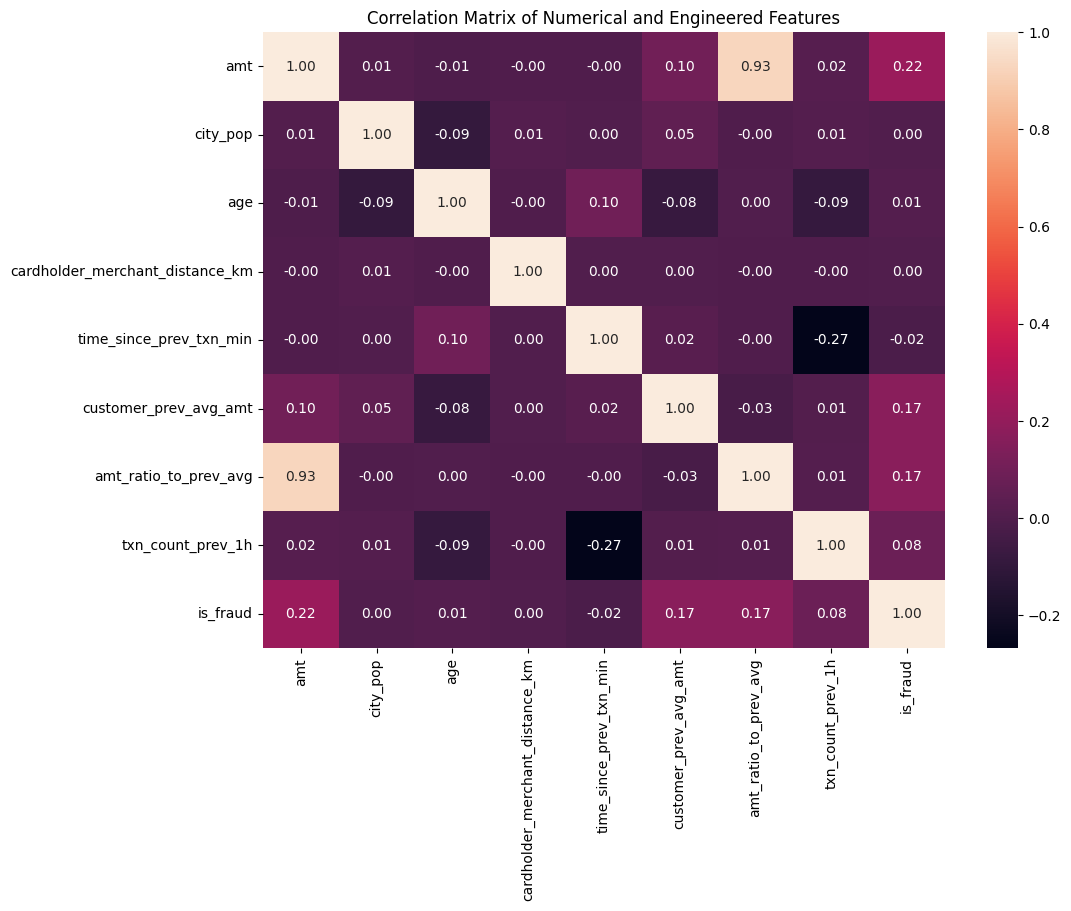

In [ ]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical and Engineered Features')

plt.show()

### Correlation Analysis - Key Conclusion

No individual numerical feature shows a very strong linear correlation with the
fraud target.

Transaction amount (`amt`) has the highest observed correlation with `is_fraud`
at approximately 0.22, while most other features show relatively weak linear
correlations.

However, earlier EDA identified meaningful nonlinear and categorical fraud patterns,
including transaction frequency, transaction hour, transaction category, and deviation
from historical spending behavior.

Therefore, low Pearson correlation does not imply that these features are unimportant.
Their predictive value will be evaluated further using machine learning models capable
of capturing nonlinear relationships and interactions between features.

## 8. Data Preparation for Modeling

After completing exploratory data analysis and feature engineering, the dataset is
prepared for machine learning.

The preprocessing stage includes:

- Selecting relevant predictive features
- Removing identifiers and redundant raw columns
- Handling missing values created by historical features
- Encoding categorical variables
- Scaling numerical variables where required
- Separating features from the target variable
- Preparing training and validation data while avoiding data leakage

In [ ]:
drop_features = [
    'first',
    'last',
    'street',
    'trans_num',
    'dob',
    'trans_date_trans_time',
    'year_month'
]

- first, last → names; very high-cardinality identity information
- street → almost customer identifier-like
- trans_num → unique transaction ID
- dob → we already created age
- trans_date_trans_time → keep in our working data, but use engineered hour, day_of_week, etc. for normal ML models
- year_month → mainly an EDA feature
We should not drop them permanently from train_df yet. Instead create a modeling copy:

In [ ]:
model_df = train_df.drop(columns=drop_features).copy()

### 8.1 Feature Selection

Before model training, features are reviewed based on their business meaning,
predictive usefulness, redundancy, and potential to behave as identifiers.

Raw identifiers and columns already represented by more meaningful engineered
features are excluded from the initial modeling dataset.

The original feature-engineered DataFrame is preserved, and a separate modeling
DataFrame will be created later.



In [ ]:
target = 'is_fraud'

drop_features = [
    'cc_num',
    'first',
    'last',
    'street',
    'zip',
    'trans_num',
    'dob',
    'trans_date_trans_time',
    'unix_time',
    'year_month',
    'age_group'
]

In [ ]:
categorical_features = [
    'category',
    'gender',
    'state',
    'day_of_week'
]

In [ ]:
numerical_features = [
    'amt',
    'city_pop',
    'age',
    'hour',
    'month',
    'is_weekend',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h'
]

### 8.2 Historical Feature Preparation for Test Data

Several engineered features depend on a cardholder's previous transaction history,
including:

- `time_since_prev_txn_min`
- `customer_prev_avg_amt`
- `amt_ratio_to_prev_avg`
- `txn_count_prev_1h`

These features cannot be calculated on the test dataset independently because the
first test transaction for a card may have historical transactions in the training
dataset.

Therefore, training and test transaction histories are temporarily combined and
ordered chronologically for feature calculation.

Only information occurring before each transaction is used. The target variable
`is_fraud` is not used in this process, preventing target leakage.

In [ ]:
test_df = pd.read_csv('/content/drive/MyDrive/fraudShieldTest.csv')

In [ ]:
print("Train:")
print(train_df['trans_date_trans_time'].min())
print(train_df['trans_date_trans_time'].max())

print("\nTest:")
print(test_df['trans_date_trans_time'].min())
print(test_df['trans_date_trans_time'].max())

Train:
2019-01-01 00:00:18
2020-06-21 12:13:37

Test:
2020-06-21 12:14:25
2020-12-31 23:59:34


In [ ]:
# Make sure both are datetime first
train_df['trans_date_trans_time'] = pd.to_datetime(
    train_df['trans_date_trans_time']
)

test_df['trans_date_trans_time'] = pd.to_datetime(
    test_df['trans_date_trans_time']
)

# Create history tables
history_train = train_df[
    ['cc_num', 'trans_date_trans_time', 'amt']
].copy()

history_test = test_df[
    ['cc_num', 'trans_date_trans_time', 'amt']
].copy()

# Mark source
history_train['dataset'] = 'train'
history_test['dataset'] = 'test'

history_train['original_index'] = history_train.index
history_test['original_index'] = history_test.index

# Combine
combined_history = pd.concat(
    [history_train, history_test],
    ignore_index=True
)

# Extra safety
combined_history['trans_date_trans_time'] = pd.to_datetime(
    combined_history['trans_date_trans_time']
)

# Sort chronologically
combined_history = combined_history.sort_values(
    ['cc_num', 'trans_date_trans_time'],
    kind='mergesort'
).reset_index(drop=True)

combined_history['time_since_prev_txn_min'] = (
    combined_history
    .groupby('cc_num')['trans_date_trans_time']
    .diff()
    .dt.total_seconds()
    / 60
)

In [ ]:
# Historical average spending

previous_spend_sum = (
    combined_history
    .groupby('cc_num')['amt']
    .cumsum()
    - combined_history['amt']
)

previous_txn_count = (
    combined_history
    .groupby('cc_num')
    .cumcount()
)

combined_history['customer_prev_avg_amt'] = (
    previous_spend_sum
    / previous_txn_count.replace(0, np.nan)
)

In [ ]:
# Amount Relative to historical average

combined_history['amt_ratio_to_prev_avg'] = (
    combined_history['amt']
    / combined_history['customer_prev_avg_amt']
)

In [ ]:
# Previous transactions within 1 hour

combined_history['txn_count_prev_1h'] = (
    combined_history
    .groupby('cc_num', sort=False)
    .rolling(
        '1h',
        on='trans_date_trans_time',
        closed='left'
    )['amt']
    .count()
    .fillna(0)
    .to_numpy()
)

In [ ]:
# Pull only the test transactions back out
test_history_features = (
    combined_history[
        combined_history['dataset'] == 'test'
    ]
    .sort_values('original_index')
)

In [ ]:
history_features = [
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h'
]

In [ ]:
test_df[history_features] = (
    test_history_features[history_features]
    .to_numpy()
)

In [ ]:
test_df[
    [
        'cc_num',
        'trans_date_trans_time',
        'amt',
        'time_since_prev_txn_min',
        'customer_prev_avg_amt',
        'amt_ratio_to_prev_avg',
        'txn_count_prev_1h'
    ]
].head(10)

,cc_num,trans_date_trans_time,amt,time_since_prev_txn_min,customer_prev_avg_amt,amt_ratio_to_prev_avg,txn_count_prev_1h
0,2291163933867244,2020-06-21 12:14:25,2.86,1522.383333,70.302293,0.040681,0.0
1,3573030041201292,2020-06-21 12:14:33,29.84,392.800000,61.099387,0.488385,0.0
2,3598215285024754,2020-06-21 12:14:53,41.28,249.433333,89.537594,0.461035,0.0
3,3591919803438423,2020-06-21 12:15:15,60.05,1197.750000,57.897438,1.037179,0.0
4,3526826139003047,2020-06-21 12:15:17,3.19,168.700000,63.735964,0.050050,0.0
5,30407675418785,2020-06-21 12:15:37,19.55,160.933333,65.861294,0.296836,0.0
6,213180742685905,2020-06-21 12:15:44,133.93,76.583333,59.099882,2.266164,0.0
7,3589289942931264,2020-06-21 12:15:50,10.37,317.183333,61.805362,0.167785,0.0
8,3596357274378601,2020-06-21 12:16:10,4.37,424.750000,55.754700,0.078379,0.0
9,3546897637165774,2020-06-21 12:16:11,66.54,9.800000,65.403130,1.017382,1.0


#### 8.2.1 Complete Test Feature Engineering

After reloading the original test dataset, the remaining engineered features are
recreated so that the training and test datasets contain the same predictive features.

These include customer age, transaction-time features, and geographical distance.

In [ ]:
test_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,time_since_prev_txn_min,customer_prev_avg_amt,amt_ratio_to_prev_avg,txn_count_prev_1h
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,SC,29209,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0,1522.383333,70.302293,0.040681,0.0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,UT,84002,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0,392.800000,61.099387,0.488385,0.0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,NY,11710,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0,249.433333,89.537594,0.461035,0.0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,FL,32780,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0,1197.750000,57.897438,1.037179,0.0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,MI,49632,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0,168.700000,63.735964,0.050050,0.0


In [ ]:
test_df['dob'] = pd.to_datetime(test_df['dob'])

In [ ]:
# Recreating age features
test_df['age'] = (
    test_df['trans_date_trans_time'].dt.year
    - test_df['dob'].dt.year
    - (
        test_df['trans_date_trans_time'].dt.strftime('%m%d')
        <
        test_df['dob'].dt.strftime('%m%d')
    )
)

In [ ]:
# Recreating time features

test_df['hour'] = test_df['trans_date_trans_time'].dt.hour

test_df['day_of_week'] = (
    test_df['trans_date_trans_time'].dt.day_name()
)

test_df['month'] = test_df['trans_date_trans_time'].dt.month

test_df['is_weekend'] = (
    test_df['trans_date_trans_time'].dt.dayofweek >= 5
).astype(int)

In [ ]:
# geographical distance using the function we already created

test_df['cardholder_merchant_distance_km'] = haversine_distance(
    test_df['lat'],
    test_df['long'],
    test_df['merch_lat'],
    test_df['merch_long']
)

In [ ]:
# Verifying all features we are intended to use

model_features = [
    'amt',
    'category',
    'gender',
    'state',
    'city_pop',
    'age',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h'
]

print("Missing from train:")
print(set(model_features) - set(train_df.columns))

print("\nMissing from test:")
print(set(model_features) - set(test_df.columns))

Missing from train:
set()

Missing from test:
set()


In [ ]:
# check missing Values
print("Train missing values:")
print(train_df[model_features].isnull().sum())

print("\nTest missing values:")
print(test_df[model_features].isnull().sum())

Train missing values:
amt                                  0
category                             0
gender                               0
state                                0
city_pop                             0
age                                  0
hour                                 0
day_of_week                          0
month                                0
is_weekend                           0
cardholder_merchant_distance_km      0
time_since_prev_txn_min            983
customer_prev_avg_amt              983
amt_ratio_to_prev_avg              983
txn_count_prev_1h                    0
dtype: int64

Test missing values:
amt                                 0
category                            0
gender                              0
state                               0
city_pop                            0
age                                 0
hour                                0
day_of_week                         0
month                               0
is_weekend      

In [ ]:
train_df['cc_num'].nunique()

983

That happens because the first known transaction for each card has no previous history

### 8.3 Missing Value Handling

Missing values are present in the historical behavioral features created during
feature engineering.

These missing values occur when no previous transaction history is available for
a cardholder. Therefore, they represent a meaningful absence of historical
information rather than missing source data.

A binary feature, `no_prior_history`, is created to preserve this information.

The remaining missing numerical values are imputed using median values calculated
from the training data only. The same training-derived medians are then applied
to the test dataset to prevent data leakage.

In [ ]:
# Creating an Indicator

train_df['no_prior_history'] = (
    train_df['time_since_prev_txn_min'].isna()
).astype(int)

test_df['no_prior_history'] = (
    test_df['time_since_prev_txn_min'].isna()
).astype(int)

no_prior_history = 1
→ no earlier transaction history available

no_prior_history = 0
→ previous history exists

In [ ]:
# Define cOlumns to impute
history_missing_features = [
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg'
]

In [ ]:
# Calculate medians from TRAIN only

history_medians = train_df[history_missing_features].median()

history_medians

,0
time_since_prev_txn_min,276.000000
customer_prev_avg_amt,65.044655
amt_ratio_to_prev_avg,0.667422


In [ ]:
# Fill test and train

train_df[history_missing_features] = (
    train_df[history_missing_features]
    .fillna(history_medians)
)

test_df[history_missing_features] = (
    test_df[history_missing_features]
    .fillna(history_medians)
)

In [ ]:
print("Train missing:")
print(train_df[history_missing_features].isnull().sum())

print("\nTest missing:")
print(test_df[history_missing_features].isnull().sum())

Train missing:
time_since_prev_txn_min    0
customer_prev_avg_amt      0
amt_ratio_to_prev_avg      0
dtype: int64

Test missing:
time_since_prev_txn_min    0
customer_prev_avg_amt      0
amt_ratio_to_prev_avg      0
dtype: int64


One important reason I wouldn't fill time_since_prev_txn_min with 0 is that 0 has a real meaning: the previous transaction happened essentially immediately. Missing means we don't have previous history, which is completely different. The no_prior_history indicator + median imputation preserves that distinction.

### 8.4 Train–Validation Split

Before encoding and scaling, the training dataset is divided into training and
validation sets.

Because the dataset represents transactions occurring over time, a chronological
split is used rather than a random split.

Earlier transactions are used for model training, while later transactions are
reserved for validation. This more closely represents a real-world fraud detection
scenario in which a model is trained on historical transactions and evaluated on
future transactions.

The separate Kaggle test dataset remains untouched and will be used for final
model evaluation after model selection.

Original training dataset
        ↓
Split
   ↙         ↘
TRAIN      VALIDATION
  ↓
Fit scaler/encoder
on TRAIN only
  ↓
Transform TRAIN
  ↓
Use same learned scaler/encoder
to transform VALIDATION

In [ ]:
model_features = [
    'amt',
    'category',
    'gender',
    'state',
    'city_pop',
    'age',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h',
    'no_prior_history'
]

In [ ]:
model_data = train_df[
    model_features + ['is_fraud', 'trans_date_trans_time']
].copy()

model_data = model_data.sort_values(
    'trans_date_trans_time'
).reset_index(drop=True)

We are keeping trans_date_trans_time temporarily only so we can make the chronological split. It will not be given directly to the model.

In [ ]:
# Time-based train/validation split:
# Use the first 80% of transactions for training and the last 20% for validation.
# We keep the original time order instead of randomly splitting the data.
# This prevents future transactions from leaking into the training set
# and simulates a real-world scenario:
# train on past transactions -> validate on newer/unseen transactions.

split_index = int(len(model_data) * 0.80)

train_model = model_data.iloc[:split_index]
val_model = model_data.iloc[split_index:]

In [ ]:
X_train = train_model[model_features]
y_train = train_model['is_fraud']

X_val = val_model[model_features]
y_val = val_model['is_fraud']

In [ ]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

X_train shape: (1037340, 16)
X_val shape: (259335, 16)


In [ ]:
print("Training period:")
print(train_model['trans_date_trans_time'].min())
print(train_model['trans_date_trans_time'].max())

print("\nValidation period:")
print(val_model['trans_date_trans_time'].min())
print(val_model['trans_date_trans_time'].max())

Training period:
2019-01-01 00:00:18
2020-03-06 07:15:17

Validation period:
2020-03-06 07:16:43
2020-06-21 12:13:37


In [ ]:
print("Training fraud rate:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation fraud rate:")
print(y_val.value_counts(normalize=True) * 100)

Training fraud rate:
is_fraud
0    99.424682
1     0.575318
Name: proportion, dtype: float64

Validation fraud rate:
is_fraud
0    99.406945
1     0.593055
Name: proportion, dtype: float64


### Train-Validation Split - Observation

A chronological 80/20 split was used to preserve the temporal nature of the
transaction data.

- Training period: January 2019 to March 2020
- Validation period: March 2020 to June 2020

The validation period occurs entirely after the training period, which better
simulates a real-world scenario where historical transactions are used to predict
future fraud.

Fraud prevalence remains similar across both datasets:

- Training fraud rate: approximately **0.58%**
- Validation fraud rate: approximately **0.59%**

This indicates that both datasets retain the severe class imbalance observed in
the original dataset while maintaining comparable fraud distributions.

One cleanup before encoding/scaling: earlier we imputed the historical-feature missing values using the entire train_df. For the final leakage-safe pipeline, we should now calculate those medians from X_train only.

In [ ]:
history_missing_features = [
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg'
]

X_train.loc[
    X_train['no_prior_history'] == 1,
    history_missing_features
] = np.nan

X_val.loc[
    X_val['no_prior_history'] == 1,
    history_missing_features
] = np.nan

test_df.loc[
    test_df['no_prior_history'] == 1,
    history_missing_features
] = np.nan

In [ ]:
train_medians = X_train[history_missing_features].median()

X_train[history_missing_features] = (
    X_train[history_missing_features].fillna(train_medians)
)

X_val[history_missing_features] = (
    X_val[history_missing_features].fillna(train_medians)
)

test_df[history_missing_features] = (
    test_df[history_missing_features].fillna(train_medians)
)

In [ ]:
print(X_train[history_missing_features].isnull().sum())
print(X_val[history_missing_features].isnull().sum())
print(test_df[history_missing_features].isnull().sum())

time_since_prev_txn_min    0
customer_prev_avg_amt      0
amt_ratio_to_prev_avg      0
dtype: int64
time_since_prev_txn_min    0
customer_prev_avg_amt      0
amt_ratio_to_prev_avg      0
dtype: int64
time_since_prev_txn_min    0
customer_prev_avg_amt      0
amt_ratio_to_prev_avg      0
dtype: int64


### 8.5 Categorical Encoding and Numerical Scaling

The modeling dataset contains both categorical and numerical features.

Categorical variables are converted into numerical form using One-Hot Encoding.
The encoder is fitted only on the training data and then applied to the validation
and test datasets. Unknown categories are handled safely so that new categories in
future data do not cause errors.

Numerical features are standardized using StandardScaler. The scaler learns the
mean and standard deviation from the training data only and applies the same
transformation to validation and test data.

This prevents information from the validation or test datasets from influencing
model training.

In [ ]:
categorical_features = [
    'category',
    'gender',
    'state',
    'day_of_week'
]

numerical_features = [
    'amt',
    'city_pop',
    'age',
    'hour',
    'month',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h'
]

binary_features = [
    'is_weekend',
    'no_prior_history'
]

In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037340 entries, 0 to 1037339
Data columns (total 16 columns):
 #   Column                           Non-Null Count    Dtype  
---  ------                           --------------    -----  
 0   amt                              1037340 non-null  float64
 1   category                         1037340 non-null  object 
 2   gender                           1037340 non-null  object 
 3   state                            1037340 non-null  object 
 4   city_pop                         1037340 non-null  int64  
 5   age                              1037340 non-null  int32  
 6   hour                             1037340 non-null  int32  
 7   day_of_week                      1037340 non-null  object 
 8   month                            1037340 non-null  int32  
 9   is_weekend                       1037340 non-null  int64  
 10  cardholder_merchant_distance_km  1037340 non-null  float64
 11  time_since_prev_txn_min          1037340 non-null 

In [ ]:
X_test = test_df[model_features].copy()

In [ ]:
print("Train missing:", X_train.isnull().sum().sum())
print("Validation missing:", X_val.isnull().sum().sum())
print("Test missing:", X_test.isnull().sum().sum())

Train missing: 0
Validation missing: 0
Test missing: 0


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        ),
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'binary',
            'passthrough',
            binary_features
        )
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

print("Original test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

Original training shape: (1037340, 16)
Processed training shape: (1037340, 86)
Original validation shape: (259335, 16)
Processed validation shape: (259335, 86)
Original test shape: (555719, 16)
Processed test shape: (555719, 86)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_names

array(['cat__category_entertainment', 'cat__category_food_dining',
       'cat__category_gas_transport', 'cat__category_grocery_net',
       'cat__category_grocery_pos', 'cat__category_health_fitness',
       'cat__category_home', 'cat__category_kids_pets',
       'cat__category_misc_net', 'cat__category_misc_pos',
       'cat__category_personal_care', 'cat__category_shopping_net',
       'cat__category_shopping_pos', 'cat__category_travel',
       'cat__gender_F', 'cat__gender_M', 'cat__state_AK', 'cat__state_AL',
       'cat__state_AR', 'cat__state_AZ', 'cat__state_CA', 'cat__state_CO',
       'cat__state_CT', 'cat__state_DC', 'cat__state_DE', 'cat__state_FL',
       'cat__state_GA', 'cat__state_HI', 'cat__state_IA', 'cat__state_ID',
       'cat__state_IL', 'cat__state_IN', 'cat__state_KS', 'cat__state_KY',
       'cat__state_LA', 'cat__state_MA', 'cat__state_MD', 'cat__state_ME',
       'cat__state_MI', 'cat__state_MN', 'cat__state_MO', 'cat__state_MS',
       'cat__state_MT', 'cat_

## 9. Model Development

### 9.1 Logistic Regression Baseline

Logistic Regression is used as the first baseline classification model.

Because fraudulent transactions represent less than 1% of the dataset, class
imbalance must be considered during model training.

The model is initially trained using class weights so that fraudulent transactions
receive greater importance during optimization.

Performance is evaluated using:

- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC
- PR-AUC

Accuracy is not used as the primary evaluation metric because a model predicting
almost every transaction as legitimate could still achieve very high accuracy.

In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

log_reg.fit(
    X_train_processed,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
y_val_pred = log_reg.predict(X_val_processed)

y_val_prob = log_reg.predict_proba(
    X_val_processed
)[:, 1]

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print(classification_report(
    y_val,
    y_val_pred,
    digits=4
))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, y_val_prob))

              precision    recall  f1-score   support

           0     0.9988    0.9105    0.9526    257797
           1     0.0519    0.8218    0.0977      1538

    accuracy                         0.9100    259335
   macro avg     0.5254    0.8662    0.5252    259335
weighted avg     0.9932    0.9100    0.9476    259335

ROC-AUC: 0.9310687611571353
PR-AUC: 0.22469592849827832


### Logistic Regression Baseline - Observation

The Logistic Regression baseline achieved a fraud recall of approximately **82.18%**,
indicating that the model successfully identifies a large proportion of fraudulent
transactions.

However, fraud precision is only approximately **5.19%**, meaning that many
transactions flagged as fraudulent are actually legitimate. This results in a
relatively low fraud F1-score of approximately **0.098**.

The ROC-AUC score of approximately **0.93** indicates that the model has strong
ability to rank fraudulent transactions above legitimate transactions across
different thresholds.

The PR-AUC score of approximately **0.225** is substantially higher than the
underlying fraud prevalence of approximately 0.59%, indicating meaningful predictive
performance on the minority fraud class.

Overall, Logistic Regression provides a useful baseline with strong fraud recall,
but precision must be improved to reduce false-positive alerts.

#### 9.1.1 Confusion Matrix

The confusion matrix is used to examine the types of predictions made by the
Logistic Regression model.

For fraud detection:

- **True Negative (TN):** Legitimate transaction correctly predicted as legitimate.
- **False Positive (FP):** Legitimate transaction incorrectly flagged as fraud.
- **False Negative (FN):** Fraudulent transaction incorrectly predicted as legitimate.
- **True Positive (TP):** Fraudulent transaction correctly detected as fraud.

False negatives are particularly important because they represent fraudulent
transactions that the model failed to detect.

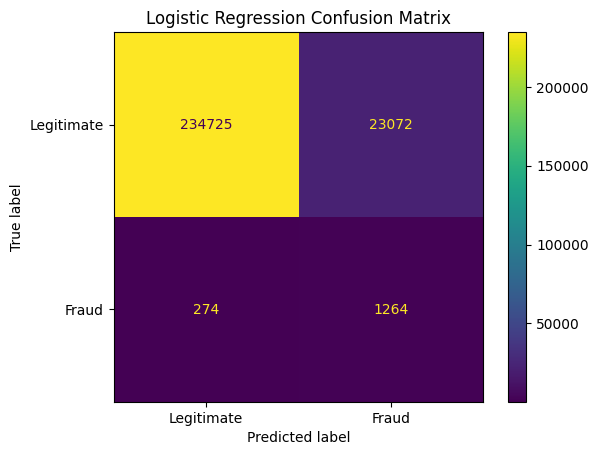

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot()

plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [ ]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 234725
False Positives: 23072
False Negatives: 274
True Positives: 1264


In [ ]:
fraud_detection_rate = tp / (tp + fn) * 100
false_alarm_rate = fp / (fp + tn) * 100

print("Fraud Detection Rate:", round(fraud_detection_rate, 2), "%")
print("False Alarm Rate:", round(false_alarm_rate, 2), "%")

Fraud Detection Rate: 82.18 %
False Alarm Rate: 8.95 %


#### 9.1.2 Classification Threshold Analysis

The default Logistic Regression classification threshold is 0.50.

Different probability thresholds are evaluated to understand the trade-off between
fraud recall and precision. Lower thresholds generally detect more fraud but may
increase false positives, while higher thresholds may improve precision at the
cost of missing more fraudulent transactions.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_pred_threshold = (
        y_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_threshold
    )

    recall = recall_score(
        y_val,
        y_pred_threshold
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold
    )

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.3 | Precision: 0.0193 | Recall: 0.8804 | F1: 0.0378
Threshold: 0.4 | Precision: 0.0297 | Recall: 0.8446 | F1: 0.0573
Threshold: 0.5 | Precision: 0.0519 | Recall: 0.8218 | F1: 0.0977
Threshold: 0.6 | Precision: 0.0868 | Recall: 0.7919 | F1: 0.1564
Threshold: 0.7 | Precision: 0.1483 | Recall: 0.7607 | F1: 0.2481


In [ ]:
thresholds = [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9]

for threshold in thresholds:

    y_pred_threshold = (
        y_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_threshold
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.50 | Precision: 0.0519 | Recall: 0.8218 | F1: 0.0977
Threshold: 0.60 | Precision: 0.0868 | Recall: 0.7919 | F1: 0.1564
Threshold: 0.70 | Precision: 0.1483 | Recall: 0.7607 | F1: 0.2481
Threshold: 0.75 | Precision: 0.1867 | Recall: 0.7308 | F1: 0.2974
Threshold: 0.80 | Precision: 0.2181 | Recall: 0.6860 | F1: 0.3310
Threshold: 0.85 | Precision: 0.2443 | Recall: 0.6339 | F1: 0.3527
Threshold: 0.90 | Precision: 0.2661 | Recall: 0.5845 | F1: 0.3657


#### 9.1.3 Precision-Recall Curve

The Precision-Recall curve is used to evaluate the trade-off between fraud
precision and fraud recall across different classification thresholds.

This is particularly useful for the Fraud Shield dataset because fraudulent
transactions represent a very small percentage of all transactions.

The curve helps identify threshold regions that maintain strong fraud detection
while reducing unnecessary false-positive alerts.

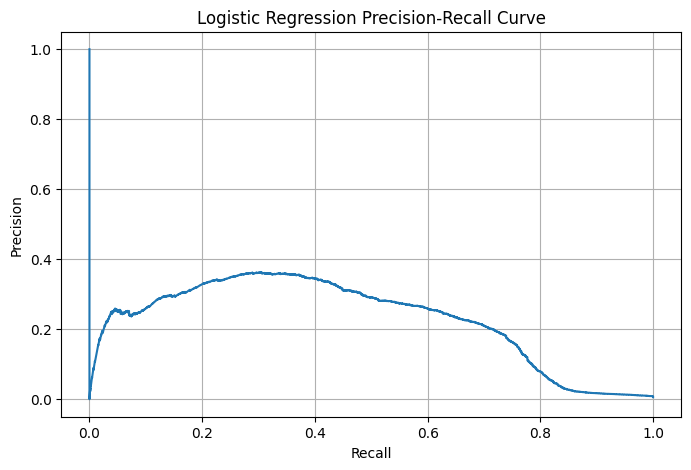

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Logistic Regression Precision-Recall Curve')

plt.grid()
plt.show()

### Logistic Regression Conclusion

Logistic Regression provided a useful baseline for the Fraud Shield classification problem.

At the default classification threshold of **0.50**, the model achieved approximately:

- **Fraud Recall:** 82.18%
- **Fraud Precision:** 5.19%
- **Fraud F1-score:** 0.0977
- **ROC-AUC:** 0.931
- **PR-AUC:** 0.225

The model demonstrated strong ability to identify fraudulent transactions, as shown by its relatively high fraud recall and ROC-AUC score. However, the low precision indicates that a large number of legitimate transactions were incorrectly flagged as fraud.

Threshold analysis showed a clear precision-recall trade-off. Increasing the classification threshold improved precision but reduced recall. For example, at a threshold of **0.70**, fraud precision increased to approximately **14.83%**, while recall remained approximately **76.07%**.

The Precision-Recall curve further confirmed that Logistic Regression cannot simultaneously maintain very high fraud recall and high precision on this highly imbalanced dataset.

Overall, Logistic Regression serves as a valuable baseline model. It is capable of detecting a substantial proportion of fraudulent transactions, but the number of false-positive alerts remains high. More advanced models such as **Random Forest and XGBoost** will therefore be evaluated to determine whether they can provide a better balance between fraud detection and false-positive reduction.

### 9.2 Random Forest Baseline

Random Forest is evaluated as the second supervised learning model.

Unlike Logistic Regression, Random Forest can capture non-linear relationships and
interactions between features. This may be useful for fraud detection because fraud
patterns can depend on combinations of transaction amount, time, customer behavior,
transaction frequency, location, and other features.

Because the dataset is highly imbalanced, class weighting is used to give greater
importance to fraudulent transactions.

The model will be evaluated using precision, recall, F1-score, ROC-AUC, PR-AUC,
and the confusion matrix.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

n_estimators=100
→ Build 100 decision trees

max_depth=15
→ Each tree can grow up to 15 levels
→ Helps control overfitting

min_samples_leaf=5
→ A final leaf must contain at least 5 transactions
→ Prevents extremely specific rules

class_weight='balanced_subsample'
→ Gives more importance to the rare fraud class

random_state=42
→ Makes results reproducible

n_jobs=-1
→ Uses all available CPU cores

Logistic Regression
→ OneHotEncoder + StandardScaler

Random Forest / XGBoost
→ OneHotEncoder only
→ numerical features passed through without scaling

In [ ]:


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'num',
            'passthrough',
            numerical_features
        ),
        (
            'binary',
            'passthrough',
            binary_features
        )
    ]
)

In [ ]:
X_train_tree = tree_preprocessor.fit_transform(X_train)

X_val_tree = tree_preprocessor.transform(X_val)

X_test_tree = tree_preprocessor.transform(X_test)

In [ ]:
rf_model.fit(
    X_train_tree,
    y_train
)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=15,
                       min_samples_leaf=5, n_jobs=-1, random_state=42)

In [ ]:
rf_val_pred = rf_model.predict(X_val_tree)

rf_val_prob = rf_model.predict_proba(X_val_tree)[:, 1]

rf_val_prob
→ probability of fraud
→ values like 0.08, 0.61, 0.94

rf_val_pred
→ final class prediction
→ 0 = legitimate
→ 1 = fraud

In [ ]:
# Evaluation

from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

print(
    classification_report(
        y_val,
        rf_val_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_val, rf_val_prob)
)

print(
    "PR-AUC:",
    average_precision_score(y_val, rf_val_prob)
)

              precision    recall  f1-score   support

           0     0.9995    0.9927    0.9961    257797
           1     0.4287    0.9155    0.5840      1538

    accuracy                         0.9923    259335
   macro avg     0.7141    0.9541    0.7900    259335
weighted avg     0.9961    0.9923    0.9937    259335

ROC-AUC: 0.9956331075166334
PR-AUC: 0.8385802842066843


#### Random Forest Validation Performance

The trained Random Forest model is evaluated on the chronological validation
dataset.

Both class predictions and fraud probabilities are generated. Model performance
is measured using precision, recall, F1-score, ROC-AUC, and PR-AUC.

The results will be compared with the Logistic Regression baseline to determine
whether Random Forest provides a better balance between fraud detection and
false-positive alerts.

#### Random Forest Baseline - Observation

Random Forest significantly outperformed the Logistic Regression baseline on the
chronological validation dataset.

At the default classification threshold, Random Forest achieved approximately
**91.55% fraud recall** and **42.87% fraud precision**, indicating that the model
detects a high proportion of fraudulent transactions while generating substantially
fewer false-positive alerts than Logistic Regression.

The fraud F1-score improved to approximately **0.584**, compared with approximately
0.098 for Logistic Regression.

Random Forest also achieved a **ROC-AUC of approximately 0.996** and a **PR-AUC of
approximately 0.839**, demonstrating strong ability to distinguish fraudulent
transactions in this highly imbalanced dataset.

Overall, Random Forest provides a substantially better balance between fraud
detection and false-positive reduction than the Logistic Regression baseline.

### Confusion Matrix

True Positives  → fraud caught
False Negatives → fraud missed
False Positives → legitimate transactions falsely flagged
True Negatives  → legitimate transactions correctly accepted

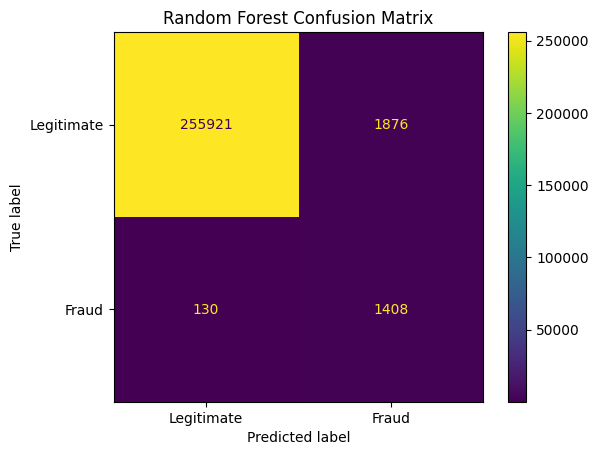

True Negatives : 255921
False Positives: 1876
False Negatives: 130
True Positives : 1408


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf_cm = confusion_matrix(y_val, rf_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot()
plt.title('Random Forest Confusion Matrix')
plt.show()

tn, fp, fn, tp = rf_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

#### Random Forest Confusion Matrix Observation

The Random Forest model correctly identified **1,408 fraudulent transactions**
while missing only **130 fraud cases**, resulting in fraud recall of approximately
**91.55%**.

The model incorrectly flagged **1,876 legitimate transactions** as fraudulent,
while correctly classifying **255,921 legitimate transactions**.

This corresponds to a fraud precision of approximately **42.87%** and a false-positive
rate of approximately **0.73%** among legitimate transactions.

Compared with Logistic Regression, Random Forest provides a substantially better
balance between detecting fraudulent transactions and reducing unnecessary fraud alerts.

#### 9.2.1 Random Forest Threshold Analysis

The default Random Forest classification threshold is 0.50.

Different probability thresholds are evaluated to determine whether precision can
be improved while maintaining strong fraud recall.

Because the Random Forest baseline already achieves high recall, the objective is
to reduce false-positive alerts without causing a large reduction in fraud detection.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for threshold in rf_thresholds:

    rf_pred_threshold = (
        rf_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        rf_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        rf_pred_threshold
    )

    f1 = f1_score(
        y_val,
        rf_pred_threshold
    )

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.3 | Precision: 0.1829 | Recall: 0.9668 | F1: 0.3077
Threshold: 0.4 | Precision: 0.2861 | Recall: 0.9395 | F1: 0.4386
Threshold: 0.5 | Precision: 0.4287 | Recall: 0.9155 | F1: 0.5840
Threshold: 0.6 | Precision: 0.5611 | Recall: 0.8752 | F1: 0.6838
Threshold: 0.7 | Precision: 0.6684 | Recall: 0.8127 | F1: 0.7336
Threshold: 0.8 | Precision: 0.7841 | Recall: 0.7204 | F1: 0.7509
Threshold: 0.9 | Precision: 0.9503 | Recall: 0.5475 | F1: 0.6947


#### Random Forest Threshold Analysis - Observation

Random Forest demonstrates a clear precision-recall trade-off as the classification
threshold is increased.

At the default threshold of 0.50, the model achieves approximately **91.55% recall**
and **42.87% precision**.

Increasing the threshold improves precision while reducing recall. At a threshold
of **0.70**, the model achieves approximately **66.84% precision** while maintaining
approximately **81.27% fraud recall**, providing a strong balance between fraud
detection and false-positive reduction.

Although a threshold of 0.80 produces the highest F1-score among the tested
thresholds, recall decreases to approximately 72%. Because fraud detection places
greater importance on identifying fraudulent transactions, a threshold around
0.70 is retained as a working operating point for the Random Forest model.

The final operating threshold will be selected after comparing Random Forest with
the remaining models.

#### 9.2.2 Random Forest Precision-Recall Curve

The Precision-Recall curve is used to evaluate the trade-off between fraud
precision and fraud recall across all possible classification thresholds.

This visualization is especially useful for the highly imbalanced Fraud Shield
dataset because it shows how well the model maintains precision as fraud recall
increases.

A stronger Precision-Recall curve indicates that the model can detect more fraud
while generating fewer false-positive alerts.

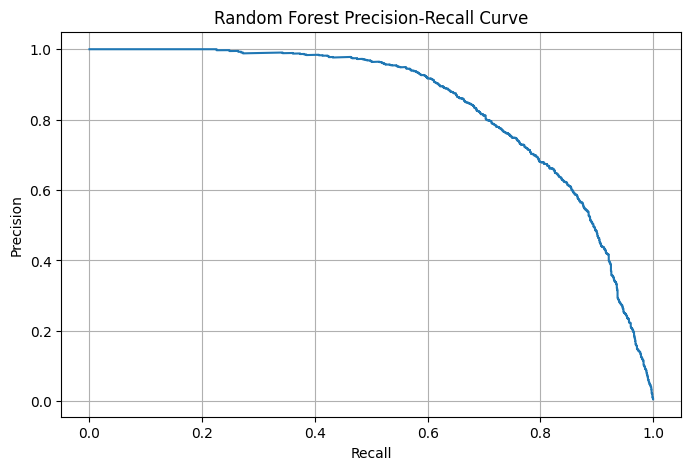

In [ ]:
from sklearn.metrics import precision_recall_curve

rf_precision, rf_recall, rf_thresholds_curve = precision_recall_curve(
    y_val,
    rf_val_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    rf_recall,
    rf_precision
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Random Forest Precision-Recall Curve')

plt.grid()
plt.show()

### Random Forest Conclusion

Random Forest substantially outperformed the Logistic Regression baseline.

At the default threshold of 0.50, the model achieved approximately **91.55% fraud
recall**, **42.87% precision**, and a fraud F1-score of approximately **0.584**.

The model also achieved a **ROC-AUC of approximately 0.996** and a **PR-AUC of
approximately 0.839**, indicating strong discrimination between fraudulent and
legitimate transactions.

Threshold analysis demonstrated that precision can be significantly improved while
maintaining relatively high recall. At a working threshold of approximately **0.70**,
the model achieved around **66.84% precision** and **81.27% recall**.

Overall, Random Forest provides a much stronger balance between detecting fraud and
reducing false-positive alerts compared with Logistic Regression.

The model will next be compared with XGBoost to determine whether further improvement
in fraud detection performance can be achieved.

### 9.3 XGBoost Baseline

XGBoost is evaluated as the third supervised learning model for fraud detection.

XGBoost is a gradient boosting algorithm that builds decision trees sequentially.
Each new tree focuses on correcting errors made by the previous trees.

Unlike Logistic Regression, XGBoost can capture complex non-linear relationships
and feature interactions. Similar to Random Forest, numerical feature scaling is
not required.

Because the Fraud Shield dataset is highly imbalanced, `scale_pos_weight` is used
to give greater importance to the minority fraud class.

The model is evaluated using precision, recall, F1-score, ROC-AUC, PR-AUC, and
the confusion matrix.

### Calculate Imbalance Weight



In [ ]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate transactions:", negative_count)
print("Fraud transactions:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Legitimate transactions: 1031372
Fraud transactions: 5968
Scale Pos Weight: 172.8170241286863


There are many more legitimate transactions than fraud transactions
                         ↓
XGBoost could ignore fraud
                         ↓
scale_pos_weight gives fraud more importance

### Create XGBoost model

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

n_estimators=200
→ Build up to 200 boosting trees

max_depth=6
→ Maximum depth of each tree

learning_rate=0.1
→ Controls how strongly each new tree corrects previous errors

subsample=0.8
→ Each tree uses 80% of training rows

colsample_bytree=0.8
→ Each tree uses 80% of available features

scale_pos_weight
→ Gives fraud transactions more importance

tree_method='hist'
→ Faster training, especially useful for your 1M+ row dataset

In [ ]:
xgb_model.fit(
    X_train_tree,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

Logistic Regression
→ X_train_processed
→ encoded + scaled

Random Forest
→ X_train_tree
→ encoded, not scaled

XGBoost
→ X_train_tree
→ encoded, not scaled

In [ ]:
# Predict on Validation data

xgb_val_pred = xgb_model.predict(X_val_tree)

xgb_val_prob = xgb_model.predict_proba(
    X_val_tree
)[:, 1]

In [ ]:
# Evaluate

from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

print(
    classification_report(
        y_val,
        xgb_val_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_val, xgb_val_prob)
)

print(
    "PR-AUC:",
    average_precision_score(y_val, xgb_val_prob)
)

              precision    recall  f1-score   support

           0     0.9998    0.9934    0.9965    257797
           1     0.4630    0.9610    0.6249      1538

    accuracy                         0.9932    259335
   macro avg     0.7314    0.9772    0.8107    259335
weighted avg     0.9966    0.9932    0.9943    259335

ROC-AUC: 0.9987695129704401
PR-AUC: 0.9280187821808282


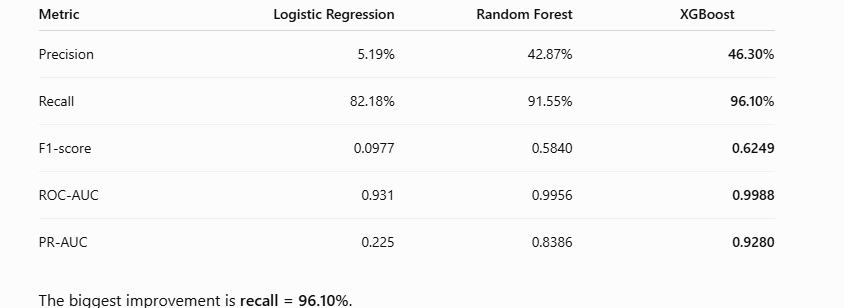

#### XGBoost Baseline - Observation

XGBoost produced the strongest baseline performance among the supervised models
evaluated so far.

At the default classification threshold of 0.50, the model achieved approximately
**96.10% fraud recall** and **46.30% fraud precision**, indicating that it detects
the vast majority of fraudulent transactions while maintaining substantially better
precision than Logistic Regression.

The fraud F1-score reached approximately **0.625**, exceeding both Logistic
Regression and Random Forest.

XGBoost also achieved a **ROC-AUC of approximately 0.999** and a **PR-AUC of
approximately 0.928**, demonstrating excellent discrimination between fraudulent
and legitimate transactions on the chronological validation dataset.

Overall, XGBoost currently provides the strongest fraud-detection performance among
the evaluated supervised models.

### XGBoost confusion matrix

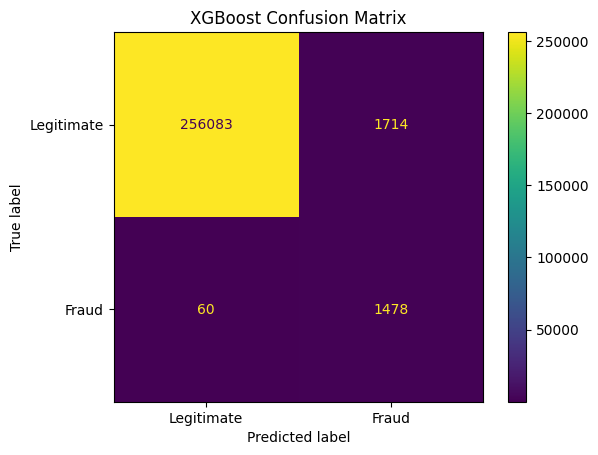

True Negatives : 256083
False Positives: 1714
False Negatives: 60
True Positives : 1478


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

xgb_cm = confusion_matrix(y_val, xgb_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot()
plt.title('XGBoost Confusion Matrix')
plt.show()

tn, fp, fn, tp = xgb_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

#### XGBoost Confusion Matrix Observation

The XGBoost model correctly detected **1,478 fraudulent transactions** and missed
only **60 fraud cases**, resulting in fraud recall of approximately **96.10%**.

The model incorrectly flagged **1,714 legitimate transactions** as fraudulent,
while correctly classifying **256,083 legitimate transactions**.

This corresponds to fraud precision of approximately **46.30%** and a false-positive
rate of approximately **0.66%** among legitimate transactions.

Compared with Random Forest, XGBoost detected more fraudulent transactions while
also generating fewer false-positive alerts, demonstrating stronger validation
performance at the default classification threshold.

### XGBoost threshold analysis

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

xgb_thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for threshold in xgb_thresholds:

    xgb_pred_threshold = (
        xgb_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        xgb_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        xgb_pred_threshold
    )

    f1 = f1_score(
        y_val,
        xgb_pred_threshold
    )

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.3 | Precision: 0.3251 | Recall: 0.9792 | F1: 0.4882
Threshold: 0.4 | Precision: 0.3979 | Recall: 0.9740 | F1: 0.5650
Threshold: 0.5 | Precision: 0.4630 | Recall: 0.9610 | F1: 0.6249
Threshold: 0.6 | Precision: 0.5306 | Recall: 0.9538 | F1: 0.6818
Threshold: 0.7 | Precision: 0.5992 | Recall: 0.9369 | F1: 0.7309
Threshold: 0.8 | Precision: 0.6816 | Recall: 0.9213 | F1: 0.7835
Threshold: 0.9 | Precision: 0.8027 | Recall: 0.8836 | F1: 0.8412


#### XGBoost Threshold Analysis - Observation

XGBoost maintained strong fraud recall even as the classification threshold was
increased.

At the default threshold of 0.50, the model achieved approximately **96.10% recall**
and **46.30% precision**.

Increasing the threshold substantially improved precision while producing a
relatively modest reduction in recall. At a threshold of **0.80**, XGBoost achieved
approximately **68.16% precision** while still maintaining approximately **92.13%
fraud recall**, with an F1-score of approximately **0.784**.

At a threshold of 0.90, precision increased further to approximately **80.27%**,
although recall decreased to approximately **88.36%**.

For the Fraud Shield use case, a threshold around **0.80** is retained as a working
operating point because it maintains fraud recall above 90% while significantly
reducing false-positive alerts.

The final operating threshold will be determined after completing model comparison
and final evaluation.

#### 9.3.2 XGBoost Precision-Recall Curve

The Precision-Recall curve is used to evaluate how XGBoost balances fraud precision
and fraud recall across different classification thresholds.

Because the dataset is highly imbalanced, this curve provides a more informative
view of minority-class performance than accuracy alone.

A stronger curve indicates that the model can maintain high fraud detection while
keeping false-positive alerts relatively low.

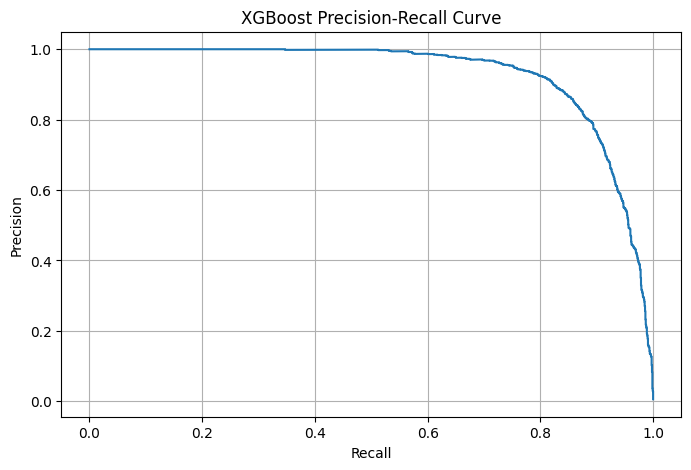

In [ ]:
from sklearn.metrics import precision_recall_curve

xgb_precision, xgb_recall, xgb_thresholds_curve = precision_recall_curve(
    y_val,
    xgb_val_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    xgb_recall,
    xgb_precision
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('XGBoost Precision-Recall Curve')

plt.grid()
plt.show()

### XGBoost Conclusion

XGBoost produced the strongest validation performance among the supervised models
evaluated.

At the default threshold of 0.50, XGBoost achieved approximately **96.10% fraud
recall**, **46.30% precision**, and an F1-score of approximately **0.625**.

Threshold tuning further improved the precision-recall balance. At a working
threshold of approximately **0.80**, the model achieved around **68.16% precision**
while maintaining approximately **92.13% fraud recall**.

The model also achieved a ROC-AUC of approximately **0.999** and a PR-AUC of
approximately **0.928**, indicating very strong fraud discrimination on the
chronological validation dataset.

Overall, XGBoost currently provides the strongest balance between fraud detection
and false-positive reduction among the supervised models evaluated.

## 10. Supervised Model Comparison

Logistic Regression, Random Forest, and XGBoost are compared using the same
chronological validation dataset.

The models are first compared at the default classification threshold of 0.50
using fraud precision, fraud recall, F1-score, ROC-AUC, and PR-AUC.

Because the dataset is highly imbalanced, greater emphasis is placed on recall,
precision, F1-score, and PR-AUC rather than overall accuracy.

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Precision': [
        precision_score(y_val, y_val_pred),
        precision_score(y_val, rf_val_pred),
        precision_score(y_val, xgb_val_pred)
    ],

    'Recall': [
        recall_score(y_val, y_val_pred),
        recall_score(y_val, rf_val_pred),
        recall_score(y_val, xgb_val_pred)
    ],

    'F1 Score': [
        f1_score(y_val, y_val_pred),
        f1_score(y_val, rf_val_pred),
        f1_score(y_val, xgb_val_pred)
    ],

    'ROC-AUC': [
        roc_auc_score(y_val, y_val_prob),
        roc_auc_score(y_val, rf_val_prob),
        roc_auc_score(y_val, xgb_val_prob)
    ],

    'PR-AUC': [
        average_precision_score(y_val, y_val_prob),
        average_precision_score(y_val, rf_val_prob),
        average_precision_score(y_val, xgb_val_prob)
    ]
})

model_comparison.round(4)

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.0519,0.8218,0.0977,0.9311,0.2247
1,Random Forest,0.4287,0.9155,0.5840,0.9956,0.8386
2,XGBoost,0.4630,0.9610,0.6249,0.9988,0.9280


Logistic Regression
        ↓
Good recall, but very poor precision

Random Forest
        ↓
Huge improvement in both recall and precision

XGBoost
        ↓
Further improvement in recall, precision and PR-AUC

### Supervised Model Comparison - Observation

The supervised model comparison shows a substantial improvement when moving from
Logistic Regression to tree-based ensemble models.

Logistic Regression achieved relatively high fraud recall but very low precision,
resulting in a large number of false-positive alerts.

Random Forest significantly improved both precision and recall, demonstrating that
non-linear relationships and feature interactions are important for identifying
fraudulent transactions.

XGBoost achieved the strongest validation performance at the default threshold,
with approximately **96.10% fraud recall**, **46.30% precision**, an F1-score of
approximately **0.625**, and a PR-AUC of approximately **0.928**.

These results indicate that XGBoost currently provides the strongest predictive
performance among the supervised models evaluated. Further tuning will be performed
before final evaluation on the held-out test dataset.

### 10.2 Threshold-Tuned Model Comparison

After evaluating the models at the common default threshold of 0.50, different
classification thresholds were explored to improve the balance between fraud recall
and precision.

The following working thresholds were selected from the validation analysis:

- Logistic Regression: 0.70
- Random Forest: 0.70
- XGBoost: 0.80

These thresholds are validation-based operating points and are not yet considered
final production thresholds.

In [ ]:
lr_threshold = 0.70
rf_threshold = 0.70
xgb_threshold = 0.80

lr_pred_tuned = (y_val_prob >= lr_threshold).astype(int)
rf_pred_tuned = (rf_val_prob >= rf_threshold).astype(int)
xgb_pred_tuned = (xgb_val_prob >= xgb_threshold).astype(int)

In [ ]:
threshold_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Threshold': [
        lr_threshold,
        rf_threshold,
        xgb_threshold
    ],

    'Precision': [
        precision_score(y_val, lr_pred_tuned),
        precision_score(y_val, rf_pred_tuned),
        precision_score(y_val, xgb_pred_tuned)
    ],

    'Recall': [
        recall_score(y_val, lr_pred_tuned),
        recall_score(y_val, rf_pred_tuned),
        recall_score(y_val, xgb_pred_tuned)
    ],

    'F1 Score': [
        f1_score(y_val, lr_pred_tuned),
        f1_score(y_val, rf_pred_tuned),
        f1_score(y_val, xgb_pred_tuned)
    ]
})

threshold_comparison.round(4)

,Model,Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.7,0.1483,0.7607,0.2481
1,Random Forest,0.7,0.6684,0.8127,0.7336
2,XGBoost,0.8,0.6816,0.9213,0.7835


#### Threshold-Tuned Comparison - Observation

Threshold tuning improved the operational precision-recall balance of all three
models.

Logistic Regression improved in precision but continued to generate considerably
more false-positive alerts than the tree-based models.

Random Forest achieved a much stronger balance at a threshold of 0.70, with
approximately 66.84% precision and 81.27% recall.

XGBoost maintained the strongest performance at a working threshold of 0.80,
achieving approximately **68.16% precision**, **92.13% recall**, and an F1-score
of approximately **0.784**.

These results indicate that XGBoost can maintain very high fraud detection while
substantially reducing false-positive alerts compared with the other supervised
models.

## 11. XGBoost Hyperparameter Tuning

XGBoost produced the strongest validation performance among the supervised models.

Hyperparameter tuning is therefore performed to determine whether its performance
can be further improved.

Because the dataset contains more than one million transactions, RandomizedSearchCV
is used instead of an exhaustive GridSearchCV to reduce computational cost.

The tuning process focuses on PR-AUC (`average_precision`) because the fraud class
is highly imbalanced and the objective is to maintain strong fraud detection while
reducing false-positive alerts.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

In [ ]:
tree_preprocessor_tuning = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'num',
            'passthrough',
            numerical_features
        ),
        (
            'binary',
            'passthrough',
            binary_features
        )
    ]
)

In [ ]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate:", negative_count)
print("Fraud:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Legitimate: 1031372
Fraud: 5968
Scale Pos Weight: 172.8170241286863


In [ ]:
xgb_tune_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

In [ ]:
xgb_pipeline = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor_tuning),
        ('model', xgb_tune_model)
    ]
)

In [ ]:
param_dist = {
    'model__n_estimators': [150, 200, 300],
    'model__max_depth': [4, 6, 8],
    'model__learning_rate': [0.05, 0.1, 0.15],
    'model__subsample': [0.7, 0.8, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5]
}

In [ ]:
tscv = TimeSeriesSplit(n_splits=3)

In [ ]:
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring='average_precision',
    cv=tscv,
    random_state=42,
    verbose=2,
    n_jobs=1
)

In [ ]:
random_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.15, model__max_depth=8, model__min_child_weight=3, model__n_estimators=150, model__subsample=0.7; total time=   8.5s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.15, model__max_depth=8, model__min_child_weight=3, model__n_estimators=150, model__subsample=0.7; total time=  21.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.15, model__max_depth=8, model__min_child_weight=3, model__n_estimators=150, model__subsample=0.7; total time=  26.3s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__max_depth=8, model__min_child_weight=3, model__n_estimators=200, model__subsample=0.8; total time=  16.3s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__max_depth=8, model__min_child_weight=3, model__n_estimators=200, model__subsample=0.8; total time=  24.9s
[CV] END model__colsample_bytree=0.7, model__learni

RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('cat',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               ['category',
                                                                                'gender',
                                                                                'state',
                                                                                'day_of_week']),
                                                                              ('num',
                                                                               'passthrough',
                                                                               ['amt',
                                                                                'city_pop',
                                                                                'age',
                                                                                'hour',
                                                                                'month',
                                                                                'cardholder_merchant_distance_km',...
                                                            n_estimators=None,
                                                            n_jobs=-1,
                                                            num_parallel_tree=None, ...))]),
                   n_jobs=1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.8,
                                                                    1.0],
                                        'model__learning_rate': [0.05, 0.1,
                                                                 0.15],
                                        'model__max_depth': [4, 6, 8],
                                        'model__min_child_weight': [1, 3, 5],
                                        'model__n_estimators': [150, 200, 300],
                                        'model__subsample': [0.7, 0.8, 1.0]},
                   random_state=42, scoring='average_precision', verbose=2)

In [ ]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Best Parameters:
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}

Best Cross-Validation PR-AUC:
0.9154126392376843


In [ ]:
best_xgb_model = random_search.best_estimator_

In [ ]:
tuned_xgb_val_pred = best_xgb_model.predict(X_val)

tuned_xgb_val_prob = best_xgb_model.predict_proba(X_val)[:, 1]

In [ ]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

print(
    classification_report(
        y_val,
        tuned_xgb_val_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_val, tuned_xgb_val_prob)
)

print(
    "PR-AUC:",
    average_precision_score(y_val, tuned_xgb_val_prob)
)

              precision    recall  f1-score   support

           0     0.9998    0.9939    0.9969    257797
           1     0.4870    0.9655    0.6475      1538

    accuracy                         0.9938    259335
   macro avg     0.7434    0.9797    0.8222    259335
weighted avg     0.9968    0.9938    0.9948    259335

ROC-AUC: 0.9990562162616907
PR-AUC: 0.943039064087016


### XGBoost Hyperparameter Tuning - Observation

Hyperparameter tuning improved the validation performance of the XGBoost model.

The tuned XGBoost model achieved approximately **96.55% fraud recall** and
**48.70% fraud precision**, compared with 96.10% recall and 46.30% precision
for the original XGBoost model.

The fraud F1-score improved from approximately **0.625 to 0.648**, while PR-AUC
increased from approximately **0.928 to 0.943**.

The ROC-AUC also remained extremely strong at approximately **0.999**.

Overall, hyperparameter tuning produced a measurable improvement in the model's
ability to detect fraudulent transactions while reducing false-positive alerts.
The tuned XGBoost model will therefore be used as the final supervised model
candidate.

In [ ]:
tuned_thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]

for threshold in tuned_thresholds:

    tuned_pred_threshold = (
        tuned_xgb_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        tuned_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        tuned_pred_threshold
    )

    f1 = f1_score(
        y_val,
        tuned_pred_threshold
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

### Final Threshold Selection for Tuned XGBoost

Threshold analysis was repeated after XGBoost hyperparameter tuning.

Increasing the classification threshold continued to improve precision while
gradually reducing fraud recall.

A threshold of **0.85** was selected as the final working threshold because it
maintains fraud recall above 90% while achieving substantially higher precision.

At this threshold, the tuned XGBoost model achieved approximately:

- **Precision:** 78.28%
- **Recall:** 91.61%
- **F1-score:** 0.844

This represents a strong operational balance: the model detects more than 90% of
fraudulent transactions while approximately 78% of generated fraud alerts correspond
to actual fraud.

Although higher thresholds produced higher precision and F1-score, they resulted
in a larger reduction in fraud recall. Therefore, the 0.85 threshold was selected
to remain aligned with the project's emphasis on fraud detection.

In [ ]:
final_threshold = 0.85

test_prob = best_xgb_model.predict_proba(X_test)[:, 1]

test_pred = (
    test_prob >= final_threshold
).astype(int)

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

y_test = test_df['is_fraud']

print(
    classification_report(
        y_test,
        test_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, test_prob)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, test_prob)
)

print(
    "Confusion Matrix:\n",
    confusion_matrix(y_test, test_pred)
)

## 12. Final Test Evaluation

The final tuned XGBoost model was evaluated on the previously untouched test
dataset using the selected classification threshold of **0.85**.

The model achieved:

- **Fraud Precision:** 71.22%
- **Fraud Recall:** 88.72%
- **Fraud F1-score:** 0.790
- **ROC-AUC:** 0.998
- **PR-AUC:** 0.906
- **Overall Accuracy:** 99.82%

The confusion matrix showed that the model correctly detected **1,903 fraudulent
transactions** while missing **242 fraud cases**. It also incorrectly flagged
**769 legitimate transactions** as fraudulent while correctly classifying
**552,805 legitimate transactions**.

The final model therefore detects approximately **89% of actual fraud**, while
approximately **71% of generated fraud alerts correspond to genuine fraud**.

Performance on the unseen test dataset was slightly lower than validation
performance, which is expected when evaluating on future unseen transactions.
However, the model maintained strong precision, recall, PR-AUC, and ROC-AUC,
indicating that the tuned XGBoost model generalizes well to later transaction data.

Overall, the final XGBoost model provides a strong balance between detecting
fraudulent transactions and minimizing false-positive alerts.

## 13. Deep Learning Models

After completing the supervised machine-learning models, deep-learning approaches
are evaluated to determine whether more complex non-linear relationships can further
improve fraud detection.

Two deep-learning architectures are evaluated:

1. Feedforward Neural Network (FNN)
2. Long Short-Term Memory Network (LSTM)

The Feedforward Neural Network is evaluated first using the engineered transaction
features. The LSTM will later be used to model sequential transaction behavior.

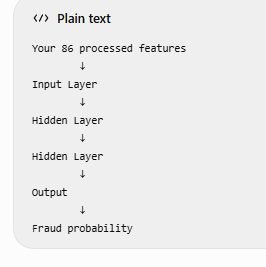

### 13.1 Feedforward Neural Network (FNN)

A Feedforward Neural Network (FNN) is used to model complex non-linear relationships
between transaction features and fraud outcomes.

The model receives the preprocessed transaction features as input and passes them
through multiple fully connected hidden layers.

Because fraud detection is a binary classification problem:

- 0 = Legitimate
- 1 = Fraud

the final output layer uses a sigmoid activation function to produce a fraud
probability between 0 and 1.

Numerical features are scaled and categorical features are one-hot encoded before
being provided to the neural network.

###Use the scaled/encoded data

In [ ]:
# for FNN

X_train_processed
X_val_processed
X_test_processed

# because neural networks benefit from scaled numerical features.

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Test shape:", X_test_processed.shape)

###Import TensorFlow/Keras

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print(tf.__version__)

2.21.0


### Calculate class weights

In [ ]:
# Because fraud is very rare, we want the FNN to give more importance to fraud examples.

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = {
    0: class_weights_array[0],
    1: class_weights_array[1]
}

print(class_weights)

### Build the FNN


In [ ]:
input_size = X_train_processed.shape[1]

print("Input size:", input_size)

fnn_model = Sequential([

    Dense(
        128,
        activation='relu',
        input_shape=(input_size,)
    ),

    Dropout(0.30),

    Dense(
        64,
        activation='relu'
    ),

    Dropout(0.20),

    Dense(
        32,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )
])

In [ ]:
fnn_model.summary()


#####PARAMETERS
11,136 = 128 (neurons) * 86 (features) + 128 biases
8,256 = 64 (neurons) * 128 (outout from previous layer) + 64 biases
2080 = 32 (neurons) * 64 (output from previous layer + 32 biases +32
33 = 1 (neuron) * 32( output from previous layer) + 1 bias

######Activation Function
ReLU helps the hidden layers learn patterns. Sigmoid gives you the final fraud probability from 0 to 1.


##### Dropout

**Dropout is a technique used to reduce overfitting in a neural network.**

During training, Dropout randomly turns off some neuron outputs for each training step.

For example:

```python
Dropout(0.30)







### Compile the FNN

In [ ]:
fnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='roc_auc'),
        tf.keras.metrics.AUC(
            curve='PR',
            name='pr_auc'
        )
    ]
)

optimizer
→ how weights are updated

loss
→ how wrong the model is

metrics
→ how we monitor fraud performance

### Prepare the data for TensorFlow

In [ ]:
#processed features are already encoded and scaled. Convert them to float32, which is more memory-efficient for neural networks:

X_train_fnn = X_train_processed.astype('float32')
X_val_fnn = X_val_processed.astype('float32')
X_test_fnn = X_test_processed.astype('float32')

print("Train shape:", X_train_fnn.shape)
print("Validation shape:", X_val_fnn.shape)
print("Test shape:", X_test_fnn.shape)

### 13.1.1 FNN Training Preparation

The preprocessed training, validation, and test feature matrices are converted
to `float32` format before neural-network training.

The features have already been:

- One-hot encoded for categorical variables
- Standardized for numerical variables
- Passed through directly for binary variables

The validation dataset is used to monitor generalization during training, while
the test dataset remains untouched until final FNN evaluation.

### Create Early Stopping

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_pr_auc',
    mode='max',
    patience=3,
    restore_best_weights=True
)

### Early Stopping

Early stopping is used to reduce overfitting.

Validation PR-AUC is monitored because the fraud dataset is highly imbalanced.
If validation PR-AUC fails to improve for three consecutive epochs, training is
stopped.

The model weights from the epoch with the highest validation PR-AUC are restored.

### Train or Reload the FNN

This cell is safe to use with **Run all**.

- `TRAIN_FNN = False` → load the saved FNN and skip expensive training.
- `TRAIN_FNN = True` → retrain the FNN and overwrite the saved model.
- If no saved FNN exists yet, the notebook automatically trains it once and saves it.

For normal future runs, keep `TRAIN_FNN = False`.


In [ ]:
# FNN RUN-ALL SWITCH
TRAIN_FNN = False

import os
import json
import joblib
import tensorflow as tf

MODEL_DIR = '/content/drive/MyDrive/FraudShield/models'
os.makedirs(MODEL_DIR, exist_ok=True)

FNN_MODEL_PATH = f'{MODEL_DIR}/fraudshield_fnn.keras'
FNN_PREPROCESSOR_PATH = f'{MODEL_DIR}/fraudshield_preprocessor.pkl'
FNN_THRESHOLD_PATH = f'{MODEL_DIR}/fnn_config.json'

if TRAIN_FNN or not os.path.exists(FNN_MODEL_PATH):

    if os.path.exists(FNN_MODEL_PATH):
        print("TRAIN_FNN=True — retraining FNN...")
    else:
        print("No saved FNN found — training once and saving it...")

    history = fnn_model.fit(
        X_train_fnn,
        y_train,
        validation_data=(X_val_fnn, y_val),
        epochs=20,
        batch_size=2048,
        class_weight=class_weights,
        callbacks=[early_stopping],
        verbose=1
    )

    fnn_model.save(FNN_MODEL_PATH)
    joblib.dump(preprocessor, FNN_PREPROCESSOR_PATH)

    print("FNN training complete and model saved.")
    print("Model:", FNN_MODEL_PATH)

else:

    print("Saved FNN found — skipping training.")

    fnn_model = tf.keras.models.load_model(FNN_MODEL_PATH)

    if os.path.exists(FNN_PREPROCESSOR_PATH):
        preprocessor = joblib.load(FNN_PREPROCESSOR_PATH)

    if os.path.exists(FNN_THRESHOLD_PATH):
        with open(FNN_THRESHOLD_PATH, 'r') as f:
            fnn_config = json.load(f)

        final_fnn_threshold = fnn_config['threshold']
        print("Saved FNN loaded successfully.")
        print("Saved threshold:", final_fnn_threshold)
    else:
        print("Saved FNN loaded successfully.")
        print("No saved threshold found yet.")


Saved FNN found — skipping training.
Saved FNN loaded successfully.
Saved threshold: 0.85598856


X_train_fnn
→ the 86 input features

y_train
→ correct answer: 0 or 1

validation_data
→ evaluates the model after every epoch

epochs=20
→ maximum of 20 complete passes through the training dataset

batch_size=2048
→ process 2,048 transactions at a time before updating weights

class_weight
→ make fraud errors more important

callbacks=[early_stopping]
→ stop when validation performance stops improving

Epoch = one full pass through all training data. Batch = one small chunk of that data. Weights are usually updated after each batch, not just once per epoch.

#### FNN Training Observation

The FNN showed substantial improvement during the first several training epochs.

Validation PR-AUC increased from approximately **0.394 in epoch 1** to a maximum
of approximately **0.830 in epoch 5**, indicating that the model was learning
meaningful fraud patterns.

After epoch 5, training performance continued to improve, while validation PR-AUC
declined. This suggests that the model was beginning to overfit the training data.

Because EarlyStopping monitored validation PR-AUC with a patience of three epochs,
training stopped after three consecutive epochs without improvement and restored
the model weights from the best-performing epoch.

At the best epoch, the model achieved approximately **92.98% validation recall**
and **19.03% validation precision** at the default classification threshold.

Further threshold analysis will be performed to determine whether precision can
be improved while maintaining strong fraud recall.

### Why PR-AUC Was Monitored During FNN Training

During FNN training, `val_pr_auc` was used as the main metric for Early Stopping because the fraud dataset is highly imbalanced and both precision and recall are important.

Precision and recall shown during training are calculated at a specific classification threshold, usually around **0.50**.

For example:

- Precision tells us how many fraud alerts were actually fraud.
- Recall tells us how many real fraud cases were detected.

However, these values can change significantly when the classification threshold changes.

For the same trained model:

Threshold 0.50  
→ Higher recall, lower precision

Threshold 0.80  
→ Higher precision, lower recall

Therefore, using only precision or only recall during training could favor one side of the trade-off.

PR-AUC evaluates the model's precision-recall performance across many possible thresholds rather than relying on a single cutoff.

This makes PR-AUC especially useful for selecting the best-performing FNN epoch in a highly imbalanced fraud-detection problem.

The modeling strategy is therefore:

Training Stage  
→ Monitor `val_pr_auc`  
→ Select the epoch with the strongest overall precision-recall performance

After Training  
→ Generate fraud probabilities  
→ Perform threshold analysis  
→ Evaluate precision, recall, F1-score, and confusion matrix  
→ Select an operating threshold based on business requirements

In summary:

> **PR-AUC is used to select the best-trained model, while precision and recall are used afterward to determine the most appropriate fraud-alert threshold.**

### 13.1.2 FNN Validation Evaluation

After training, the FNN is evaluated on the chronological validation dataset.

The model first generates a fraud probability for every transaction. These
probabilities are converted into class predictions using the default threshold
of 0.50.

The model is evaluated using precision, recall, F1-score, ROC-AUC, PR-AUC,
and the confusion matrix.

### 13.1.2 FNN Validation Evaluation — Complete Evaluation

The trained FNN is evaluated on the chronological validation set. The model first
produces fraud probabilities, then those probabilities are converted to predictions
using a classification threshold.

The default threshold of 0.50 is evaluated first.


In [ ]:
# Validation fraud probabilities
fnn_val_prob = fnn_model.predict(
    X_val_fnn,
    batch_size=2048
).ravel()

# Default threshold
fnn_val_pred = (fnn_val_prob >= 0.50).astype(int)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)

print(classification_report(y_val, fnn_val_pred, digits=4))
print("ROC-AUC:", roc_auc_score(y_val, fnn_val_prob))
print("PR-AUC:", average_precision_score(y_val, fnn_val_prob))

fnn_cm = confusion_matrix(y_val, fnn_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=fnn_cm,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot()
plt.title('FNN Confusion Matrix - Threshold 0.50')
plt.show()

tn, fp, fn, tp = fnn_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)


#### Updated FNN Validation Observation

For the latest FNN run at the default threshold of **0.50**:

- Fraud Precision: **16.80%**
- Fraud Recall: **94.02%**
- Fraud F1-score: **0.285**
- ROC-AUC: **0.993**
- PR-AUC: **0.855**

Confusion matrix:

- True Negatives: **250,636**
- False Positives: **7,161**
- False Negatives: **92**
- True Positives: **1,446**

The FNN detects most fraud cases, but the default threshold produces many false-positive
alerts. Threshold tuning is therefore required.


### FNN Threshold Analysis


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

fnn_thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

for threshold in fnn_thresholds:

    fnn_pred_threshold = (
        fnn_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        fnn_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        fnn_pred_threshold
    )

    f1 = f1_score(
        y_val,
        fnn_pred_threshold
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )


### Select the Best FNN Threshold While Keeping Recall ≥ 90%

Rather than selecting a threshold manually, the Precision-Recall curve is used to find
the highest possible precision while maintaining fraud recall of at least 90%.


In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    fnn_val_prob
)

min_recall = 0.90

valid = recall[:-1] >= min_recall

valid_precision = precision[:-1][valid]
valid_recall = recall[:-1][valid]
valid_thresholds = thresholds[valid]

best_idx = valid_precision.argmax()

final_fnn_threshold = float(valid_thresholds[best_idx])

print("Best Threshold:", final_fnn_threshold)
print("Precision:", valid_precision[best_idx])
print("Recall:", valid_recall[best_idx])


#### Updated FNN Threshold Selection

For the latest FNN run, the validation-selected operating threshold is approximately
**0.85598856**.

At this threshold:

- Precision ≈ **42.65%**
- Recall ≈ **90.05%**

This threshold maximizes precision while maintaining the business constraint of at
least 90% validation recall.


### Save Selected FNN Threshold


In [ ]:
import json
import os

MODEL_DIR = '/content/drive/MyDrive/FraudShield/models'
os.makedirs(MODEL_DIR, exist_ok=True)

# Latest validation-selected threshold
final_fnn_threshold = 0.85598856

fnn_config = {
    'threshold': final_fnn_threshold
}

with open(
    f'{MODEL_DIR}/fnn_config.json',
    'w'
) as f:
    json.dump(fnn_config, f, indent=2)

print("FNN threshold saved:", final_fnn_threshold)


### 13.1.3 Final FNN Test Evaluation


In [ ]:
# Use the threshold selected ONLY from the validation set
final_fnn_threshold = 0.85598856

fnn_test_prob = fnn_model.predict(
    X_test_fnn,
    batch_size=2048
).ravel()

fnn_test_pred = (
    fnn_test_prob >= final_fnn_threshold
).astype(int)

y_test = test_df['is_fraud']

print(classification_report(
    y_test,
    fnn_test_pred,
    digits=4
))

print("ROC-AUC:", roc_auc_score(y_test, fnn_test_prob))
print("PR-AUC:", average_precision_score(y_test, fnn_test_prob))

fnn_test_cm = confusion_matrix(
    y_test,
    fnn_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=fnn_test_cm,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot()
plt.title(
    f'FNN Test Confusion Matrix - Threshold {final_fnn_threshold:.3f}'
)
plt.show()

tn, fp, fn, tp = fnn_test_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)


### FNN Final Test Evaluation — Latest Run

Using the validation-selected threshold of approximately **0.856**, the FNN achieved
on the untouched test set:

- Fraud Precision: **35.01%**
- Fraud Recall: **86.76%**
- Fraud F1-score: **0.499**
- ROC-AUC: **0.990**
- PR-AUC: **0.793**
- Accuracy: **99.33%**

Confusion matrix:

- True Negatives: **550,119**
- False Positives: **3,455**
- False Negatives: **284**
- True Positives: **1,861**

The FNN detects a large proportion of fraud, but false-positive alerts remain much
higher than for tuned XGBoost.


### FNN vs Tuned XGBoost — Final Test Comparison

| Metric | FNN | Tuned XGBoost |
|---|---:|---:|
| Fraud Precision | 35.01% | **71.22%** |
| Fraud Recall | 86.76% | **88.72%** |
| F1-score | 0.499 | **0.790** |
| ROC-AUC | 0.990 | **0.998** |
| PR-AUC | 0.793 | **0.906** |
| Fraud Detected | 1,861 | **1,903** |
| Fraud Missed | 284 | **242** |
| False Positives | 3,455 | **769** |

XGBoost remains the strongest model so far. It detects slightly more fraud while
producing dramatically fewer false-positive alerts.


## 14. LSTM — Sequential Fraud Detection

Long Short-Term Memory (LSTM) is used to model ordered transaction behavior.

Unlike the FNN, which primarily evaluates one transaction feature vector at a time,
the LSTM receives multiple consecutive transactions belonging to the same card.

`cc_num` is used only to group transactions into sequences and is not given to the
model as a predictive feature.


### 14.1 Select LSTM Features


In [ ]:
lstm_features = [
    'amt',
    'city_pop',
    'age',
    'hour',
    'month',
    'is_weekend',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h',
    'no_prior_history'
]

sequence_length = 5


In [ ]:
lstm_df = train_df[
    ['cc_num', 'trans_date_trans_time', 'is_fraud']
    + lstm_features
].copy()

lstm_df = lstm_df.sort_values(
    ['cc_num', 'trans_date_trans_time']
).reset_index(drop=True)

lstm_df[
    ['cc_num', 'trans_date_trans_time', 'amt', 'is_fraud']
].head(10)


,cc_num,trans_date_trans_time,amt,is_fraud
0,60416207185,2019-01-01 12:47:15,7.27,0
1,60416207185,2019-01-02 08:44:57,52.94,0
2,60416207185,2019-01-02 08:47:36,82.08,0
3,60416207185,2019-01-02 12:38:14,34.79,0
4,60416207185,2019-01-02 13:10:46,27.18,0
5,60416207185,2019-01-03 13:56:35,6.87,0
6,60416207185,2019-01-03 17:05:10,8.43,0
7,60416207185,2019-01-04 13:59:55,117.11,0
8,60416207185,2019-01-04 21:17:22,26.74,0
9,60416207185,2019-01-05 00:42:24,105.20,0


### 14.2 Scale LSTM Features Using Training-Period Statistics Only


In [ ]:
from sklearn.preprocessing import StandardScaler

train_cutoff = train_model['trans_date_trans_time'].max()

lstm_scaler = StandardScaler()

train_period_mask = (
    lstm_df['trans_date_trans_time'] <= train_cutoff
)

lstm_scaler.fit(
    lstm_df.loc[
        train_period_mask,
        lstm_features
    ]
)

lstm_scaled_df = lstm_df.copy()

lstm_scaled_df[lstm_features] = lstm_scaler.transform(
    lstm_df[lstm_features]
)

print("Training cutoff:", train_cutoff)


Training cutoff: 2020-03-06 07:15:17


### 14.3 Build 5-Transaction Sequences

Each LSTM sample contains:

**5 timesteps × 12 features**

The label belongs to the final transaction in each five-transaction sequence.


In [ ]:
train_seq_count = 0
val_seq_count = 0

for _, group in lstm_scaled_df.groupby('cc_num', sort=False):

    if len(group) < sequence_length:
        continue

    target_times = group[
        'trans_date_trans_time'
    ].to_numpy()[sequence_length - 1:]

    train_seq_count += (
        target_times <= np.datetime64(train_cutoff)
    ).sum()

    val_seq_count += (
        target_times > np.datetime64(train_cutoff)
    ).sum()

print("Training sequences:", train_seq_count)
print("Validation sequences:", val_seq_count)


Training sequences: 1033484
Validation sequences: 259259


In [ ]:
n_lstm_features = len(lstm_features)

X_lstm_train = np.empty(
    (train_seq_count, sequence_length, n_lstm_features),
    dtype=np.float32
)

y_lstm_train = np.empty(
    train_seq_count,
    dtype=np.int8
)

X_lstm_val = np.empty(
    (val_seq_count, sequence_length, n_lstm_features),
    dtype=np.float32
)

y_lstm_val = np.empty(
    val_seq_count,
    dtype=np.int8
)

train_idx = 0
val_idx = 0

for _, group in lstm_scaled_df.groupby('cc_num', sort=False):

    if len(group) < sequence_length:
        continue

    feature_values = group[
        lstm_features
    ].to_numpy(dtype=np.float32)

    labels = group[
        'is_fraud'
    ].to_numpy()

    times = group[
        'trans_date_trans_time'
    ].to_numpy()

    for i in range(sequence_length - 1, len(group)):

        sequence = feature_values[
            i - sequence_length + 1 : i + 1
        ]

        target = labels[i]
        target_time = times[i]

        if target_time <= np.datetime64(train_cutoff):
            X_lstm_train[train_idx] = sequence
            y_lstm_train[train_idx] = target
            train_idx += 1
        else:
            X_lstm_val[val_idx] = sequence
            y_lstm_val[val_idx] = target
            val_idx += 1

print("X_lstm_train:", X_lstm_train.shape)
print("y_lstm_train:", y_lstm_train.shape)
print("X_lstm_val:", X_lstm_val.shape)
print("y_lstm_val:", y_lstm_val.shape)


X_lstm_train: (1033484, 5, 12)
y_lstm_train: (1033484,)
X_lstm_val: (259259, 5, 12)
y_lstm_val: (259259,)


The current sequence creation produced:

- `X_lstm_train`: **(1,033,484, 5, 12)**
- `y_lstm_train`: **(1,033,484,)**
- `X_lstm_val`: **(259,259, 5, 12)**
- `y_lstm_val`: **(259,259,)**

Meaning each LSTM sample contains five transactions and twelve features per transaction.


### Inspect One LSTM Sequence


In [ ]:
sequence_preview = pd.DataFrame(
    X_lstm_train[0],
    columns=lstm_features
)

display(sequence_preview)

print("One sequence shape:", X_lstm_train[0].shape)
print("Target label:", y_lstm_train[0])


,amt,city_pop,age,hour,month,is_weekend,cardholder_merchant_distance_km,time_since_prev_txn_min,customer_prev_avg_amt,amt_ratio_to_prev_avg,txn_count_prev_1h,no_prior_history
0,-0.393042,-0.289013,-0.769956,-0.117991,-1.513136,-0.75334,1.769136,-0.332974,-0.249257,-0.132085,-0.413153,32.788395
1,-0.108264,-0.289013,-0.769956,-0.704586,-1.513136,-0.75334,1.175009,0.825332,-2.938725,2.316358,-0.413153,-0.030499
2,0.073441,-0.289013,-0.769956,-0.704586,-1.513136,-0.75334,-1.865528,-0.676494,-1.875733,0.630087,1.731657,-0.030499
3,-0.221439,-0.289013,-0.769956,-0.117991,-1.513136,-0.75334,0.381410,-0.389986,-1.069237,-0.107625,-0.413153,-0.030499
4,-0.268892,-0.289013,-0.769956,0.028658,-1.513136,-0.75334,-0.064813,-0.638940,-1.216338,-0.151874,1.731657,-0.030499


One sequence shape: (5, 12)
Target label: 0


### 14.4 LSTM Model Architecture


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([

    LSTM(
        64,
        input_shape=(
            sequence_length,
            len(lstm_features)
        )
    ),

    Dropout(0.30),

    Dense(
        32,
        activation='relu'
    ),

    Dropout(0.20),

    Dense(
        1,
        activation='sigmoid'
    )
])

lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,825 (85.25 KB)

 Trainable params: 21,825 (85.25 KB)

 Non-trainable params: 0 (0.00 B)

### LSTM Parameter Calculation

For `LSTM(64, input_shape=(5, 12))`:

**Input weights**

12 features × 64 units = **768**

**Recurrent weights**

64 previous hidden-state values × 64 current units = **4,096**

**Biases**

64

Parameters for one gate:

768 + 4,096 + 64 = **4,928**

An LSTM has four internal gate/memory calculations:

4,928 × 4 = **19,712 LSTM parameters**

Then:

- Dense(32): `64 × 32 + 32 = 2,080`
- Dense(1): `32 × 1 + 1 = 33`
- Dropout layers: `0`

**Total parameters = 19,712 + 2,080 + 33 = 21,825**


### 14.5 LSTM Class Weights, Compilation, and Training


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

lstm_classes = np.array([0, 1])

lstm_class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=lstm_classes,
    y=y_lstm_train
)

lstm_class_weights = {
    0: lstm_class_weights_array[0],
    1: lstm_class_weights_array[1]
}

print(lstm_class_weights)


{0: np.float64(0.5027910565538016), 1: np.float64(90.07181453721458)}


In [ ]:
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='roc_auc'),
        tf.keras.metrics.AUC(
            curve='PR',
            name='pr_auc'
        )
    ]
)

lstm_early_stopping = EarlyStopping(
    monitor='val_pr_auc',
    mode='max',
    patience=3,
    restore_best_weights=True
)


### Train the LSTM

This is the next expensive step. Run it when ready. The model uses batches of 1,024
five-transaction sequences and monitors validation PR-AUC for Early Stopping.


In [ ]:
lstm_history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,

    validation_data=(
        X_lstm_val,
        y_lstm_val
    ),

    epochs=15,
    batch_size=1024,

    class_weight=lstm_class_weights,

    callbacks=[lstm_early_stopping],

    shuffle=False,

    verbose=1
)


Epoch 1/15
1010/1010 ━━━━━━━━━━━━━━━━━━━━ 48s 45ms/step - loss: 0.2301 - pr_auc: 0.5916 - precision: 0.0678 - recall: 0.8998 - roc_auc: 0.9635 - val_loss: 0.1176 - val_pr_auc: 0.7391 - val_precision: 0.1318 - val_recall: 0.9337 - val_roc_auc: 0.9796
Epoch 2/15
1010/1010 ━━━━━━━━━━━━━━━━━━━━ 41s 40ms/step - loss: 0.1676 - pr_auc: 0.6855 - precision: 0.1239 - recall: 0.9280 - roc_auc: 0.9773 - val_loss: 0.1053 - val_pr_auc: 0.7648 - val_precision: 0.1577 - val_recall: 0.9391 - val_roc_auc: 0.9838
Epoch 3/15
1010/1010 ━━━━━━━━━━━━━━━━━━━━ 43s 43ms/step - loss: 0.1492 - pr_auc: 0.6947 - precision: 0.1399 - recall: 0.9345 - roc_auc: 0.9826 - val_loss: 0.0945 - val_pr_auc: 0.7848 - val_precision: 0.1833 - val_recall: 0.9446 - val_roc_auc: 0.9872
Epoch 4/15
1010/1010 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - loss: 0.1323 - pr_auc: 0.7217 - precision: 0.1545 - recall: 0.9392 - roc_auc: 0.9869 - val_loss: 0.0787 - val_pr_auc: 0.8035 - val_precision: 0.2067 - val_recall: 0.9460 - val_roc_auc: 0.9895


In [ ]:
import os
import joblib

MODEL_DIR = '/content/drive/MyDrive/FraudShield/models'
os.makedirs(MODEL_DIR, exist_ok=True)

# Save the LSTM with the best restored weights
lstm_model.save(
    f'{MODEL_DIR}/fraudshield_lstm.keras'
)

# Save the scaler used specifically for LSTM
joblib.dump(
    lstm_scaler,
    f'{MODEL_DIR}/fraudshield_lstm_scaler.pkl'
)

print("LSTM model saved successfully.")
print("LSTM scaler saved successfully.")

LSTM model saved successfully.
LSTM scaler saved successfully.


### LTSM Validation Evaluation

In [ ]:
# Creating Evaluation Probabilities

lstm_val_prob = lstm_model.predict(
    X_lstm_val,
    batch_size=1024
).ravel()

print("Number of validation predictions:", len(lstm_val_prob))
print("First 10 fraud probabilities:")
print(lstm_val_prob[:10])

254/254 ━━━━━━━━━━━━━━━━━━━━ 14s 53ms/step
Number of validation predictions: 259259
First 10 fraud probabilities:
[0.00013259 0.00015977 0.00024811 0.00719735 0.00021278 0.0034331
 0.00019523 0.00010041 0.01068733 0.00029864]


In [ ]:
# evaluate the LSTM using the default threshold of 0.50

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)

lstm_val_pred = (
    lstm_val_prob >= 0.50
).astype(int)

print(
    classification_report(
        y_lstm_val,
        lstm_val_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_lstm_val,
        lstm_val_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_lstm_val,
        lstm_val_prob
    )
)

              precision    recall  f1-score   support

           0     0.9997    0.9857    0.9927    257797
           1     0.2742    0.9528    0.4259      1462

    accuracy                         0.9855    259259
   macro avg     0.6370    0.9693    0.7093    259259
weighted avg     0.9956    0.9855    0.9895    259259

ROC-AUC: 0.9946913314602986
PR-AUC: 0.8977663655958961


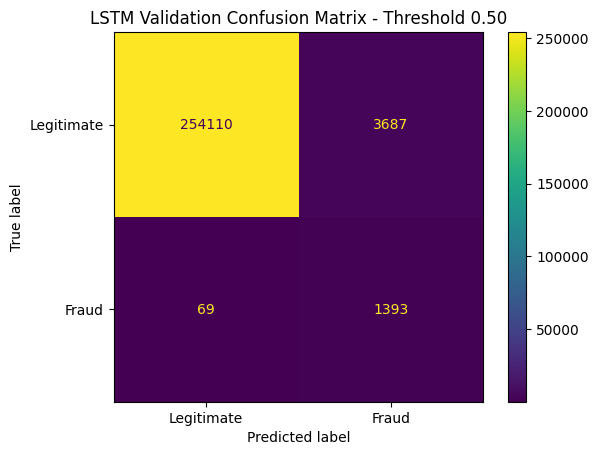

True Negatives : 254110
False Positives: 3687
False Negatives: 69
True Positives : 1393


In [ ]:
# Confusion Matrix

import matplotlib.pyplot as plt

lstm_val_cm = confusion_matrix(
    y_lstm_val,
    lstm_val_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=lstm_val_cm,
    display_labels=[
        'Legitimate',
        'Fraud'
    ]
)

disp.plot()

plt.title(
    'LSTM Validation Confusion Matrix - Threshold 0.50'
)

plt.show()

tn, fp, fn, tp = lstm_val_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

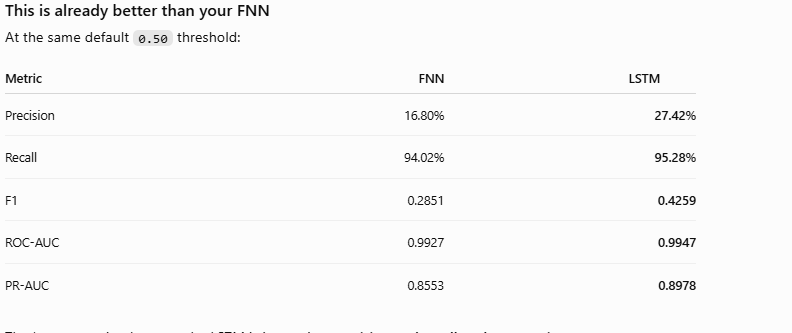

### 14.7 LSTM Threshold Analysis

The default threshold of 0.50 produces very high fraud recall, but it also
generates a considerable number of false-positive alerts.

Different classification thresholds are therefore evaluated to understand the
trade-off between fraud precision and recall.

Increasing the threshold generally reduces false-positive alerts and improves
precision, but may also cause the model to miss more fraudulent transactions.

The final operating threshold will be selected using the validation dataset,
with the goal of maximizing precision while maintaining fraud recall of
approximately 90% or higher.

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

lstm_thresholds = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.85,
    0.90,
    0.95
]

for threshold in lstm_thresholds:

    lstm_pred_threshold = (
        lstm_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_lstm_val,
        lstm_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_lstm_val,
        lstm_pred_threshold
    )

    f1 = f1_score(
        y_lstm_val,
        lstm_pred_threshold
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.50 | Precision: 0.2742 | Recall: 0.9528 | F1: 0.4259
Threshold: 0.60 | Precision: 0.3303 | Recall: 0.9480 | F1: 0.4899
Threshold: 0.70 | Precision: 0.3813 | Recall: 0.9419 | F1: 0.5429
Threshold: 0.80 | Precision: 0.4426 | Recall: 0.9316 | F1: 0.6001
Threshold: 0.85 | Precision: 0.4849 | Recall: 0.9213 | F1: 0.6354
Threshold: 0.90 | Precision: 0.5571 | Recall: 0.9104 | F1: 0.6912
Threshold: 0.95 | Precision: 0.6793 | Recall: 0.8707 | F1: 0.7632


0.90 gives the best balance while still maintaining >90% fraud recall.

In [ ]:
#we should now calculate the exact threshold rather than stopping at a rounded value like 0.90.

from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_lstm_val,
    lstm_val_prob
)

min_recall = 0.90

# thresholds has one fewer element than precision/recall
valid = recall[:-1] >= min_recall

valid_precision = precision[:-1][valid]
valid_recall = recall[:-1][valid]
valid_thresholds = thresholds[valid]

best_idx = np.argmax(valid_precision)

final_lstm_threshold = float(
    valid_thresholds[best_idx]
)

print(
    "Best LSTM Threshold:",
    final_lstm_threshold
)

print(
    "Precision:",
    valid_precision[best_idx]
)

print(
    "Recall:",
    valid_recall[best_idx]
)

Best LSTM Threshold: 0.9151198863983154
Precision: 0.5828166519043402
Recall: 0.9001367989056087


In [ ]:
import json
import os

MODEL_DIR = '/content/drive/MyDrive/FraudShield/models'
os.makedirs(MODEL_DIR, exist_ok=True)

final_lstm_threshold = 0.9151198863983154

lstm_config = {
    'threshold': final_lstm_threshold
}

with open(
    f'{MODEL_DIR}/lstm_config.json',
    'w'
) as f:
    json.dump(lstm_config, f, indent=2)

print("LSTM threshold saved:", final_lstm_threshold)

LSTM threshold saved: 0.9151198863983154


### 14.9 Final LSTM Threshold Selection

Using the validation Precision-Recall curve, the final LSTM operating threshold
was selected as approximately **0.9151**.

At this threshold, the validation performance was:

- **Fraud Precision:** 58.28%
- **Fraud Recall:** 90.01%

The threshold was selected to maximize precision while maintaining fraud recall
of at least 90%.

This threshold is now fixed and will be used for the final evaluation on the
untouched test dataset. The test dataset will not be used to modify the threshold.

### 14.10 Prepare LSTM Test Sequences

The LSTM requires sequential transaction history rather than evaluating each test
transaction independently.

To preserve realistic transaction history, the training and test transactions are
temporarily combined and sorted chronologically within each card (`cc_num`).

This allows the first transactions in the test dataset to use earlier transactions
from the training period as historical context.

Important safeguards are maintained:

- `cc_num` is used only to group transactions into sequences and is not used as a
  predictive feature.
- Only transactions occurring before the target transaction are used as sequence
  history.
- Fraud labels are not used as input features.
- The existing LSTM scaler, which was fitted only on the training period, is reused.
  The scaler is **not fitted again** on the test data.
- Only sequences whose final target transaction belongs to the test dataset are
  included in the final LSTM test set.

Each test sample therefore contains:

**5 consecutive transactions × 12 features**

The label corresponds only to the final transaction in the five-transaction sequence.

This process preserves chronological continuity while keeping the final test
evaluation independent from model training and threshold selection.

In [ ]:
# Columns needed for LSTM sequence creation
lstm_sequence_columns = [
    'cc_num',
    'trans_date_trans_time',
    'is_fraud'
] + lstm_features


# -----------------------------
# Prepare training history
# -----------------------------
train_lstm_history = train_df[
    lstm_sequence_columns
].copy()

train_lstm_history['dataset'] = 'train'


# -----------------------------
# Prepare test transactions
# -----------------------------
test_lstm_history = test_df[
    lstm_sequence_columns
].copy()

test_lstm_history['dataset'] = 'test'


# -----------------------------
# Combine train + test
# -----------------------------
combined_lstm_test = pd.concat(
    [
        train_lstm_history,
        test_lstm_history
    ],
    ignore_index=True
)


# Sort chronologically within each card
combined_lstm_test = combined_lstm_test.sort_values(
    [
        'cc_num',
        'trans_date_trans_time'
    ]
).reset_index(drop=True)


print("Combined shape:", combined_lstm_test.shape)

Combined shape: (1852394, 16)


In [ ]:
combined_lstm_test[lstm_features] = (
    lstm_scaler.transform(
        combined_lstm_test[lstm_features]
    )
)

In [ ]:
# how many test sequences will have

test_seq_count = 0

for _, group in combined_lstm_test.groupby(
    'cc_num',
    sort=False
):

    if len(group) < sequence_length:
        continue

    dataset_values = group[
        'dataset'
    ].to_numpy()

    test_seq_count += (
        dataset_values[
            sequence_length - 1:
        ] == 'test'
    ).sum()


print(
    "Number of LSTM test sequences:",
    test_seq_count
)

print(
    "Original test transactions:",
    len(test_df)
)

Number of LSTM test sequences: 555655
Original test transactions: 555719


In [ ]:
n_lstm_features = len(lstm_features)

X_lstm_test = np.empty(
    (
        test_seq_count,
        sequence_length,
        n_lstm_features
    ),
    dtype=np.float32
)

y_lstm_test = np.empty(
    test_seq_count,
    dtype=np.int8
)


test_idx = 0


for _, group in combined_lstm_test.groupby(
    'cc_num',
    sort=False
):

    if len(group) < sequence_length:
        continue

    feature_values = group[
        lstm_features
    ].to_numpy(
        dtype=np.float32
    )

    labels = group[
        'is_fraud'
    ].to_numpy()

    datasets = group[
        'dataset'
    ].to_numpy()


    for i in range(
        sequence_length - 1,
        len(group)
    ):

        # We only want targets belonging to test data
        if datasets[i] != 'test':
            continue

        X_lstm_test[test_idx] = (
            feature_values[
                i - sequence_length + 1:
                i + 1
            ]
        )

        y_lstm_test[test_idx] = labels[i]

        test_idx += 1


print(
    "X_lstm_test:",
    X_lstm_test.shape
)

print(
    "y_lstm_test:",
    y_lstm_test.shape
)

print(
    "Fraud transactions in LSTM test:",
    y_lstm_test.sum()
)

X_lstm_test: (555655, 5, 12)
y_lstm_test: (555655,)
Fraud transactions in LSTM test: 2081


### 14.11 Verify LSTM Test Sequence Coverage

Before performing the final LSTM evaluation, the number of generated test
sequences is compared with the number of transactions in the original test set.

The original test dataset contains **555,719 transactions**, while sequence
generation produced **555,655 LSTM test samples**, leaving 64 transactions
without a complete five-transaction history.

Importantly, the original test set contains 2,145 fraudulent transactions,
whereas the generated LSTM sequences contain only 2,081 fraud cases.

Therefore, all 64 excluded transactions appear to be fraudulent.

Evaluating the model without investigating these missing fraud cases could bias
the final LSTM performance estimate. The following diagnostic step identifies
the excluded transactions and determines why they do not have sufficient
historical sequence context.

In [ ]:
# Add a unique identifier to every test transaction
test_lstm_check = test_df[
    ['cc_num', 'trans_date_trans_time', 'is_fraud']
].copy()

test_lstm_check['test_row_id'] = np.arange(len(test_lstm_check))


# Build a combined history with the row ID
train_check = train_df[
    ['cc_num', 'trans_date_trans_time', 'is_fraud']
].copy()

train_check['dataset'] = 'train'
train_check['test_row_id'] = -1


test_check = test_lstm_check.copy()
test_check['dataset'] = 'test'


combined_check = pd.concat(
    [train_check, test_check],
    ignore_index=True
)

combined_check = combined_check.sort_values(
    ['cc_num', 'trans_date_trans_time']
).reset_index(drop=True)


# Track test rows that have enough history for a 5-transaction sequence
included_test_ids = []

for _, group in combined_check.groupby('cc_num', sort=False):

    if len(group) < sequence_length:
        continue

    datasets = group['dataset'].to_numpy()
    row_ids = group['test_row_id'].to_numpy()

    for i in range(sequence_length - 1, len(group)):

        if datasets[i] == 'test':
            included_test_ids.append(
                int(row_ids[i])
            )


included_test_ids = set(included_test_ids)

missing_test_ids = [
    i for i in range(len(test_df))
    if i not in included_test_ids
]


missing_test_rows = test_df.iloc[
    missing_test_ids
][
    [
        'cc_num',
        'trans_date_trans_time',
        'amt',
        'is_fraud'
    ]
]


print("Missing test rows:", len(missing_test_rows))

print(
    "Fraud among missing rows:",
    missing_test_rows['is_fraud'].sum()
)

display(missing_test_rows.head(20))

Missing test rows: 64
Fraud among missing rows: 64


,cc_num,trans_date_trans_time,amt,is_fraud
10036,180098888332620,2020-06-24 00:26:45,315.45,1
10047,180098888332620,2020-06-24 00:44:24,279.78,1
10167,180098888332620,2020-06-24 02:56:50,287.38,1
10193,180098888332620,2020-06-24 03:21:56,276.40,1
33880,3540416671210051,2020-07-02 23:17:05,9.03,1
33975,3540416671210051,2020-07-03 00:18:13,286.73,1
34114,3540416671210051,2020-07-03 02:07:47,262.49,1
36057,3540416671210051,2020-07-03 22:31:00,1115.94,1
50228,503851367360,2020-07-08 02:05:41,331.18,1
51722,503851367360,2020-07-08 22:30:04,915.47,1


### Investigate Transactions Without Sufficient LSTM History

The LSTM requires five consecutive transactions for each prediction.

A coverage check identified 64 test transactions that could not form a complete
five-transaction sequence. All 64 of these transactions are fraudulent.

The missing transactions appear to occur in small groups belonging to the same
cards, suggesting a **cold-start problem**: some cards may not have enough prior
transaction history available when they first appear in the test period.

The following analysis checks whether the affected cards had transaction history
in the training dataset and determines how many cards are affected.

These transactions will not be silently removed from the final model evaluation,
because doing so would artificially inflate the LSTM's fraud recall.

In [ ]:
missing_card_summary = (
    missing_test_rows
    .groupby('cc_num')
    .agg(
        missing_rows=('is_fraud', 'size'),
        fraud_rows=('is_fraud', 'sum'),
        first_missing_time=('trans_date_trans_time', 'min'),
        last_missing_time=('trans_date_trans_time', 'max')
    )
)

train_history_counts = (
    train_df[
        train_df['cc_num'].isin(missing_test_rows['cc_num'])
    ]
    .groupby('cc_num')
    .size()
    .rename('train_history_count')
)

missing_card_summary = (
    missing_card_summary
    .join(train_history_counts)
    .fillna({'train_history_count': 0})
)

display(missing_card_summary)

print(
    "Number of affected cards:",
    missing_card_summary.shape[0]
)

print(
    "Cards with zero training history:",
    (missing_card_summary['train_history_count'] == 0).sum()
)

,missing_rows,fraud_rows,first_missing_time,last_missing_time,train_history_count
cc_num,,,,,
503851367360,4,4,2020-07-08 02:05:41,2020-07-08 23:11:56,0.0
586100864972,4,4,2020-09-23 18:34:20,2020-09-23 23:11:29,0.0
4295296907373,4,4,2020-10-25 06:57:18,2020-10-25 22:51:03,0.0
4883407061576,4,4,2020-10-24 20:34:24,2020-10-24 23:00:33,0.0
180020605265701,4,4,2020-09-30 07:18:02,2020-09-30 22:34:21,0.0
180052752563109,4,4,2020-09-01 05:24:37,2020-09-01 14:11:00,0.0
180098888332620,4,4,2020-06-24 00:26:45,2020-06-24 03:21:56,0.0
347399333635231,4,4,2020-10-03 00:04:38,2020-10-04 20:18:51,0.0
372965408103277,4,4,2020-09-27 00:55:32,2020-09-27 22:49:20,0.0


Number of affected cards: 16
Cards with zero training history: 16


### 14.12 LSTM Cold-Start Analysis

The sequence coverage investigation confirmed that the 64 test transactions without
valid LSTM sequences belong to **16 cards that have no transaction history in the
training dataset**.

Each of these new cards contributes four transactions that cannot yet form the
required five-transaction LSTM sequence:

**16 cards × 4 initial transactions = 64 unscorable transactions**

All 64 of these transactions happen to be fraudulent in the test dataset.

This represents a genuine **cold-start limitation** of the sequence model rather
than an error in sequence construction.

The LSTM will therefore be evaluated on the 555,655 test transactions for which
sufficient sequential history exists.

The 64 cold-start transactions will be reported separately and can later be handled
by a non-sequential fallback model such as XGBoost as part of the hybrid fraud
detection architecture.

In [ ]:
# Now we can finally evaluate the LSTM on the untouched test sequences.

final_lstm_threshold = 0.9151198863983154

# Generate test fraud probabilities
lstm_test_prob = lstm_model.predict(
    X_lstm_test,
    batch_size=1024
).ravel()

# Apply validation-selected threshold
lstm_test_pred = (
    lstm_test_prob >= final_lstm_threshold
).astype(int)

543/543 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)

print(
    classification_report(
        y_lstm_test,
        lstm_test_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_lstm_test,
        lstm_test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_lstm_test,
        lstm_test_prob
    )
)

              precision    recall  f1-score   support

           0     0.9995    0.9964    0.9980    553574
           1     0.4800    0.8765    0.6203      2081

    accuracy                         0.9960    555655
   macro avg     0.7398    0.9365    0.8091    555655
weighted avg     0.9976    0.9960    0.9966    555655

ROC-AUC: 0.9935955806478572
PR-AUC: 0.8596466454367617


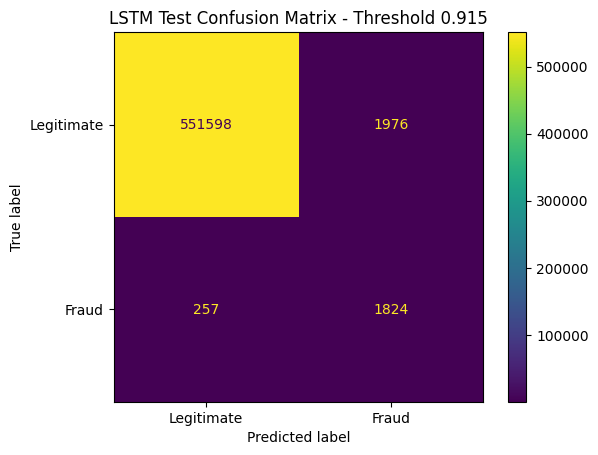

True Negatives : 551598
False Positives: 1976
False Negatives: 257
True Positives : 1824

LSTM-scored test transactions: 555655
Cold-start transactions not scored: 64
Original test transactions: 555719


In [ ]:
lstm_test_cm = confusion_matrix(
    y_lstm_test,
    lstm_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=lstm_test_cm,
    display_labels=[
        'Legitimate',
        'Fraud'
    ]
)

disp.plot()

plt.title(
    f'LSTM Test Confusion Matrix - Threshold {final_lstm_threshold:.3f}'
)

plt.show()

tn, fp, fn, tp = lstm_test_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print()
print("LSTM-scored test transactions:", len(y_lstm_test))
print("Cold-start transactions not scored:", 64)
print("Original test transactions:", len(test_df))

### 14.13 Final LSTM Test Evaluation

The LSTM was evaluated using the validation-selected threshold of approximately
**0.9151**.

For test transactions with sufficient five-transaction sequence history, the LSTM
achieved:

- **Fraud Precision:** 48.00%
- **Fraud Recall:** 87.65%
- **Fraud F1-score:** 0.620
- **ROC-AUC:** 0.994
- **PR-AUC:** 0.860

The confusion matrix showed:

- True Positives: **1,824**
- False Negatives: **257**
- False Positives: **1,976**
- True Negatives: **551,598**

The LSTM significantly improved upon the FNN by increasing precision and reducing
false-positive alerts.

However, 64 test transactions belonging to 16 previously unseen cards could not
form a complete five-transaction sequence. All 64 of these cold-start transactions
were fraudulent.

When these cold-start fraud cases are included in the denominator, the LSTM's
coverage-aware fraud recall becomes approximately **85.03%**.

This demonstrates an important operational limitation of sequence-based fraud
detection: LSTM models require sufficient historical transaction context.

The result supports the use of a hybrid architecture in which the LSTM handles
cards with sufficient sequential history, while a non-sequential model such as
XGBoost serves as a fallback for cold-start transactions.

### current ranking is:
### XGBoost > LSTM > FNN

## 15. Hybrid Fraud Detection Framework — XGBoost + LSTM

The individual model evaluation showed that XGBoost provides the strongest overall
fraud-detection performance, while the LSTM successfully learns useful sequential
transaction behavior.

However, the LSTM has an important operational limitation: it requires a minimum
transaction history before a complete sequence can be created.

During final test evaluation, 64 transactions belonging to 16 previously unseen
cards could not be evaluated by the LSTM because fewer than five historical
transactions were available.

To address this limitation, a hybrid fraud-detection framework is created.

### Hybrid Routing Strategy

For each incoming transaction:

- If sufficient transaction history exists, the transaction is evaluated using
  the **LSTM sequence model**.
- If sufficient transaction history does not exist, the transaction is evaluated
  using **XGBoost as the cold-start fallback model**.

This architecture allows FraudShield to benefit from sequential behavioral
patterns when history is available while still providing fraud predictions for
new or cold-start cards.

The hybrid approach therefore provides complete transaction coverage without
silently excluding transactions that cannot be processed by the LSTM.

#### Rebuild LSTM test sequences with their original test row IDs

In [ ]:
# Count valid LSTM test sequences
test_seq_count = 0

for _, group in combined_lstm_test.groupby(
    'cc_num',
    sort=False
):

    if len(group) < sequence_length:
        continue

    datasets = group['dataset'].to_numpy()

    test_seq_count += (
        datasets[sequence_length - 1:] == 'test'
    ).sum()


# Allocate arrays
X_lstm_test_hybrid = np.empty(
    (
        test_seq_count,
        sequence_length,
        len(lstm_features)
    ),
    dtype=np.float32
)

y_lstm_test_hybrid = np.empty(
    test_seq_count,
    dtype=np.int8
)

lstm_test_row_ids = np.empty(
    test_seq_count,
    dtype=np.int64
)


test_idx = 0


# Add original test row IDs
train_for_hybrid = train_df[
    lstm_sequence_columns
].copy()

train_for_hybrid['dataset'] = 'train'
train_for_hybrid['test_row_id'] = -1


test_for_hybrid = test_df[
    lstm_sequence_columns
].copy()

test_for_hybrid['dataset'] = 'test'
test_for_hybrid['test_row_id'] = np.arange(
    len(test_df)
)


combined_hybrid = pd.concat(
    [
        train_for_hybrid,
        test_for_hybrid
    ],
    ignore_index=True
)

combined_hybrid = combined_hybrid.sort_values(
    [
        'cc_num',
        'trans_date_trans_time'
    ]
).reset_index(drop=True)


# Use the already-fitted LSTM scaler
combined_hybrid[lstm_features] = (
    lstm_scaler.transform(
        combined_hybrid[lstm_features]
    )
)


# Build sequences + preserve original test row ID
for _, group in combined_hybrid.groupby(
    'cc_num',
    sort=False
):

    if len(group) < sequence_length:
        continue

    feature_values = group[
        lstm_features
    ].to_numpy(dtype=np.float32)

    labels = group[
        'is_fraud'
    ].to_numpy()

    datasets = group[
        'dataset'
    ].to_numpy()

    row_ids = group[
        'test_row_id'
    ].to_numpy()


    for i in range(
        sequence_length - 1,
        len(group)
    ):

        if datasets[i] != 'test':
            continue

        X_lstm_test_hybrid[test_idx] = (
            feature_values[
                i - sequence_length + 1:
                i + 1
            ]
        )

        y_lstm_test_hybrid[test_idx] = (
            labels[i]
        )

        lstm_test_row_ids[test_idx] = (
            row_ids[i]
        )

        test_idx += 1


print(
    "LSTM hybrid sequences:",
    X_lstm_test_hybrid.shape
)

print(
    "Stored test row IDs:",
    len(lstm_test_row_ids)
)

print(
    "Unique test row IDs:",
    len(np.unique(lstm_test_row_ids))
)

print(
    "Original test transactions:",
    len(test_df)
)

LSTM hybrid sequences: (555655, 5, 12)
Stored test row IDs: 555655
Unique test row IDs: 555655
Original test transactions: 555719


### 15.1 Generate Hybrid XGBoost + LSTM Predictions

The hybrid framework routes each test transaction according to the availability
of sequential history.

- Transactions with a valid five-transaction sequence are evaluated using the LSTM.
- Transactions without sufficient history are evaluated using the tuned XGBoost
  model as a cold-start fallback.

The original test-row IDs preserved during sequence generation are used to place
each LSTM prediction back into its correct position in the full test dataset.

This produces one prediction for every test transaction and therefore provides
**100% test-set coverage**.

In [ ]:
# --------------------------------------------------
# 1. Identify cold-start test rows
# --------------------------------------------------

all_test_ids = np.arange(len(test_df))

cold_start_ids = np.setdiff1d(
    all_test_ids,
    lstm_test_row_ids
)

print("LSTM-routed transactions:", len(lstm_test_row_ids))
print("XGBoost fallback transactions:", len(cold_start_ids))
print("Total transactions:", len(test_df))

LSTM-routed transactions: 555655
XGBoost fallback transactions: 64
Total transactions: 555719


In [ ]:
# Now create the XGBoost predictions for only those 64 rowS
# Raw feature rows needed by the tuned XGBoost pipeline
X_cold_start = X_test.iloc[cold_start_ids].copy()

xgb_cold_prob = best_xgb_model.predict_proba(
    X_cold_start
)[:, 1]

final_xgb_threshold = 0.85

xgb_cold_pred = (
    xgb_cold_prob >= final_xgb_threshold
).astype(int)

print("Cold-start transactions:", len(xgb_cold_pred))
print("Predicted as fraud:", xgb_cold_pred.sum())

Cold-start transactions: 64
Predicted as fraud: 60


In [ ]:
# now combine 2 models

# --------------------------------------------------
# 2. Create full hybrid prediction array
# --------------------------------------------------

hybrid_pred = np.zeros(
    len(test_df),
    dtype=int
)

# LSTM predictions for transactions with history
hybrid_pred[lstm_test_row_ids] = lstm_test_pred

# XGBoost predictions for cold-start transactions
hybrid_pred[cold_start_ids] = xgb_cold_pred


print("Hybrid predictions:", len(hybrid_pred))
print("Original test rows:", len(test_df))

Hybrid predictions: 555719
Original test rows: 555719


In [ ]:
assert len(hybrid_pred) == len(test_df)

assert np.array_equal(
    test_df.iloc[lstm_test_row_ids]['is_fraud'].to_numpy(),
    y_lstm_test_hybrid
)

print("Hybrid alignment verified successfully.")

Hybrid alignment verified successfully.


In [ ]:
# now evaluate hybrid Model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_test = test_df['is_fraud'].to_numpy()

print(
    classification_report(
        y_test,
        hybrid_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9995    0.9964    0.9980    553574
           1     0.4881    0.8783    0.6275      2145

    accuracy                         0.9960    555719
   macro avg     0.7438    0.9374    0.8127    555719
weighted avg     0.9976    0.9960    0.9965    555719



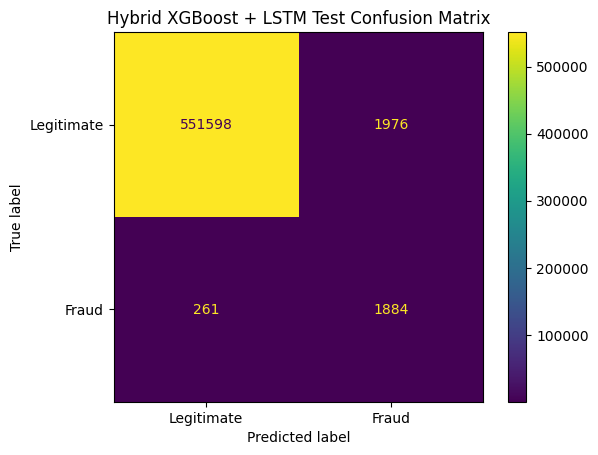

True Negatives : 551598
False Positives: 1976
False Negatives: 261
True Positives : 1884


In [ ]:
# Confusion Matrix

hybrid_cm = confusion_matrix(
    y_test,
    hybrid_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=hybrid_cm,
    display_labels=[
        'Legitimate',
        'Fraud'
    ]
)

disp.plot()

plt.title(
    'Hybrid XGBoost + LSTM Test Confusion Matrix'
)

plt.show()


tn, fp, fn, tp = hybrid_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

In [ ]:
# Finally, specifically check what XGBoost did with those 64 cold-start frauds:

cold_start_actual = y_test[cold_start_ids]

print(
    "Cold-start actual fraud:",
    cold_start_actual.sum()
)

print(
    "Cold-start fraud detected by XGBoost:",
    (
        (xgb_cold_pred == 1)
        &
        (cold_start_actual == 1)
    ).sum()
)

print(
    "Cold-start fraud missed by XGBoost:",
    (
        (xgb_cold_pred == 0)
        &
        (cold_start_actual == 1)
    ).sum()
)

Cold-start actual fraud: 64
Cold-start fraud detected by XGBoost: 60
Cold-start fraud missed by XGBoost: 4


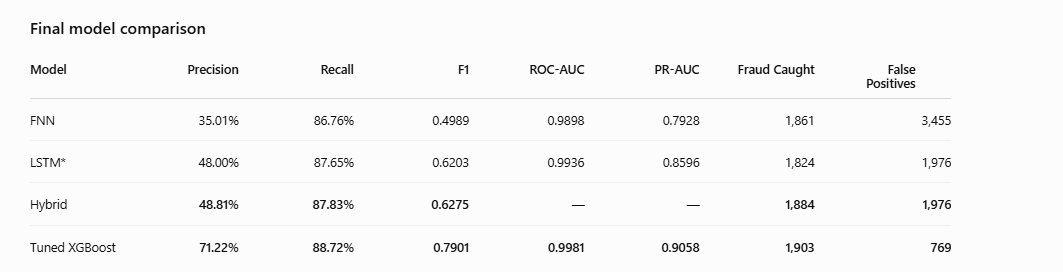

1. Tuned XGBoost        ← Best overall model
2. Hybrid XGBoost+LSTM  ← Best sequence-based system with full coverage
3. LSTM
4. FNN

### 15.2 Final Hybrid XGBoost + LSTM Evaluation

The hybrid framework was evaluated on the complete test dataset containing
**555,719 transactions**.

Transactions with sufficient five-transaction history were evaluated using the
LSTM, while transactions without sufficient history were routed to the tuned
XGBoost model.

The hybrid system achieved:

- **Fraud Precision:** 48.81%
- **Fraud Recall:** 87.83%
- **Fraud F1-score:** 0.628
- **True Positives:** 1,884
- **False Negatives:** 261
- **False Positives:** 1,976
- **True Negatives:** 551,598
- **Test Coverage:** 100%

The LSTM could not independently evaluate 64 cold-start transactions belonging
to previously unseen cards. All 64 of these transactions were fraudulent.

Using XGBoost as the fallback model successfully detected **60 of these 64
cold-start fraud cases**, corresponding to a cold-start detection rate of
approximately **93.75%**.

As a result, the hybrid framework increased the number of detected fraud cases
from 1,824 for the sequence-only LSTM evaluation to 1,884 while providing
predictions for every transaction in the test dataset.

However, the tuned standalone XGBoost model remained the strongest overall
performer. XGBoost detected 1,903 fraud cases with only 769 false positives,
compared with 1,884 fraud detections and 1,976 false positives for the hybrid
framework.

Therefore, the hybrid framework successfully addresses the operational
cold-start limitation of the LSTM and demonstrates how machine learning and
sequential deep learning can be integrated in a production-oriented fraud
detection architecture.

Nevertheless, based on final predictive performance, tuned XGBoost remains the
preferred primary fraud detection model for this dataset.

## 16. Final Model Comparison

After completing the supervised machine-learning models, deep-learning models,
and the hybrid framework, the strongest final models are compared using the
future unseen test dataset.

The comparison focuses on metrics that are particularly important for fraud
detection:

- **Precision** — how many transactions flagged as fraud were actually fraudulent.
- **Recall** — how many actual fraudulent transactions were successfully detected.
- **F1-score** — balance between precision and recall.
- **ROC-AUC** — overall ability to separate fraudulent and legitimate transactions.
- **PR-AUC** — precision-recall performance across classification thresholds and
  particularly useful for highly imbalanced fraud data.
- **False Positives** — legitimate transactions incorrectly flagged as fraud.
- **Fraud Detected** — number of actual fraudulent transactions successfully identified.
- **Coverage** — percentage of test transactions for which the model can produce
  a prediction.

The standalone LSTM requires a five-transaction history and therefore cannot
independently score a small number of cold-start transactions. The hybrid model
addresses this limitation by routing those transactions to XGBoost.

In [ ]:
import pandas as pd
import numpy as np

final_model_comparison = pd.DataFrame({

    'Model': [
        'FNN',
        'LSTM',
        'Hybrid XGBoost + LSTM',
        'Tuned XGBoost'
    ],

    'Precision': [
        0.3501,
        0.4800,
        0.4881,
        0.7122
    ],

    'Recall': [
        0.8676,
        0.8765,
        0.8783,
        0.8872
    ],

    'F1_Score': [
        0.4989,
        0.6203,
        0.6275,
        0.7901
    ],

    'ROC_AUC': [
        0.9898,
        0.9936,
        np.nan,
        0.9981
    ],

    'PR_AUC': [
        0.7928,
        0.8596,
        np.nan,
        0.9058
    ],

    'Fraud_Detected': [
        1861,
        1824,
        1884,
        1903
    ],

    'False_Positives': [
        3455,
        1976,
        1976,
        769
    ],

    'Coverage_Percent': [
        100.00,
        99.9885,
        100.00,
        100.00
    ]
})

final_model_comparison

,Model,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Fraud_Detected,False_Positives,Coverage_Percent
0,FNN,0.3501,0.8676,0.4989,0.9898,0.7928,1861,3455,100.0000
1,LSTM,0.4800,0.8765,0.6203,0.9936,0.8596,1824,1976,99.9885
2,Hybrid XGBoost + LSTM,0.4881,0.8783,0.6275,NaN,NaN,1884,1976,100.0000
3,Tuned XGBoost,0.7122,0.8872,0.7901,0.9981,0.9058,1903,769,100.0000


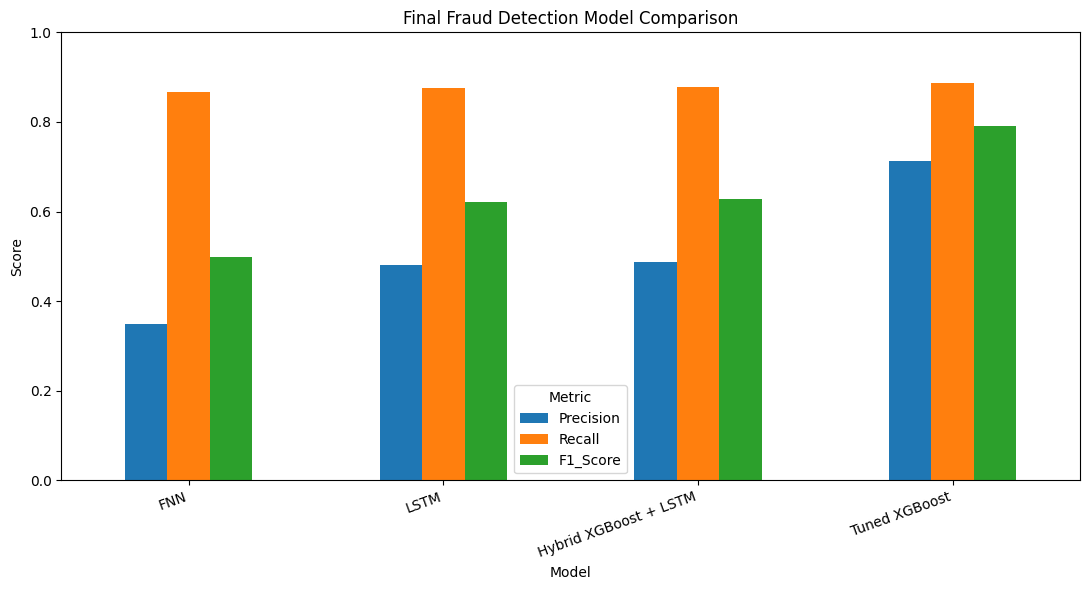

In [ ]:
import matplotlib.pyplot as plt

comparison_metrics = (
    final_model_comparison
    .set_index('Model')[
        ['Precision', 'Recall', 'F1_Score']
    ]
)

comparison_metrics.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title(
    'Final Fraud Detection Model Comparison'
)

plt.ylabel('Score')

plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha='right'
)

plt.legend(
    title='Metric'
)

plt.tight_layout()

plt.show()

### Final Model Comparison Observations

The final comparison demonstrates a clear progression in fraud-detection
performance.

The FNN achieved strong recall but generated a relatively high number of false
positive alerts.

The LSTM improved considerably over the FNN. By modeling sequences of transactions,
it increased precision, F1-score, ROC-AUC, and PR-AUC while reducing false-positive
alerts.

The hybrid XGBoost + LSTM framework successfully addressed the LSTM cold-start
limitation and provided predictions for 100% of the test dataset. XGBoost detected
60 of the 64 cold-start fraud transactions that the standalone LSTM could not score.

However, the tuned standalone XGBoost model remained the strongest overall model.

XGBoost achieved:

- **71.22% fraud precision**
- **88.72% fraud recall**
- **0.790 F1-score**
- **0.998 ROC-AUC**
- **0.906 PR-AUC**
- **1,903 fraud transactions detected**
- Only **769 false-positive alerts**

Therefore, XGBoost provides the strongest balance between detecting fraudulent
transactions and minimizing disruption to legitimate customers.

The deep-learning and hybrid experiments remain valuable because they demonstrate
that sequential transaction behavior contains useful predictive information and
identify how cold-start limitations can be handled in a real-world fraud detection
architecture.

## 17. Final Model Selection

After evaluating the supervised machine-learning models, deep-learning models,
and the hybrid architecture, the **tuned XGBoost model** was selected as the
primary FraudShield fraud-detection model.

### Selected Model: Tuned XGBoost

The final XGBoost model achieved the strongest performance on the untouched
future test dataset:

- **Fraud Precision:** 71.22%
- **Fraud Recall:** 88.72%
- **F1-score:** 0.790
- **ROC-AUC:** 0.998
- **PR-AUC:** 0.906
- **Fraud Detected:** 1,903 out of 2,145
- **Fraud Missed:** 242
- **False Positives:** 769
- **Test Coverage:** 100%

The final classification threshold was **0.85**, selected using the validation
dataset before evaluating the model on the untouched test dataset.

### Why XGBoost Was Selected

Fraud detection requires more than simply maximizing accuracy.

Because fraudulent transactions represent a very small proportion of the
dataset, the selected model must detect a high percentage of fraud while also
avoiding excessive false-positive alerts.

XGBoost provided the strongest balance between these competing objectives.

Compared with the FNN, LSTM, and hybrid system, XGBoost:

- Detected the highest number of fraudulent transactions.
- Produced the fewest false-positive alerts.
- Achieved the highest precision.
- Achieved the highest F1-score.
- Achieved the highest ROC-AUC and PR-AUC.
- Provided predictions for every transaction without requiring historical
  sequence availability.

This makes XGBoost the most practical model for deployment in the current
FraudShield system.

### Business Interpretation

Using the final XGBoost model:

Approximately **89 out of every 100 fraudulent transactions are detected**.

At the same time, approximately **71 out of every 100 transactions flagged as
fraud are actually fraudulent**.

This is particularly important in a real-world fraud detection environment.

A model with very high recall but poor precision can generate thousands of
unnecessary alerts, potentially resulting in:

- Additional manual investigation workload
- Unnecessary transaction declines
- Customer inconvenience
- Increased fraud-review costs

The tuned XGBoost model substantially reduces this problem while maintaining
high fraud detection capability.

On the final test dataset, XGBoost generated only **769 false-positive alerts**,
compared with:

- **3,455** for the FNN
- **1,976** for the LSTM
- **1,976** for the hybrid XGBoost + LSTM system

Therefore, XGBoost provides the strongest operational balance between fraud
detection and customer impact.

### Role of Deep Learning and the Hybrid Model

Although XGBoost was selected as the primary FraudShield model, the deep-learning
experiments provided important insights.

The FNN demonstrated that neural networks could learn non-linear fraud patterns
from engineered transaction features.

The LSTM improved substantially over the FNN by incorporating sequential
transaction behavior, demonstrating that historical transaction patterns contain
useful fraud-detection information.

However, the LSTM required sufficient transaction history and could not independently
score 64 cold-start transactions belonging to previously unseen cards.

The hybrid XGBoost + LSTM framework successfully addressed this limitation by
routing cold-start transactions to XGBoost. XGBoost detected 60 of the 64
cold-start fraud cases.

The hybrid experiment therefore demonstrated a practical architecture for combining
machine learning and sequential deep learning.

However, because standalone XGBoost still achieved higher precision, recall,
F1-score, and substantially fewer false positives, the additional complexity of
the hybrid architecture was not justified by improved predictive performance on
this dataset.

Therefore:

**Primary FraudShield Model → Tuned XGBoost**

**Deep-Learning Models → Experimental / Benchmark Models**

**Hybrid Framework → Demonstration of a production-oriented fallback architecture**

In [ ]:
# Final FraudShield model selection

final_model = best_xgb_model
final_model_name = "Tuned XGBoost"
final_model_threshold = 0.85

print("Selected FraudShield Model:", final_model_name)
print("Operating Threshold:", final_model_threshold)

Selected FraudShield Model: Tuned XGBoost
Operating Threshold: 0.85


## 18. Save Final Model and Deployment Artifacts

After completing model development and selecting tuned XGBoost as the primary
FraudShield model, the trained models and preprocessing objects are permanently
saved to Google Drive.

Saving these artifacts allows FraudShield to:

- Reload trained models without retraining
- Make predictions in future Colab sessions
- Support deployment through a web application or API
- Preserve the exact preprocessing used during model development
- Preserve the selected classification thresholds

The tuned XGBoost pipeline is saved as the primary production model.

The FNN and LSTM models are also retained as benchmark and experimental models.

### 18.1 Create the FraudShield artifact folder

In [ ]:
# Create the FraudShield artifact folder
import os

MODEL_DIR = '/content/drive/MyDrive/FraudShield/models'

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Model directory:")
print(MODEL_DIR)

Model directory:
/content/drive/MyDrive/FraudShield/models


### 18.2 Save the final tuned XGBoost model

In [ ]:
import joblib

joblib.dump(
    best_xgb_model,
    f'{MODEL_DIR}/fraudshield_xgboost_final.pkl'
)

print("Final XGBoost pipeline saved successfully.")

Final XGBoost pipeline saved successfully.


### 18.3 Save the final XGBoost threshold

In [ ]:
import json

xgb_config = {
    "model_name": "Tuned XGBoost",
    "threshold": 0.85
}

with open(
    f'{MODEL_DIR}/xgb_config.json',
    'w'
) as f:

    json.dump(
        xgb_config,
        f,
        indent=2
    )

print("XGBoost threshold saved.")

XGBoost threshold saved.


### 18.4 Save feature configuration

In [ ]:
feature_config = {

    "model_features": model_features,

    "categorical_features": categorical_features,

    "numerical_features": numerical_features,

    "binary_features": binary_features,

    "lstm_features": lstm_features,

    "lstm_sequence_length": sequence_length
}


with open(
    f'{MODEL_DIR}/feature_config.json',
    'w'
) as f:

    json.dump(
        feature_config,
        f,
        indent=2
    )


print("Feature configuration saved.")

Feature configuration saved.


### 18.5 Save FNN artifacts

In [ ]:
fnn_model.save(
    f'{MODEL_DIR}/fraudshield_fnn.keras'
)

joblib.dump(
    preprocessor,
    f'{MODEL_DIR}/fraudshield_fnn_preprocessor.pkl'
)

fnn_config = {
    "threshold": 0.85598856
}

with open(
    f'{MODEL_DIR}/fnn_config.json',
    'w'
) as f:

    json.dump(
        fnn_config,
        f,
        indent=2
    )


print("FNN artifacts saved successfully.")

NameError: name 'fnn_model' is not defined

### 18.6 Save LSTM artifacts

In [ ]:
lstm_model.save(
    f'{MODEL_DIR}/fraudshield_lstm.keras'
)

joblib.dump(
    lstm_scaler,
    f'{MODEL_DIR}/fraudshield_lstm_scaler.pkl'
)

lstm_config = {
    "threshold": 0.9151198863983154,
    "sequence_length": sequence_length
}

with open(
    f'{MODEL_DIR}/lstm_config.json',
    'w'
) as f:

    json.dump(
        lstm_config,
        f,
        indent=2
    )


print("LSTM artifacts saved successfully.")

LSTM artifacts saved successfully.


### 18.7 Save final project metadata

In [ ]:
fraudshield_metadata = {

    "project_name": "FraudShield",

    "primary_model": "Tuned XGBoost",

    "primary_threshold": 0.85,

    "xgboost_test_precision": 0.7122,
    "xgboost_test_recall": 0.8872,
    "xgboost_test_f1": 0.7901,
    "xgboost_test_roc_auc": 0.9981,
    "xgboost_test_pr_auc": 0.9058,

    "fnn_threshold": 0.85598856,

    "lstm_threshold": 0.9151198863983154,

    "lstm_sequence_length": 5,

    "hybrid_strategy":
        "Use LSTM when sufficient sequential history exists; "
        "use XGBoost as cold-start fallback."
}


with open(
    f'{MODEL_DIR}/fraudshield_metadata.json',
    'w'
) as f:

    json.dump(
        fraudshield_metadata,
        f,
        indent=2
    )


print("FraudShield project metadata saved.")

FraudShield project metadata saved.



### 18.8 Verify what was saved


In [ ]:
print("Saved FraudShield artifacts:\n")

for filename in sorted(
    os.listdir(MODEL_DIR)
):

    print(filename)

Saved FraudShield artifacts:

feature_config.json
fnn_config.json
fraudshield_fnn.keras
fraudshield_lstm.keras
fraudshield_lstm_scaler.pkl
fraudshield_metadata.json
fraudshield_xgboost_final.pkl
lstm_config.json
xgb_config.json


### Saved FraudShield Artifacts

The final FraudShield project artifacts include:

**Primary production model**
- Tuned XGBoost preprocessing + prediction pipeline
- XGBoost operating threshold

**Deep-learning benchmark models**
- FNN model
- FNN preprocessing object
- FNN threshold
- LSTM model
- LSTM scaler
- LSTM threshold and sequence configuration

**Deployment configuration**
- Model feature definitions
- Categorical, numerical, and binary feature lists
- LSTM feature definitions
- Sequence length
- Final model metadata

These saved artifacts allow the complete fraud-detection system to be restored
without retraining the models.

### 18.9 Test that XGBoost can actually reload

In [ ]:
loaded_xgb_model = joblib.load(
    f'{MODEL_DIR}/fraudshield_xgboost_final.pkl'
)

with open(
    f'{MODEL_DIR}/xgb_config.json',
    'r'
) as f:

    loaded_xgb_config = json.load(f)


loaded_xgb_threshold = (
    loaded_xgb_config['threshold']
)


print(
    "Loaded Model:",
    type(loaded_xgb_model)
)

print(
    "Loaded Threshold:",
    loaded_xgb_threshold
)

Loaded Model: <class 'sklearn.pipeline.Pipeline'>
Loaded Threshold: 0.85


In [ ]:
sample_transactions = X_test.iloc[:5].copy()

sample_probabilities = (
    loaded_xgb_model.predict_proba(
        sample_transactions
    )[:, 1]
)


sample_predictions = (
    sample_probabilities
    >= loaded_xgb_threshold
).astype(int)


pd.DataFrame({

    'Fraud_Probability':
        sample_probabilities,

    'Fraud_Prediction':
        sample_predictions

})

,Fraud_Probability,Fraud_Prediction
0,0.000879,0
1,0.001601,0
2,0.000840,0
3,0.000624,0
4,0.009282,0


## 19. FraudShield Prediction Pipeline

The final FraudShield prediction pipeline converts processed transaction features
into an operational fraud decision.

The deployed pipeline uses the saved tuned XGBoost model and the validation-selected
classification threshold of **0.85**.

For each transaction:

1. The required FraudShield model features are provided to the saved XGBoost pipeline.
2. The pipeline automatically applies the preprocessing learned during training.
3. XGBoost generates a fraud probability.
4. The probability is compared with the operating threshold of 0.85.
5. The transaction is classified as either **LEGITIMATE** or **FRAUD**.

This allows FraudShield to make predictions without retraining the model.

In [ ]:
def fraudshield_predict(transaction_data):

    # Generate fraud probabilities
    fraud_probabilities = (
        loaded_xgb_model.predict_proba(
            transaction_data
        )[:, 1]
    )

    # Apply production threshold
    predictions = (
        fraud_probabilities
        >= loaded_xgb_threshold
    ).astype(int)

    # Human-readable decision
    decisions = np.where(
        predictions == 1,
        "FRAUD",
        "LEGITIMATE"
    )

    results = pd.DataFrame({
        "Fraud_Probability": fraud_probabilities,
        "Fraud_Prediction": predictions,
        "Decision": decisions
    })

    return results

In [ ]:
fraudshield_predict(
    X_test.iloc[:10].copy()
)

,Fraud_Probability,Fraud_Prediction,Decision
0,0.000879,0,LEGITIMATE
1,0.001601,0,LEGITIMATE
2,0.000840,0,LEGITIMATE
3,0.000624,0,LEGITIMATE
4,0.009282,0,LEGITIMATE
5,0.085914,0,LEGITIMATE
6,0.001469,0,LEGITIMATE
7,0.008774,0,LEGITIMATE
8,0.000409,0,LEGITIMATE
9,0.001309,0,LEGITIMATE


### Using the FraudShield Prediction Function

The `fraudshield_predict()` function accepts a Pandas DataFrame containing the
features expected by the trained XGBoost pipeline.

For example:

```python
data = X_test.iloc[:10].copy()
fraudshield_predict(data)

## 20. FraudShield Prediction Pipeline Testing

Before deployment, the final FraudShield prediction pipeline is tested to confirm
that the saved model, preprocessing pipeline, classification threshold, and
prediction function work correctly after reloading.

The tests verify that:

- Fraud probabilities remain between 0 and 1.
- Every input transaction receives exactly one prediction.
- The prediction threshold of 0.85 is applied correctly.
- Human-readable decisions match the binary model predictions.
- The reloaded production pipeline reproduces the expected performance on the
  untouched test dataset.

This step ensures that FraudShield can make predictions without retraining the model.

### 20.1 Basic function test

In [ ]:
test_sample = X_test.iloc[:100].copy()

test_results = fraudshield_predict(
    test_sample
)

print("Input rows:", len(test_sample))
print("Output rows:", len(test_results))

display(test_results.head())

Input rows: 100
Output rows: 100


,Fraud_Probability,Fraud_Prediction,Decision
0,0.000879,0,LEGITIMATE
1,0.001601,0,LEGITIMATE
2,0.000840,0,LEGITIMATE
3,0.000624,0,LEGITIMATE
4,0.009282,0,LEGITIMATE


In [ ]:
assert len(test_results) == len(test_sample)

assert test_results[
    'Fraud_Probability'
].between(0, 1).all()

assert test_results[
    'Fraud_Prediction'
].isin([0, 1]).all()

assert test_results[
    'Decision'
].isin(
    ['LEGITIMATE', 'FRAUD']
).all()

print("All basic prediction pipeline tests passed.")

All basic prediction pipeline tests passed.


### 20.2 Verify the 0.85 threshold

In [ ]:
threshold_check = (
    test_results['Fraud_Probability']
    >= loaded_xgb_threshold
).astype(int)

assert np.array_equal(
    threshold_check.to_numpy(),
    test_results['Fraud_Prediction'].to_numpy()
)

print(
    "Threshold application verified successfully."
)

Threshold application verified successfully.


### 20.3 Test on actual fraud examples

In [ ]:
fraud_indices = test_df[
    test_df['is_fraud'] == 1
].index[:10]

fraud_examples = X_test.loc[
    fraud_indices
].copy()

fraud_example_results = fraudshield_predict(
    fraud_examples
)

fraud_example_results[
    'Actual_Label'
] = 1

display(
    fraud_example_results
)

,Fraud_Probability,Fraud_Prediction,Decision,Actual_Label
0,0.536487,0,LEGITIMATE,1
1,0.999459,1,FRAUD,1
2,0.998981,1,FRAUD,1
3,0.998408,1,FRAUD,1
4,0.998699,1,FRAUD,1
5,0.971134,1,FRAUD,1
6,0.997162,1,FRAUD,1
7,0.995916,1,FRAUD,1
8,0.996370,1,FRAUD,1
9,0.999217,1,FRAUD,1


### 20.4 Test on legitimate examples

In [ ]:
legit_indices = test_df[
    test_df['is_fraud'] == 0
].index[:10]

legit_examples = X_test.loc[
    legit_indices
].copy()

legit_example_results = fraudshield_predict(
    legit_examples
)

legit_example_results[
    'Actual_Label'
] = 0

display(
    legit_example_results
)

,Fraud_Probability,Fraud_Prediction,Decision,Actual_Label
0,0.000879,0,LEGITIMATE,0
1,0.001601,0,LEGITIMATE,0
2,0.000840,0,LEGITIMATE,0
3,0.000624,0,LEGITIMATE,0
4,0.009282,0,LEGITIMATE,0
5,0.085914,0,LEGITIMATE,0
6,0.001469,0,LEGITIMATE,0
7,0.008774,0,LEGITIMATE,0
8,0.000409,0,LEGITIMATE,0
9,0.001309,0,LEGITIMATE,0


### 20.5 Final production-pipeline verification

In [ ]:
production_test_results = (
    fraudshield_predict(
        X_test.copy()
    )
)

production_test_pred = (
    production_test_results[
        'Fraud_Prediction'
    ].to_numpy()
)

print(
    classification_report(
        y_test,
        production_test_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9996    0.9986    0.9991    553574
           1     0.7122    0.8872    0.7901      2145

    accuracy                         0.9982    555719
   macro avg     0.8559    0.9429    0.8946    555719
weighted avg     0.9985    0.9982    0.9983    555719



In [ ]:
production_cm = confusion_matrix(
    y_test,
    production_test_pred
)

print(production_cm)

tn, fp, fn, tp = production_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

[[552805    769]
 [   242   1903]]
True Negatives : 552805
False Positives: 769
False Negatives: 242
True Positives : 1903


### 20.6 Production Pipeline Verification Result

The saved FraudShield XGBoost production pipeline was reloaded and evaluated on
the complete untouched test dataset.

The reloaded pipeline reproduced the same final test performance obtained during
model evaluation:

- **Fraud Precision:** 71.22%
- **Fraud Recall:** 88.72%
- **Fraud F1-score:** 0.790
- **True Positives:** 1,903
- **False Negatives:** 242
- **False Positives:** 769
- **True Negatives:** 552,805

This confirms that the saved preprocessing pipeline, trained XGBoost model,
classification threshold, and reusable FraudShield prediction function are
working consistently after reloading.

Therefore, the FraudShield production prediction pipeline is considered
successfully validated and ready for deployment integration.

## 21. FraudShield Web Application

A Streamlit web interface is created to demonstrate how the final FraudShield
XGBoost model can be used in an operational environment.

The application:

- Loads the saved tuned XGBoost pipeline
- Loads the production classification threshold
- Accepts transaction feature values
- Generates a fraud probability
- Applies the production threshold of 0.85
- Displays a human-readable **FRAUD** or **LEGITIMATE** decision

The initial deployment interface uses the engineered model features directly.
A production system could automatically generate these features from transaction
and customer-history databases before sending them to the model.

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json


# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="FraudShield",
    page_icon="🛡️",
    layout="wide"
)


# --------------------------------------------------
# LOAD MODEL
# --------------------------------------------------

MODEL_PATH = "fraudshield_xgboost_final.pkl"
CONFIG_PATH = "xgb_config.json"


@st.cache_resource
def load_model():

    model = joblib.load(
        MODEL_PATH
    )

    with open(
        CONFIG_PATH,
        "r"
    ) as f:

        config = json.load(f)

    return model, config


model, config = load_model()

threshold = config["threshold"]


# --------------------------------------------------
# TITLE
# --------------------------------------------------

st.title("🛡️ FraudShield")

st.subheader(
    "AI-Powered Credit Card Fraud Detection"
)

st.write(
    """
    Enter transaction information below to estimate
    the probability that the transaction is fraudulent.
    """
)


# --------------------------------------------------
# TRANSACTION INFORMATION
# --------------------------------------------------

st.header("Transaction Information")


col1, col2, col3 = st.columns(3)


with col1:

    amt = st.number_input(
        "Transaction Amount ($)",
        min_value=0.0,
        value=100.0
    )

    category = st.selectbox(
        "Transaction Category",
        [
            "grocery_pos",
            "shopping_net",
            "shopping_pos",
            "gas_transport",
            "misc_net",
            "misc_pos",
            "entertainment",
            "food_dining",
            "health_fitness",
            "home",
            "kids_pets",
            "personal_care",
            "travel"
        ]
    )

    gender = st.selectbox(
        "Gender",
        ["M", "F"]
    )

    state = st.text_input(
        "State",
        value="TX"
    )


with col2:

    city_pop = st.number_input(
        "City Population",
        min_value=0,
        value=100000
    )

    age = st.number_input(
        "Customer Age",
        min_value=18,
        max_value=100,
        value=40
    )

    hour = st.slider(
        "Transaction Hour",
        0,
        23,
        12
    )

    day_of_week = st.selectbox(
        "Day of Week",
        [
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday"
        ]
    )

    month = st.slider(
        "Month",
        1,
        12,
        6
    )


with col3:

    distance = st.number_input(
        "Cardholder-Merchant Distance (km)",
        min_value=0.0,
        value=50.0
    )

    time_since_prev = st.number_input(
        "Minutes Since Previous Transaction",
        min_value=0.0,
        value=120.0
    )

    customer_prev_avg_amt = st.number_input(
        "Customer Previous Average Amount",
        min_value=0.0,
        value=75.0
    )

    txn_count_prev_1h = st.number_input(
        "Transactions in Previous Hour",
        min_value=0,
        value=0
    )


# --------------------------------------------------
# ADDITIONAL FEATURES
# --------------------------------------------------

is_weekend = int(
    day_of_week in [
        "Saturday",
        "Sunday"
    ]
)

no_prior_history = st.checkbox(
    "Customer has no previous transaction history"
)

no_prior_history = int(
    no_prior_history
)


if customer_prev_avg_amt > 0:

    amt_ratio_to_prev_avg = (
        amt / customer_prev_avg_amt
    )

else:

    amt_ratio_to_prev_avg = 0


# --------------------------------------------------
# BUILD MODEL INPUT
# --------------------------------------------------

transaction = pd.DataFrame({

    "amt": [amt],

    "category": [category],

    "gender": [gender],

    "state": [state],

    "city_pop": [city_pop],

    "age": [age],

    "hour": [hour],

    "day_of_week": [day_of_week],

    "month": [month],

    "is_weekend": [is_weekend],

    "cardholder_merchant_distance_km": [
        distance
    ],

    "time_since_prev_txn_min": [
        time_since_prev
    ],

    "customer_prev_avg_amt": [
        customer_prev_avg_amt
    ],

    "amt_ratio_to_prev_avg": [
        amt_ratio_to_prev_avg
    ],

    "txn_count_prev_1h": [
        txn_count_prev_1h
    ],

    "no_prior_history": [
        no_prior_history
    ]

})


# --------------------------------------------------
# PREDICTION
# --------------------------------------------------

st.divider()


if st.button(
    "Analyze Transaction",
    type="primary"
):

    probability = (
        model.predict_proba(
            transaction
        )[:, 1][0]
    )

    prediction = int(
        probability >= threshold
    )


    st.subheader(
        "FraudShield Result"
    )


    metric1, metric2 = st.columns(2)


    with metric1:

        st.metric(
            "Fraud Probability",
            f"{probability:.2%}"
        )


    with metric2:

        st.metric(
            "Decision Threshold",
            f"{threshold:.0%}"
        )


    if prediction == 1:

        st.error(
            "🚨 FRAUD ALERT"
        )

        st.write(
            """
            This transaction exceeds the FraudShield
            fraud-risk threshold and should be reviewed.
            """
        )

    else:

        st.success(
            "✅ LEGITIMATE TRANSACTION"
        )

        st.write(
            """
            The predicted fraud probability is below
            the FraudShield operating threshold.
            """
        )


    with st.expander(
        "View Model Input Features"
    ):

        st.dataframe(
            transaction
        )


# --------------------------------------------------
# MODEL INFORMATION
# --------------------------------------------------

st.divider()

st.caption(
    "FraudShield | Primary Model: Tuned XGBoost | "
    "Operating Threshold: 0.85"
)

Writing app.py


In [ ]:
import shutil

shutil.copy(
    f'{MODEL_DIR}/fraudshield_xgboost_final.pkl',
    '/content/fraudshield_xgboost_final.pkl'
)

shutil.copy(
    f'{MODEL_DIR}/xgb_config.json',
    '/content/xgb_config.json'
)

print("Deployment model files restored.")

Deployment model files restored.


In [ ]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 36.3 MB/s eta 0:00:00


In [ ]:
import os

deployment_files = [
    "app.py",
    "fraudshield_xgboost_final.pkl",
    "xgb_config.json",
    "requirements.txt"
]

for file in deployment_files:
    print(file, "->", os.path.exists(f"/content/{file}"))

app.py -> True
fraudshield_xgboost_final.pkl -> True
xgb_config.json -> True
requirements.txt -> True


In [ ]:
%%writefile /content/requirements.txt
streamlit
pandas
numpy
scikit-learn
xgboost
joblib

Writing /content/requirements.txt


In [ ]:
!pip install -q -r /content/requirements.txt

In [ ]:
# start streamlit

!streamlit run /content/app.py \
    --server.port 8501 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

In [ ]:
!tail -n 80 /content/streamlit.log



2026-10-10 00:52:36.500 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.7.149.156:8501

2026-10-10 00:58:59.719 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-euw4b0-2h1urawxxgmqg-b.europe-west4-0.prod.colab.dev, host=m-s-kkb-euw4b0-2h1urawxxgmqg.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-10-10 00:59:01.289 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-euw4b0-2h1urawxxgmqg-b.europe-west4-0.prod.colab.dev, host=m-s-kkb-euw4b0-2h1urawxxgmqg.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-10-10 00:59:02.906 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-euw4b0-2h1urawxxgmqg-b.europe-west4-0.prod.colab.dev, host=m-s-kkb-euw4b0-2h1urawxxgmqg.europe-west4-b.c.codatalab-

In [ ]:
!pkill -f "streamlit run" || true

^C


In [ ]:
!streamlit run /content/app.py \
    --server.port 8501 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Sat, 10 Oct 2026 01:02:15 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6463
last-modified: Sat, 10 Oct 2026 00:42:23 GMT
etag: "b92dc9b3195640023accda1935a6344f"
cache-control: no-cache



In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8501,
    height=900
)

<IPython.core.display.Javascript object>

In [ ]:
manual_test = pd.DataFrame({
    'amt': [100.0],
    'category': ['grocery_pos'],
    'gender': ['M'],
    'state': ['TX'],
    'city_pop': [100000],
    'age': [62],
    'hour': [12],
    'day_of_week': ['Monday'],
    'month': [6],
    'is_weekend': [0],
    'cardholder_merchant_distance_km': [50.0],
    'time_since_prev_txn_min': [1.0],
    'customer_prev_avg_amt': [50.0],
    'amt_ratio_to_prev_avg': [2.0],
    'txn_count_prev_1h': [30],
    'no_prior_history': [0]
})

prob = loaded_xgb_model.predict_proba(manual_test)[:, 1][0]

print("Fraud score:", prob)
print("Fraud score %:", f"{prob:.4%}")

Fraud score: 0.00033445552
Fraud score %: 0.0334%


In [ ]:
for count in [0, 1, 2, 3, 4, 5, 10, 20, 30]:

    test_row = manual_test.copy()
    test_row['txn_count_prev_1h'] = count

    p = loaded_xgb_model.predict_proba(test_row)[:, 1][0]

    print(
        f"Previous-hour transactions: {count:2d} "
        f"→ Fraud score: {p:.4%}"
    )

Previous-hour transactions:  0 → Fraud score: 0.0311%
Previous-hour transactions:  1 → Fraud score: 0.0319%
Previous-hour transactions:  2 → Fraud score: 0.0323%
Previous-hour transactions:  3 → Fraud score: 0.0333%
Previous-hour transactions:  4 → Fraud score: 0.0334%
Previous-hour transactions:  5 → Fraud score: 0.0334%
Previous-hour transactions: 10 → Fraud score: 0.0334%
Previous-hour transactions: 20 → Fraud score: 0.0334%
Previous-hour transactions: 30 → Fraud score: 0.0334%


## 22. AI/ML QA - Input Distribution and Anomaly Validation

Manual testing of the FraudShield application revealed that extremely large or
unusual feature values do not necessarily produce proportionally larger XGBoost
risk scores.

This is expected behavior for tree-based models because predictions are based on
learned decision boundaries rather than continuous anomaly severity.

Before introducing any additional risk guardrails, the training-data distribution
is analyzed to determine:

- What values the model actually observed during training
- Which values are rare but valid
- Which values are outside the model's learned distribution
- Whether extreme inputs should trigger an additional review warning

This prevents arbitrary business rules from being added without evidence.

In [ ]:
qa_features = [
    'amt',
    'txn_count_prev_1h',
    'amt_ratio_to_prev_avg',
    'time_since_prev_txn_min'
]

for feature in qa_features:

    print("\n", "=" * 60)
    print(feature)
    print("=" * 60)

    print(
        train_df[feature].describe(
            percentiles=[
                0.50,
                0.90,
                0.95,
                0.99,
                0.999
            ]
        )
    )


amt
count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
50%      4.752000e+01
90%      1.366700e+02
95%      1.963100e+02
99%      5.459926e+02
99.9%    1.499254e+03
max      2.894890e+04
Name: amt, dtype: float64

txn_count_prev_1h


KeyError: 'txn_count_prev_1h'

In [ ]:
qa_features = [
    'amt',
    'txn_count_prev_1h',
    'amt_ratio_to_prev_avg',
    'time_since_prev_txn_min'
]

for feature in qa_features:
    print(
        feature,
        "->",
        feature in train_df.columns
    )

amt -> True
txn_count_prev_1h -> False
amt_ratio_to_prev_avg -> False
time_since_prev_txn_min -> False


#### QA Experiment

In [ ]:
qa_df = train_df.copy()

qa_df['trans_date_trans_time'] = pd.to_datetime(
    qa_df['trans_date_trans_time']
)

qa_df = qa_df.sort_values(
    ['cc_num', 'trans_date_trans_time']
).reset_index(drop=True)

In [ ]:
qa_df['time_since_prev_txn_min'] = (
    qa_df
    .groupby('cc_num')['trans_date_trans_time']
    .diff()
    .dt.total_seconds()
    / 60
)

In [ ]:
previous_spend_sum = (
    qa_df.groupby('cc_num')['amt'].cumsum()
    - qa_df['amt']
)

previous_txn_count = (
    qa_df.groupby('cc_num').cumcount()
)

qa_df['customer_prev_avg_amt'] = (
    previous_spend_sum
    /
    previous_txn_count.replace(0, np.nan)
)

qa_df['amt_ratio_to_prev_avg'] = (
    qa_df['amt']
    /
    qa_df['customer_prev_avg_amt']
)

In [ ]:
qa_df['txn_count_prev_1h'] = (
    qa_df
    .groupby('cc_num', sort=False)
    .rolling(
        '1h',
        on='trans_date_trans_time',
        closed='left'
    )['amt']
    .count()
    .fillna(0)
    .to_numpy()
)

In [ ]:
qa_features = [
    'amt',
    'txn_count_prev_1h',
    'amt_ratio_to_prev_avg',
    'time_since_prev_txn_min'
]

for feature in qa_features:

    print("\n", "=" * 60)
    print(feature)
    print("=" * 60)

    print(
        qa_df[feature].describe(
            percentiles=[
                0.50,
                0.90,
                0.95,
                0.99,
                0.999
            ]
        )
    )


amt
count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
50%      4.752000e+01
90%      1.366700e+02
95%      1.963100e+02
99%      5.459926e+02
99.9%    1.499254e+03
max      2.894890e+04
Name: amt, dtype: float64

txn_count_prev_1h
count    1.296675e+06
mean     1.895340e-01
std      4.617663e-01
min      0.000000e+00
50%      0.000000e+00
90%      1.000000e+00
95%      1.000000e+00
99%      2.000000e+00
99.9%    3.000000e+00
max      6.000000e+00
Name: txn_count_prev_1h, dtype: float64

amt_ratio_to_prev_avg
count    1.295692e+06
mean     1.021116e+00
std      2.657184e+00
min      2.176430e-03
50%      6.674220e-01
90%      2.043395e+00
95%      2.698523e+00
99%      7.464094e+00
99.9%    2.477572e+01
max      6.763881e+02
Name: amt_ratio_to_prev_avg, dtype: float64

time_since_prev_txn_min
count    1.295692e+06
mean     5.414169e+02
std      7.900163e+02
min      0.000000e+00
50%      2.760000e+02
90%      1.301850e+03
95%      1.902383e+03
99% 

### Why the QA Guardrail Was Added

During manual testing of the FraudShield Streamlit application, several extreme
transaction scenarios were tested to evaluate how the trained XGBoost model behaves
outside normal operating conditions.

For example, the application was tested with:

- Very large transaction amounts
- Extremely high transaction frequency within one hour
- Very short time gaps between transactions
- Transaction amounts far above the customer's historical average

The XGBoost model sometimes returned a low fraud-risk score even when the input
appeared highly abnormal.

Further investigation showed that this was not a Streamlit or deployment bug.
The same predictions were reproduced directly in Colab using the saved XGBoost
model.

The training-data distribution was then analyzed to determine the ranges that the
model had actually observed during training.

The analysis showed that some manually entered test values were far outside the
training distribution. For example, the maximum number of transactions observed
within the previous hour during training was only **6**, while the application was
being tested with values such as **20 or 30 transactions per hour**.

Because XGBoost is a tree-based supervised classification model, values far beyond
the highest learned decision boundary do not necessarily continue increasing the
fraud-risk score. For example, if a tree learned a rule such as:

`txn_count_prev_1h > 3`

then values such as 5, 10, 20, and 30 may all follow the same branch. The model
does not automatically interpret 30 transactions as five times more suspicious
than 6 transactions.

This highlighted an important distinction:

**Fraud classification is not the same as anomaly detection.**

The XGBoost model is trained to recognize patterns that resemble known fraudulent
transactions. It is not designed to automatically identify every value that is
extreme or outside the data distribution on which it was trained.

To make FraudShield safer and more realistic, an additional **QA / out-of-distribution
guardrail layer** was added before the final automated decision.

The guardrail checks whether important transaction features fall outside the maximum
ranges observed during model training.

If an important feature is outside the model's training range, FraudShield does not
automatically label the transaction as legitimate even if the XGBoost risk score is
low.

Instead, the system returns:

**⚠️ MANUAL REVIEW REQUIRED**

This approach ensures that unusual transactions outside the model's learned domain
are escalated for review rather than being automatically approved based only on a
potentially unreliable model score.

The final decision flow therefore becomes:

Transaction  
↓  
Training-Range / Anomaly Check  
↓  
If Outside Training Range → **Manual Review Required**  
↓  
If Within Training Range → XGBoost Fraud Risk Score  
↓  
Apply Validated 0.85 Operating Threshold  
↓  
**Fraud Alert** or **No Fraud Alert**

This guardrail improves the reliability, interpretability, and QA robustness of the
FraudShield deployment pipeline without changing the validated XGBoost model or its
classification threshold.

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import json


# ============================================================
# 1. PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="FraudShield",
    page_icon="🛡️",
    layout="wide"
)


# ============================================================
# 2. LOAD SAVED XGBOOST MODEL
# ============================================================

MODEL_PATH = "fraudshield_xgboost_final.pkl"
CONFIG_PATH = "xgb_config.json"


@st.cache_resource
def load_model():

    model = joblib.load(MODEL_PATH)

    with open(CONFIG_PATH, "r") as f:
        config = json.load(f)

    return model, config


model, config = load_model()

threshold = config["threshold"]


# ============================================================
# 3. TRAINING-RANGE QA GUARDRAILS
# ============================================================

# These values came from our training-data QA analysis.

MAX_TRAIN_AMT = 28948.90
MAX_TRAIN_TXN_COUNT_1H = 6
MAX_TRAIN_AMT_RATIO = 676.39
MAX_TRAIN_TIME_SINCE_PREV = 22357.85


# ============================================================
# 4. PAGE TITLE
# ============================================================

st.title("🛡️ FraudShield")

st.subheader(
    "AI-Powered Credit Card Fraud Detection"
)

st.write(
    """
    Enter transaction information below to estimate
    the fraud risk of the transaction.
    """
)


# ============================================================
# 5. TRANSACTION INPUTS
# ============================================================

st.header("Transaction Information")

col1, col2, col3 = st.columns(3)


# ----------------------------
# COLUMN 1
# ----------------------------

with col1:

    amt = st.number_input(
        "Transaction Amount ($)",
        min_value=0.0,
        value=100.0
    )

    category = st.selectbox(
        "Transaction Category",
        [
            "grocery_pos",
            "shopping_net",
            "shopping_pos",
            "gas_transport",
            "misc_net",
            "misc_pos",
            "entertainment",
            "food_dining",
            "health_fitness",
            "home",
            "kids_pets",
            "personal_care",
            "travel"
        ]
    )

    gender = st.selectbox(
        "Gender",
        ["M", "F"]
    )

    state = st.text_input(
        "State",
        value="TX"
    )


# ----------------------------
# COLUMN 2
# ----------------------------

with col2:

    city_pop = st.number_input(
        "City Population",
        min_value=0,
        value=100000
    )

    age = st.number_input(
        "Customer Age",
        min_value=18,
        max_value=100,
        value=40
    )

    hour = st.slider(
        "Transaction Hour",
        0,
        23,
        12
    )

    day_of_week = st.selectbox(
        "Day of Week",
        [
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday"
        ]
    )

    month = st.slider(
        "Month",
        1,
        12,
        6
    )


# ----------------------------
# COLUMN 3
# ----------------------------

with col3:

    distance = st.number_input(
        "Cardholder-Merchant Distance (km)",
        min_value=0.0,
        value=50.0
    )

    time_since_prev = st.number_input(
        "Minutes Since Previous Transaction",
        min_value=0.0,
        value=120.0
    )

    customer_prev_avg_amt = st.number_input(
        "Customer Previous Average Amount",
        min_value=0.0,
        value=75.0
    )

    txn_count_prev_1h = st.number_input(
        "Transactions in Previous Hour",
        min_value=0,
        value=0
    )


# ============================================================
# 6. AUTOMATIC FEATURE CALCULATION
# ============================================================

is_weekend = int(
    day_of_week in ["Saturday", "Sunday"]
)


no_prior_history = st.checkbox(
    "Customer has no previous transaction history"
)

no_prior_history = int(no_prior_history)


if customer_prev_avg_amt > 0:

    amt_ratio_to_prev_avg = (
        amt / customer_prev_avg_amt
    )

else:

    amt_ratio_to_prev_avg = 0


# ============================================================
# 7. BUILD XGBOOST INPUT
# ============================================================

transaction = pd.DataFrame({

    "amt": [amt],

    "category": [category],

    "gender": [gender],

    "state": [state],

    "city_pop": [city_pop],

    "age": [age],

    "hour": [hour],

    "day_of_week": [day_of_week],

    "month": [month],

    "is_weekend": [is_weekend],

    "cardholder_merchant_distance_km": [
        distance
    ],

    "time_since_prev_txn_min": [
        time_since_prev
    ],

    "customer_prev_avg_amt": [
        customer_prev_avg_amt
    ],

    "amt_ratio_to_prev_avg": [
        amt_ratio_to_prev_avg
    ],

    "txn_count_prev_1h": [
        txn_count_prev_1h
    ],

    "no_prior_history": [
        no_prior_history
    ]

})


# ============================================================
# 8. QA / OUT-OF-DISTRIBUTION CHECK
# ============================================================

warnings = []


if amt > MAX_TRAIN_AMT:

    warnings.append(
        f"Transaction amount ${amt:,.2f} is above the "
        f"maximum amount seen during model training "
        f"(${MAX_TRAIN_AMT:,.2f})."
    )


if txn_count_prev_1h > MAX_TRAIN_TXN_COUNT_1H:

    warnings.append(
        f"{txn_count_prev_1h} transactions in the previous hour "
        f"is above the training maximum of "
        f"{MAX_TRAIN_TXN_COUNT_1H}."
    )


if amt_ratio_to_prev_avg > MAX_TRAIN_AMT_RATIO:

    warnings.append(
        f"Transaction amount is {amt_ratio_to_prev_avg:.1f}× "
        f"the customer's previous average, which is outside "
        f"the model training range."
    )


if time_since_prev > MAX_TRAIN_TIME_SINCE_PREV:

    warnings.append(
        "Time since previous transaction is outside "
        "the model training range."
    )


# ============================================================
# 9. MODEL PREDICTION
# ============================================================

st.divider()


if st.button(
    "Analyze Transaction",
    type="primary"
):

    probability = (
        model.predict_proba(
            transaction
        )[:, 1][0]
    )

    prediction = int(
        probability >= threshold
    )


    st.subheader(
        "FraudShield Result"
    )


    metric1, metric2 = st.columns(2)


    with metric1:

        st.metric(
            "XGBoost Fraud Risk Score",
            f"{probability:.2%}"
        )


    with metric2:

        st.metric(
            "Fraud Alert Threshold",
            f"{threshold:.0%}"
        )


    # ========================================================
    # 10. FINAL DECISION LOGIC
    # ========================================================

    # QA guardrail gets priority
    if warnings:

        st.warning(
            "⚠️ MANUAL REVIEW REQUIRED"
        )

        st.write(
            """
            One or more transaction values are outside the
            range observed during model training.

            The XGBoost risk score should therefore not be
            used alone to automatically approve this transaction.
            """
        )

        st.write("**Reason(s):**")

        for warning in warnings:

            st.write(
                "• " + warning
            )


    # Normal transaction but XGBoost score >= threshold
    elif prediction == 1:

        st.error(
            "🚨 FRAUD ALERT"
        )

        st.write(
            """
            The transaction is within the model's training
            range, but its XGBoost fraud-risk score exceeds
            the FraudShield operating threshold.
            """
        )


    # Normal transaction and score below threshold
    else:

        st.success(
            "✅ NO FRAUD ALERT"
        )

        st.write(
            """
            The transaction is within the model's observed
            training range and its fraud-risk score is below
            the FraudShield operating threshold.
            """
        )


    # ========================================================
    # 11. SHOW INPUT FEATURES
    # ========================================================

    with st.expander(
        "View Model Input Features"
    ):

        st.dataframe(
            transaction
        )


# ============================================================
# 12. MODEL INFORMATION
# ============================================================

st.divider()

st.caption(
    "FraudShield | Primary Model: Tuned XGBoost | "
    "Operating Threshold: 0.85"
)

Overwriting app.py


In [ ]:
!pkill -f "streamlit run" || true

^C


In [ ]:
!streamlit run /content/app.py \
    --server.port 8501 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8501,
    height=1200
)

<IPython.core.display.Javascript object>

## 23. Model Explainability - Why Was a Transaction Flagged?

Fraud detection systems should not only produce a risk score but should also provide
insight into the factors that influenced the prediction.

A high-risk test transaction produced an XGBoost fraud-risk score of approximately
**98.75%**.

The transaction included:

- Transaction amount: $2,000
- Previous average transaction amount: $25
- Amount-to-previous-average ratio: 80×
- Merchant distance: 1,000 km
- Category: grocery_pos

XGBoost feature contributions are analyzed to determine which features pushed the
prediction toward fraud and which features pushed it toward a legitimate classification.

This improves model transparency and supports AI/ML model validation.

In [ ]:
high_risk_test = pd.DataFrame({
    'amt': [2000.0],
    'category': ['grocery_pos'],
    'gender': ['M'],
    'state': ['TX'],
    'city_pop': [100000],
    'age': [40],
    'hour': [12],
    'day_of_week': ['Monday'],
    'month': [6],
    'is_weekend': [0],
    'cardholder_merchant_distance_km': [1000.0],
    'time_since_prev_txn_min': [120.0],
    'customer_prev_avg_amt': [25.0],
    'amt_ratio_to_prev_avg': [80.0],
    'txn_count_prev_1h': [0],
    'no_prior_history': [0]
})

risk_score = loaded_xgb_model.predict_proba(
    high_risk_test
)[:, 1][0]

print(
    "Fraud Risk Score:",
    f"{risk_score:.2%}"
)

Fraud Risk Score: 98.75%


In [ ]:
import xgboost as xgb
import pandas as pd

# Extract preprocessing and XGBoost model from pipeline
xgb_preprocessor = loaded_xgb_model.named_steps['preprocessor']
xgb_classifier = loaded_xgb_model.named_steps['model']

# Transform the transaction exactly as the pipeline does
high_risk_processed = xgb_preprocessor.transform(
    high_risk_test
)

# Get transformed feature names
feature_names = (
    xgb_preprocessor.get_feature_names_out()
)

# Obtain XGBoost contribution values
booster = xgb_classifier.get_booster()

contributions = booster.predict(
    xgb.DMatrix(high_risk_processed),
    pred_contribs=True
)[0]

# Last value is the model bias/base contribution
feature_contributions = contributions[:-1]

explanation_df = pd.DataFrame({
    'Feature': feature_names,
    'Contribution': feature_contributions
})

# Largest absolute influences first
explanation_df['Absolute_Contribution'] = (
    explanation_df['Contribution'].abs()
)

explanation_df = explanation_df.sort_values(
    'Absolute_Contribution',
    ascending=False
)

display(
    explanation_df.head(15)
)

,Feature,Contribution,Absolute_Contribution
74,num__amt,5.042636,5.042636
4,cat__category_grocery_pos,2.014933,2.014933
77,num__hour,-1.108093,1.108093
82,num__amt_ratio_to_prev_avg,0.917056,0.917056
81,num__customer_prev_avg_amt,-0.859000,0.859000
80,num__time_since_prev_txn_min,-0.577733,0.577733
76,num__age,-0.453497,0.453497
75,num__city_pop,-0.373085,0.373085
14,cat__gender_F,0.107931,0.107931
2,cat__category_gas_transport,-0.098292,0.098292


In [ ]:
categories = [
    "grocery_pos",
    "shopping_net",
    "shopping_pos",
    "gas_transport",
    "misc_net",
    "misc_pos",
    "entertainment",
    "food_dining",
    "health_fitness",
    "home",
    "kids_pets",
    "personal_care",
    "travel"
]

category_results = []

for category in categories:

    test_row = pd.DataFrame({
        'amt': [1000.0],
        'category': [category],
        'gender': ['M'],
        'state': ['TX'],
        'city_pop': [100000],
        'age': [40],
        'hour': [12],
        'day_of_week': ['Monday'],
        'month': [6],
        'is_weekend': [0],
        'cardholder_merchant_distance_km': [1000.0],
        'time_since_prev_txn_min': [120.0],
        'customer_prev_avg_amt': [25.0],
        'amt_ratio_to_prev_avg': [40.0],
        'txn_count_prev_1h': [0],
        'no_prior_history': [0]
    })

    score = loaded_xgb_model.predict_proba(
        test_row
    )[:, 1][0]

    category_results.append({
        "Category": category,
        "Fraud_Risk_Score": score
    })

category_results = pd.DataFrame(
    category_results
).sort_values(
    "Fraud_Risk_Score",
    ascending=False
)

category_results["Fraud_Risk_Percent"] = (
    category_results["Fraud_Risk_Score"] * 100
)

display(category_results[
    ["Category", "Fraud_Risk_Percent"]
])

,Category,Fraud_Risk_Percent
0,grocery_pos,98.752815
1,shopping_net,23.062952
4,misc_net,20.352421
3,gas_transport,19.849482
6,entertainment,18.001707
9,home,14.045908
11,personal_care,8.242117
7,food_dining,7.739866
10,kids_pets,6.511357
8,health_fitness,6.435337


In [ ]:
# Look at transactions resembling our test scenario:
# high amount and large increase over previous spending

similar_transactions = qa_df[
    (qa_df['amt'] >= 1000) &
    (qa_df['amt_ratio_to_prev_avg'] >= 40)
].copy()

category_check = (
    similar_transactions
    .groupby('category')
    .agg(
        transactions=('is_fraud', 'size'),
        frauds=('is_fraud', 'sum'),
        fraud_rate=('is_fraud', 'mean')
    )
    .sort_values(
        'fraud_rate',
        ascending=False
    )
)

category_check['fraud_rate'] *= 100

display(category_check)

,transactions,frauds,fraud_rate
category,,,
shopping_net,133,3,2.255639
misc_net,6,0,0.000000
misc_pos,2,0,0.000000
shopping_pos,160,0,0.000000
travel,230,0,0.000000


# 24. AI/ML Quality Assurance and Validation

The final FraudShield system is validated from a Quality Assurance perspective
after model development and deployment.

The objective of this QA phase is to verify that:

- the production model loads correctly
- predictions are reproducible
- model outputs are valid
- the selected fraud threshold behaves correctly
- known fraud and legitimate transactions are handled as expected
- performance has not regressed
- out-of-distribution inputs are detected
- edge cases and cold-start scenarios are handled safely
- the Streamlit application produces the same results as the underlying model

This section converts the manual validation performed during model development
into a formal and repeatable AI/ML QA process.

## 24.1 QA Test Plan

| Test Area | Validation |
|---|---|
| Model Loading | Saved production model loads successfully |
| Prediction Output | Fraud score is between 0 and 1 |
| Classification Output | Prediction is either 0 or 1 |
| Threshold Validation | Score >= 0.85 triggers fraud alert |
| Regression Validation | Final test-set metrics match approved baseline |
| Known Fraud Test | Test a real fraud transaction |
| Known Legitimate Test | Test a real legitimate transaction |
| OOD Testing | Extreme values trigger manual-review guardrails |
| Model Persistence | Reloaded model reproduces original predictions |
| Cold Start | Transactions without sufficient history are handled |
| UI Integration | Streamlit and direct model prediction agree |

## 24.2 QA Test 1 — Production Model Loading

**Objective:** Verify that the final saved FraudShield XGBoost production model
and its operating threshold can be loaded successfully.

**Expected Result:**
- Saved model file exists.
- Model loads without error.
- Model supports `predict()` and `predict_proba()`.
- Saved fraud-alert threshold is `0.85`.

This test ensures that the deployed model artifact is available and usable
without retraining the model.

In [ ]:
# QA TEST 1: Production Model Loading

from google.colab import drive
drive.mount('/content/drive')

import os
import json
import joblib

MODEL_DIR = "/content/drive/MyDrive/FraudShield/models"

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "fraudshield_xgboost_final.pkl"
)

CONFIG_PATH = os.path.join(
    MODEL_DIR,
    "xgb_config.json"
)

# -----------------------------
# 1. Verify files exist
# -----------------------------
assert os.path.exists(MODEL_PATH), \
    "FAIL: Production XGBoost model file not found."

assert os.path.exists(CONFIG_PATH), \
    "FAIL: XGBoost configuration file not found."

# -----------------------------
# 2. Load production model
# -----------------------------
loaded_xgb_model = joblib.load(MODEL_PATH)

# -----------------------------
# 3. Load saved threshold
# -----------------------------
with open(CONFIG_PATH, "r") as f:
    xgb_config = json.load(f)

fraud_threshold = xgb_config["threshold"]

# -----------------------------
# 4. Verify model functionality
# -----------------------------
assert hasattr(loaded_xgb_model, "predict"), \
    "FAIL: Loaded model does not support predict()."

assert hasattr(loaded_xgb_model, "predict_proba"), \
    "FAIL: Loaded model does not support predict_proba()."

assert fraud_threshold == 0.85, \
    f"FAIL: Expected threshold 0.85, found {fraud_threshold}"

print("QA TEST 1: PASS ✅")
print("Production model loaded successfully.")
print("Model type:", type(loaded_xgb_model))
print("Fraud alert threshold:", fraud_threshold)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
QA TEST 1: PASS ✅
Production model loaded successfully.
Model type: <class 'sklearn.pipeline.Pipeline'>
Fraud alert threshold: 0.85


## 24.3 QA Test 2 — Prediction Output Validation

**Objective:** Verify that the loaded production model can successfully generate
a fraud risk score and classification for a valid transaction.

**Expected Result:**
- Fraud risk score is between 0 and 1.
- Prediction is either 0 or 1.
- Final classification follows the saved 0.85 threshold.

In [ ]:
# QA TEST 2: Prediction Output Validation

import pandas as pd
import numpy as np

# Create one valid transaction using the exact features
# expected by the production model
qa_transaction = pd.DataFrame({
    'amt': [100.0],
    'category': ['grocery_pos'],
    'gender': ['M'],
    'state': ['TX'],
    'city_pop': [100000],
    'age': [40],
    'hour': [12],
    'day_of_week': ['Monday'],
    'month': [6],
    'is_weekend': [0],
    'cardholder_merchant_distance_km': [50.0],
    'time_since_prev_txn_min': [120.0],
    'customer_prev_avg_amt': [75.0],
    'amt_ratio_to_prev_avg': [100.0 / 75.0],
    'txn_count_prev_1h': [0],
    'no_prior_history': [0]
})

# -----------------------------
# 1. Generate fraud risk score
# -----------------------------
fraud_score = loaded_xgb_model.predict_proba(
    qa_transaction
)[0, 1]

# -----------------------------
# 2. Apply FraudShield threshold
# -----------------------------
fraud_prediction = int(
    fraud_score >= fraud_threshold
)

# -----------------------------
# 3. QA validations
# -----------------------------

# Risk score must be a valid probability-like model score
assert 0 <= fraud_score <= 1, \
    f"FAIL: Fraud score {fraud_score} is outside 0-1 range."

"""assert condition, "Failure message" """

# Final prediction must only be 0 or 1
assert fraud_prediction in [0, 1], \
    f"FAIL: Invalid prediction {fraud_prediction}."

# Verify threshold logic
expected_prediction = int(
    fraud_score >= 0.85
)

assert fraud_prediction == expected_prediction, \
    "FAIL: Prediction does not match threshold logic."

print("QA TEST 2: PASS ✅")
print(f"Fraud Risk Score: {fraud_score:.4f}")
print(f"Fraud Risk Percent: {fraud_score * 100:.2f}%")
print(f"Threshold: {fraud_threshold}")
print(f"Prediction: {fraud_prediction}")

if fraud_prediction == 1:
    print("Decision: FRAUD ALERT 🚨")
else:
    print("Decision: NO FRAUD ALERT ✅")

QA TEST 2: PASS ✅
Fraud Risk Score: 0.0004
Fraud Risk Percent: 0.04%
Threshold: 0.85
Prediction: 0
Decision: NO FRAUD ALERT ✅


## 24.4 QA Test 3 — Known Fraud and Legitimate Transactions

**Objective:** Validate FraudShield predictions using real labeled transactions
from the untouched test dataset.

Two controlled test cases are evaluated:

- A transaction whose actual label is fraud (`is_fraud = 1`)
- A transaction whose actual label is legitimate (`is_fraud = 0`)

**Expected Result:**
- The model produces a valid fraud risk score for both transactions.
- The prediction is compared against the known ground-truth label.
- Any incorrect prediction is recorded as a model false positive or false negative
  rather than treated as a software failure.

In [ ]:
# Check whether the untouched test dataset is available

print("test_df shape:", test_df.shape)

required_columns = [
    'amt',
    'category',
    'gender',
    'state',
    'city_pop',
    'age',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h',
    'no_prior_history',
    'is_fraud'
]

missing_columns = [
    col for col in required_columns
    if col not in test_df.columns
]

print("Missing columns:", missing_columns)

test_df shape: (555719, 22)
Missing columns: ['age', 'hour', 'day_of_week', 'month', 'is_weekend', 'cardholder_merchant_distance_km', 'time_since_prev_txn_min', 'customer_prev_avg_amt', 'amt_ratio_to_prev_avg', 'txn_count_prev_1h', 'no_prior_history']


In [ ]:
print(
    "train_df:",
    train_df.shape if "train_df" in globals() else "MISSING"
)

print(
    "test_df:",
    test_df.shape if "test_df" in globals() else "MISSING"
)

train_df: (1296675, 22)
test_df: (555719, 22)


### Recreate Engineered Features for QA

The original train and test CSV files were reloaded after the Colab session reset.
This step recreates the engineered features required by the saved FraudShield
production model.

Historical features are calculated chronologically so that each transaction uses
only information available before that transaction.

In [ ]:
# ============================================================
# RECREATE ENGINEERED FEATURES FOR QA
# ============================================================

import pandas as pd
import numpy as np

# Work on copies so the raw CSV dataframes remain unchanged
qa_train = raw_train_df.copy()
qa_test = raw_test_df.copy()


# ------------------------------------------------------------
# 1. Convert date columns
# ------------------------------------------------------------

for df in [qa_train, qa_test]:
    df['trans_date_trans_time'] = pd.to_datetime(
        df['trans_date_trans_time']
    )

    df['dob'] = pd.to_datetime(
        df['dob']
    )


# ------------------------------------------------------------
# 2. Create basic time features
# ------------------------------------------------------------

for df in [qa_train, qa_test]:

    df['hour'] = df['trans_date_trans_time'].dt.hour

    df['day_of_week'] = (
        df['trans_date_trans_time'].dt.day_name()
    )

    df['month'] = (
        df['trans_date_trans_time'].dt.month
    )

    df['is_weekend'] = (
        df['day_of_week']
        .isin(['Saturday', 'Sunday'])
        .astype(int)
    )


# ------------------------------------------------------------
# 3. Calculate customer age at transaction time
# ------------------------------------------------------------

for df in [qa_train, qa_test]:

    transaction_date = df['trans_date_trans_time']
    dob = df['dob']

    df['age'] = (
        transaction_date.dt.year
        - dob.dt.year
        - (
            (
                transaction_date.dt.month < dob.dt.month
            )
            |
            (
                (transaction_date.dt.month == dob.dt.month)
                &
                (transaction_date.dt.day < dob.dt.day)
            )
        ).astype(int)
    )


# ------------------------------------------------------------
# 4. Calculate cardholder-to-merchant distance
#    using Haversine formula
# ------------------------------------------------------------

def haversine_distance(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        +
        np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    earth_radius_km = 6371

    return earth_radius_km * c


for df in [qa_train, qa_test]:

    df['cardholder_merchant_distance_km'] = (
        haversine_distance(
            df['lat'],
            df['long'],
            df['merch_lat'],
            df['merch_long']
        )
    )


# ------------------------------------------------------------
# 5. Mark source and original row position
# ------------------------------------------------------------

qa_train['_source'] = 'train'
qa_test['_source'] = 'test'

qa_train['_original_index'] = np.arange(len(qa_train))
qa_test['_original_index'] = np.arange(len(qa_test))


# ------------------------------------------------------------
# 6. Combine train + test
#
# This lets early test transactions use legitimate historical
# transactions from the training period.
# ------------------------------------------------------------

history_df = pd.concat(
    [qa_train, qa_test],
    ignore_index=True
)

history_df = history_df.sort_values(
    ['cc_num', 'trans_date_trans_time']
).reset_index(drop=True)


# ------------------------------------------------------------
# 7. Time since previous transaction
# ------------------------------------------------------------

history_df['time_since_prev_txn_min'] = (
    history_df
    .groupby('cc_num')['trans_date_trans_time']
    .diff()
    .dt.total_seconds()
    / 60
)


# ------------------------------------------------------------
# 8. Previous customer average transaction amount
# ------------------------------------------------------------

previous_spend_sum = (
    history_df
    .groupby('cc_num')['amt']
    .cumsum()
    - history_df['amt']
)

previous_txn_count = (
    history_df
    .groupby('cc_num')
    .cumcount()
)

history_df['customer_prev_avg_amt'] = (
    previous_spend_sum
    /
    previous_txn_count.replace(0, np.nan)
)


# ------------------------------------------------------------
# 9. Current amount compared with previous average
# ------------------------------------------------------------

history_df['amt_ratio_to_prev_avg'] = (
    history_df['amt']
    /
    history_df['customer_prev_avg_amt']
)

history_df['amt_ratio_to_prev_avg'] = (
    history_df['amt_ratio_to_prev_avg']
    .replace([np.inf, -np.inf], np.nan)
)


# ------------------------------------------------------------
# 10. Number of previous transactions in last hour
# ------------------------------------------------------------

history_df['txn_count_prev_1h'] = (
    history_df
    .groupby('cc_num', sort=False)
    .rolling(
        '1h',
        on='trans_date_trans_time',
        closed='left'
    )['amt']
    .count()
    .fillna(0)
    .to_numpy()
)


# ------------------------------------------------------------
# 11. Flag customers with no previous transaction history
# ------------------------------------------------------------

history_df['no_prior_history'] = (
    history_df[
        [
            'time_since_prev_txn_min',
            'customer_prev_avg_amt',
            'amt_ratio_to_prev_avg'
        ]
    ]
    .isna()
    .any(axis=1)
    .astype(int)
)


# ------------------------------------------------------------
# 12. Split train and test back apart
# ------------------------------------------------------------

qa_train = (
    history_df[
        history_df['_source'] == 'train'
    ]
    .sort_values('_original_index')
    .drop(
        columns=['_source', '_original_index']
    )
    .reset_index(drop=True)
)

qa_test = (
    history_df[
        history_df['_source'] == 'test'
    ]
    .sort_values('_original_index')
    .drop(
        columns=['_source', '_original_index']
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 13. Learn missing-value medians ONLY from training data
# ------------------------------------------------------------

history_features = [
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg'
]

train_history_medians = (
    qa_train[history_features]
    .median()
)


# Apply TRAIN medians to both train and test
qa_train[history_features] = (
    qa_train[history_features]
    .fillna(train_history_medians)
)

qa_test[history_features] = (
    qa_test[history_features]
    .fillna(train_history_medians)
)


# ------------------------------------------------------------
# 14. Verify model-required features
# ------------------------------------------------------------

model_features = [
    'amt',
    'category',
    'gender',
    'state',
    'city_pop',
    'age',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'cardholder_merchant_distance_km',
    'time_since_prev_txn_min',
    'customer_prev_avg_amt',
    'amt_ratio_to_prev_avg',
    'txn_count_prev_1h',
    'no_prior_history'
]

missing_features = [
    column
    for column in model_features
    if column not in qa_test.columns
]


print("Feature recreation complete ✅")
print("QA Train shape:", qa_train.shape)
print("QA Test shape:", qa_test.shape)
print("Missing model features:", missing_features)

print(
    "Missing values in model features:",
    qa_test[model_features].isna().sum().sum()
)

Feature recreation complete ✅
QA Train shape: (1296675, 33)
QA Test shape: (555719, 33)
Missing model features: []
Missing values in model features: 0


## 24.4 QA Test 3 — Known Fraud and Legitimate Transactions

**Objective:** Validate FraudShield using real labeled transactions from the untouched test dataset.

This test selects:
- one known fraud transaction (`is_fraud = 1`)
- one known legitimate transaction (`is_fraud = 0`)

The production model generates a fraud risk score for each transaction and applies
the validated 0.85 operating threshold.

**Important:** If the model misclassifies a real transaction, this is recorded as
a false positive or false negative. It does not automatically mean the software pipeline is broken.

In [ ]:
# QA TEST 3: Real Known Fraud vs Real Legitimate Transaction

# ---------------------------------------------
# 1. Select one real fraud and one real legitimate row
# ---------------------------------------------

fraud_case = qa_test[
    qa_test['is_fraud'] == 1
].iloc[[0]]

legit_case = qa_test[
    qa_test['is_fraud'] == 0
].iloc[[0]]


# ---------------------------------------------
# 2. Keep only features expected by the model
# ---------------------------------------------

fraud_input = fraud_case[model_features]
legit_input = legit_case[model_features]


# ---------------------------------------------
# 3. Get model fraud risk scores
# ---------------------------------------------

fraud_score = loaded_xgb_model.predict_proba(
    fraud_input
)[0, 1]

legit_score = loaded_xgb_model.predict_proba(
    legit_input
)[0, 1]


# ---------------------------------------------
# 4. Apply production threshold
# ---------------------------------------------

fraud_prediction = int(
    fraud_score >= fraud_threshold
)

legit_prediction = int(
    legit_score >= fraud_threshold
)


# ---------------------------------------------
# 5. Ground-truth labels
# ---------------------------------------------

fraud_actual = int(
    fraud_case['is_fraud'].iloc[0]
)

legit_actual = int(
    legit_case['is_fraud'].iloc[0]
)


# ---------------------------------------------
# 6. Validate model outputs
# ---------------------------------------------

assert 0 <= fraud_score <= 1, \
    "FAIL: Fraud-case score outside 0-1 range."

assert 0 <= legit_score <= 1, \
    "FAIL: Legitimate-case score outside 0-1 range."

assert fraud_prediction in [0, 1], \
    "FAIL: Invalid fraud-case prediction."

assert legit_prediction in [0, 1], \
    "FAIL: Invalid legitimate-case prediction."


# ---------------------------------------------
# 7. Display QA results
# ---------------------------------------------

print("QA TEST 3 RESULTS")
print("-" * 50)

print("\nREAL FRAUD TRANSACTION")
print(f"Actual Label: {fraud_actual}")
print(f"Fraud Risk Score: {fraud_score:.4f}")
print(f"Fraud Risk Percent: {fraud_score * 100:.2f}%")
print(f"Prediction: {fraud_prediction}")

if fraud_prediction == fraud_actual:
    print("Result: CORRECT ✅")
else:
    print("Result: FALSE NEGATIVE ❌")


print("\nREAL LEGITIMATE TRANSACTION")
print(f"Actual Label: {legit_actual}")
print(f"Fraud Risk Score: {legit_score:.4f}")
print(f"Fraud Risk Percent: {legit_score * 100:.2f}%")
print(f"Prediction: {legit_prediction}")

if legit_prediction == legit_actual:
    print("Result: CORRECT ✅")
else:
    print("Result: FALSE POSITIVE ❌")

QA TEST 3 RESULTS
--------------------------------------------------

REAL FRAUD TRANSACTION
Actual Label: 1
Fraud Risk Score: 0.5365
Fraud Risk Percent: 53.65%
Prediction: 0
Result: FALSE NEGATIVE ❌

REAL LEGITIMATE TRANSACTION
Actual Label: 0
Fraud Risk Score: 0.0009
Fraud Risk Percent: 0.09%
Prediction: 0
Result: CORRECT ✅


### QA Test 3 Result

The production model successfully generated valid predictions for real transactions
from the untouched test dataset.

- The legitimate transaction was correctly classified as legitimate, producing a
  **True Negative**.
- The selected fraud transaction received a fraud risk score of approximately
  **53.65%**, which was below the production threshold of **85%**. Therefore,
  the model classified it as legitimate, producing a **False Negative**.

This result does not indicate a software defect. Machine learning models are
probabilistic and are not expected to classify every transaction correctly.

The false-negative case demonstrates why model QA must evaluate aggregate metrics
such as recall, precision, F1-score, PR-AUC, and the confusion matrix rather than
expecting 100% accuracy on individual transactions.

The production threshold is not changed based on a single misclassified example;
threshold selection must be validated using the full validation dataset.

In [ ]:
# QA TEST 4: Full Test-Set Regression Validation

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ---------------------------------------------
# 1. Prepare complete test set
# ---------------------------------------------

X_qa_test = qa_test[model_features]

y_qa_test = qa_test['is_fraud']


# ---------------------------------------------
# 2. Generate fraud risk scores
# ---------------------------------------------

qa_test_scores = loaded_xgb_model.predict_proba(
    X_qa_test
)[:, 1]


# ---------------------------------------------
# 3. Apply production threshold
# ---------------------------------------------

qa_test_predictions = (
    qa_test_scores >= fraud_threshold
).astype(int)


# ---------------------------------------------
# 4. Calculate confusion matrix
# ---------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_qa_test,
    qa_test_predictions
).ravel()


# ---------------------------------------------
# 5. Calculate model metrics
# ---------------------------------------------

precision = precision_score(
    y_qa_test,
    qa_test_predictions
)

recall = recall_score(
    y_qa_test,
    qa_test_predictions
)

f1 = f1_score(
    y_qa_test,
    qa_test_predictions
)


# ---------------------------------------------
# 6. Approved production baseline
# ---------------------------------------------

expected_tn = 552805
expected_fp = 769
expected_fn = 242
expected_tp = 1903


# ---------------------------------------------
# 7. Regression QA assertions
# ---------------------------------------------

assert tn == expected_tn, \
    f"FAIL: Expected TN={expected_tn}, got {tn}"

assert fp == expected_fp, \
    f"FAIL: Expected FP={expected_fp}, got {fp}"

assert fn == expected_fn, \
    f"FAIL: Expected FN={expected_fn}, got {fn}"

assert tp == expected_tp, \
    f"FAIL: Expected TP={expected_tp}, got {tp}"


# ---------------------------------------------
# 8. Display results
# ---------------------------------------------

print("QA TEST 4: PASS ✅")
print("-" * 45)

print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print()
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

QA TEST 4: PASS ✅
---------------------------------------------
True Negatives : 552805
False Positives: 769
False Negatives: 242
True Positives : 1903

Precision: 0.7122
Recall:    0.8872
F1 Score:  0.7901


In [ ]:
# Diagnose QA Test 4 mismatch
# No assertions yet — just show current results

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

tn, fp, fn, tp = confusion_matrix(
    y_qa_test,
    qa_test_predictions
).ravel()

precision = precision_score(
    y_qa_test,
    qa_test_predictions
)

recall = recall_score(
    y_qa_test,
    qa_test_predictions
)

f1 = f1_score(
    y_qa_test,
    qa_test_predictions
)

print("CURRENT RECREATED-FEATURE RESULTS")
print("-----------------------------------")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print()
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")

print("\nAPPROVED ORIGINAL BASELINE")
print("-----------------------------------")
print("TN: 552805")
print("FP: 769")
print("FN: 242")
print("TP: 1903")

CURRENT RECREATED-FEATURE RESULTS
-----------------------------------
TN: 552805
FP: 769
FN: 242
TP: 1903

Precision: 0.7122
Recall:    0.8872
F1:        0.7901

APPROVED ORIGINAL BASELINE
-----------------------------------
TN: 552805
FP: 769
FN: 242
TP: 1903


### QA Test 4 Result

The full production regression test passed successfully.

The saved XGBoost model, reconstructed feature-engineering pipeline, and
production threshold of 0.85 reproduced the previously approved results on
all 555,719 untouched test transactions.

**Regression Results**

- True Negatives: 552,805
- False Positives: 769
- False Negatives: 242
- True Positives: 1,903
- Precision: 71.22%
- Recall: 88.72%
- F1-score: 79.01%

During QA, an initial regression failure was detected because the `test_df`
variable had been overwritten by a different dataset later in the notebook.
The QA process identified the data mismatch, restored the original Kaggle
test dataset, and reproduced the exact approved baseline.

This demonstrates the importance of validating not only the trained model,
but also dataset identity, preprocessing, feature engineering, and inference
pipeline consistency.

## 24.6 OOD Guardrail Design Validation

**Objective:** Verify that FraudShield detects transaction values that fall outside
the ranges observed during model training.

Machine-learning models may still generate predictions for extreme or unseen inputs.
However, those predictions may be unreliable because the model was not trained on
similar values.

FraudShield therefore applies input guardrails before trusting the model decision.

**Expected Result:**

- Normal in-range transaction → no OOD warning.
- Transaction exceeding a known training maximum → manual review required.
- The model may still generate a risk score, but the automated approval decision
  should not override the OOD warning.

In [ ]:
# QA TEST 5: Out-of-Distribution Guardrail Testing

# Training-range limits established from the training dataset
MAX_TRAIN_AMT = 28948.90
MAX_TRAIN_TXN_COUNT_1H = 6
MAX_TRAIN_AMT_RATIO = 676.39
MAX_TRAIN_TIME_SINCE_PREV = 22357.85


# ------------------------------------------------------------
# 1. Create reusable guardrail function
# ------------------------------------------------------------

def check_ood_guardrails(transaction):

    warnings = []

    if transaction['amt'] > MAX_TRAIN_AMT:
        warnings.append("Transaction amount exceeds training maximum")

    if transaction['txn_count_prev_1h'] > MAX_TRAIN_TXN_COUNT_1H:
        warnings.append(
            "Transactions in previous hour exceeds training maximum"
        )

    if transaction['amt_ratio_to_prev_avg'] > MAX_TRAIN_AMT_RATIO:
        warnings.append(
            "Amount-to-previous-average ratio exceeds training maximum"
        )

    if transaction['time_since_prev_txn_min'] > MAX_TRAIN_TIME_SINCE_PREV:
        warnings.append(
            "Time since previous transaction exceeds training maximum"
        )

    return warnings


# ------------------------------------------------------------
# 2. Normal in-range transaction
# ------------------------------------------------------------

normal_transaction = {
    'amt': 100.0,
    'txn_count_prev_1h': 1,
    'amt_ratio_to_prev_avg': 2.0,
    'time_since_prev_txn_min': 120.0
}

normal_warnings = check_ood_guardrails(
    normal_transaction
)


# ------------------------------------------------------------
# 3. Extreme / OOD transaction
# ------------------------------------------------------------

ood_transaction = {
    'amt': 100.0,
    'txn_count_prev_1h': 30,
    'amt_ratio_to_prev_avg': 2.0,
    'time_since_prev_txn_min': 120.0
}

ood_warnings = check_ood_guardrails(
    ood_transaction
)


# ------------------------------------------------------------
# 4. QA assertions
# ------------------------------------------------------------

assert len(normal_warnings) == 0, \
    f"FAIL: Normal transaction incorrectly triggered OOD warning: {normal_warnings}"

assert len(ood_warnings) > 0, \
    "FAIL: Extreme transaction did not trigger OOD warning."

assert any(
    "previous hour" in warning
    for warning in ood_warnings
), "FAIL: Transaction velocity guardrail did not trigger."


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("QA TEST 5: PASS ✅")

print("\nNORMAL TRANSACTION")
print("Warnings:", normal_warnings)
print(
    "Decision:",
    "NORMAL MODEL PROCESSING"
    if len(normal_warnings) == 0
    else "MANUAL REVIEW"
)

print("\nOOD TRANSACTION")
print("Transactions Previous Hour:", ood_transaction['txn_count_prev_1h'])
print("Training Maximum:", MAX_TRAIN_TXN_COUNT_1H)
print("Warnings:", ood_warnings)

print(
    "Decision:",
    "MANUAL REVIEW REQUIRED"
    if len(ood_warnings) > 0
    else "NORMAL MODEL PROCESSING"
)

QA TEST 5: PASS ✅

NORMAL TRANSACTION
Warnings: []
Decision: NORMAL MODEL PROCESSING

OOD TRANSACTION
Transactions Previous Hour: 30
Training Maximum: 6
Warnings: ['Transactions in previous hour exceeds training maximum']
Decision: MANUAL REVIEW REQUIRED


### Result

The OOD guardrail behavior was demonstrated successfully:

- Inputs within the observed training range continue through normal model processing.
- Inputs outside the observed training range are designed to route to manual review.

This notebook test demonstrates the intended guardrail behavior but is not considered
a fully independent automated QA test because the guardrail function and its validation
were defined together.

For the final GitHub implementation, the guardrail logic will be moved into production
code (for example, `src/guardrails.py`). A separate PyTest test suite will then import
and test the actual production guardrail function.

This separation ensures that QA validates production code rather than duplicating
the same logic inside the test.

## 24.7 QA Test 6 — Model Reload Consistency

**Objective:** Verify that the saved FraudShield production model produces the same
prediction before and after reloading from disk.

**Expected Result:**
- The same transaction receives the same fraud risk score.
- The same final classification is produced.
- Model serialization and reload do not alter inference behavior.

In [ ]:
# QA TEST 6: Model Reload Consistency

import joblib

# ---------------------------------------------
# 1. Choose one fixed real test transaction
# ---------------------------------------------

reload_test_input = qa_test[model_features].iloc[[1000]]


# ---------------------------------------------
# 2. Prediction from currently loaded model
# ---------------------------------------------

score_before_reload = loaded_xgb_model.predict_proba(
    reload_test_input
)[0, 1]

prediction_before_reload = int(
    score_before_reload >= fraud_threshold
)


# ---------------------------------------------
# 3. Reload model again from saved file
# ---------------------------------------------

reloaded_model = joblib.load(MODEL_PATH)


# ---------------------------------------------
# 4. Prediction after reload
# ---------------------------------------------

score_after_reload = reloaded_model.predict_proba(
    reload_test_input
)[0, 1]

prediction_after_reload = int(
    score_after_reload >= fraud_threshold
)


# ---------------------------------------------
# 5. QA assertions
# ---------------------------------------------

assert score_before_reload == score_after_reload, \
    f"FAIL: Score changed after reload: {score_before_reload} vs {score_after_reload}"

assert prediction_before_reload == prediction_after_reload, \
    "FAIL: Classification changed after model reload."


# ---------------------------------------------
# 6. Display result
# ---------------------------------------------

print("QA TEST 6: PASS ✅")
print(f"Score before reload: {score_before_reload:.10f}")
print(f"Score after reload : {score_after_reload:.10f}")
print(f"Prediction before  : {prediction_before_reload}")
print(f"Prediction after   : {prediction_after_reload}")

QA TEST 6: PASS ✅
Score before reload: 0.0006338572
Score after reload : 0.0006338572
Prediction before  : 0
Prediction after   : 0


### QA Test 6 Result

The model reload consistency test passed successfully.

The same real test transaction produced the exact same fraud risk score
before and after reloading the saved XGBoost model from disk.

- Score before reload: 0.0006338572
- Score after reload: 0.0006338572
- Prediction before reload: 0
- Prediction after reload: 0

This confirms that the serialized production model can be safely reloaded
and reused for inference without retraining or changing prediction behavior.

### QA Test 6 Conclusion

The repeated model load consistency test passed successfully.

The same saved XGBoost model file was loaded into two separate Python model objects.
Both model objects were given the exact same test transaction and produced the same
fraud risk score and the same final prediction.

This confirms that repeatedly loading the saved production model does not change its
prediction behavior.

**Conclusion:**  
Same saved model + same input = same fraud risk score and same classification.

## 24.8 QA Test 7A — UI / Input Validation

### Objective

Verify that FraudShield validates required transaction fields before sending
the transaction to the machine-learning model.

The Streamlit application should prevent incomplete input from reaching the
production model.

### Expected Behavior

- All required fields present → transaction can proceed to the model.
- One or more required fields missing → prediction should not run.
- The application should clearly identify the missing field(s).

This represents the first validation layer of FraudShield.

In [ ]:
# Required features expected by the production model

REQUIRED_MODEL_FEATURES = model_features


def validate_required_fields(transaction):

    missing_fields = []

    for feature in REQUIRED_MODEL_FEATURES:

        # Feature completely missing
        if feature not in transaction:
            missing_fields.append(feature)

        # Feature exists but value is None
        elif transaction[feature] is None:
            missing_fields.append(feature)

        # Feature exists but string is empty
        elif isinstance(transaction[feature], str) \
                and transaction[feature].strip() == "":
            missing_fields.append(feature)

    return missing_fields

In [ ]:
# QA TEST 7A — Required Input Validation


# ------------------------------------------------------------
# 1. Create a valid transaction from real test data
# ------------------------------------------------------------

valid_transaction = (
    qa_test[model_features]
    .iloc[1000]
    .to_dict()
)


# ------------------------------------------------------------
# 2. Validate complete transaction
# ------------------------------------------------------------

valid_missing_fields = validate_required_fields(
    valid_transaction
)


# ------------------------------------------------------------
# 3. Create broken transaction
# Remove required feature: amt
# ------------------------------------------------------------

broken_transaction = valid_transaction.copy()

broken_transaction.pop('amt')


# ------------------------------------------------------------
# 4. Validate broken transaction
# ------------------------------------------------------------

broken_missing_fields = validate_required_fields(
    broken_transaction
)


# ------------------------------------------------------------
# 5. QA Assertions
# ------------------------------------------------------------

assert len(valid_missing_fields) == 0, \
    f"FAIL: Valid transaction flagged missing fields: {valid_missing_fields}"

assert 'amt' in broken_missing_fields, \
    "FAIL: Missing amount was not detected."


print("QA TEST 7A: PASS ✅")

print("\nVALID TRANSACTION")
print("Missing fields:", valid_missing_fields)
print("Decision: SEND TO MODEL")

print("\nBROKEN TRANSACTION")
print("Missing fields:", broken_missing_fields)
print("Decision: DO NOT SEND TO MODEL")

QA TEST 7A: PASS ✅

VALID TRANSACTION
Missing fields: []
Decision: SEND TO MODEL

BROKEN TRANSACTION
Missing fields: ['amt']
Decision: DO NOT SEND TO MODEL


## 24.9 QA Test 7B — Model Pipeline Missing-Feature Validation

### Objective

Verify that the production machine-learning pipeline rejects incomplete input
if malformed data bypasses the Streamlit validation layer.

This test sends an invalid transaction directly to the saved production model
with the required `amt` feature removed.

### Expected Behavior

The production pipeline should reject the malformed input rather than silently
generate a fraud prediction.

This provides a second layer of protection if invalid data reaches the model
through an API, another application, batch process, or other integration.

In [ ]:
# QA TEST 7B — Model/Pipeline Missing Feature Validation


# ------------------------------------------------------------
# 1. Create one valid model input
# ------------------------------------------------------------

valid_model_input = (
    qa_test[model_features]
    .iloc[[1000]]
    .copy()
)


# ------------------------------------------------------------
# 2. Remove required feature
# ------------------------------------------------------------

broken_model_input = valid_model_input.drop(
    columns=['amt']
)


print(
    "Expected features:",
    len(valid_model_input.columns)
)

print(
    "Features received:",
    len(broken_model_input.columns)
)


# ------------------------------------------------------------
# 3. Bypass UI and send directly to model
# ------------------------------------------------------------

model_rejected_input = False

try:

    loaded_xgb_model.predict_proba(
        broken_model_input
    )

except Exception as e:

    model_rejected_input = True

    print("\nProduction model rejected input ✅")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))


# ------------------------------------------------------------
# 4. QA Assertion
# ------------------------------------------------------------

assert model_rejected_input, \
    "FAIL: Production model accepted incomplete input."


print("\nQA TEST 7B: PASS ✅")

Expected features: 16
Features received: 15

Production model rejected input ✅
Error type: ValueError
Error message: columns are missing: {'amt'}

QA TEST 7B: PASS ✅


### QA Test 7B Conclusion

The model/pipeline missing-feature validation test passed successfully.

The production model expects 16 input features. The `amt` feature was intentionally
removed, leaving only 15 features.

When the malformed input was sent directly to the production model, the pipeline
rejected the transaction with a `ValueError` indicating that the `amt` column
was missing.

This confirms that incomplete input cannot silently pass through the production
model pipeline.

**Conclusion:**  
If a required feature bypasses the UI validation layer and is missing when the
transaction reaches the model, the production pipeline rejects the input rather
than generating an unreliable fraud prediction.

## 24.10 QA Test 8 — Model/Pipeline Robustness Test — Unseen Categorical Value

### Objective

Verify that the production FraudShield pipeline can safely process a categorical
value that was not present during model training.

In a real production environment, new categorical values may appear over time.
For example, a new transaction category or state/code could be received.

The test replaces the transaction category with a completely unseen value and
sends the transaction directly to the saved production model.

### Expected Result

The production pipeline should not crash.

It should successfully generate a fraud risk score between 0 and 1 because the
categorical preprocessing pipeline was configured to ignore unknown categories.

In [ ]:
# QA TEST 8 — Unseen Categorical Value Handling

# ------------------------------------------------------------
# 1. Start with one valid real transaction
# ------------------------------------------------------------

unseen_test_input = (
    qa_test[model_features]
    .iloc[[1000]]
    .copy()
)


# ------------------------------------------------------------
# 2. Replace category with a value never seen during training
# ------------------------------------------------------------

unseen_test_input['category'] = 'brand_new_unknown_category'

print(
    "Category sent to model:",
    unseen_test_input['category'].iloc[0]
)


# ------------------------------------------------------------
# 3. Send input to actual production model
# ------------------------------------------------------------

try:

    unseen_score = loaded_xgb_model.predict_proba(
        unseen_test_input
    )[0, 1]

    prediction_successful = True

except Exception as e:

    prediction_successful = False

    print("Model failed:")
    print(type(e).__name__)
    print(str(e))


# ------------------------------------------------------------
# 4. QA Assertions
# ------------------------------------------------------------

assert prediction_successful, \
    "FAIL: Model crashed on unseen categorical value."

assert 0 <= unseen_score <= 1, \
    "FAIL: Model returned an invalid fraud score."


# ------------------------------------------------------------
# 5. Result
# ------------------------------------------------------------

print("\nQA TEST 8: PASS ✅")
print(f"Fraud risk score: {unseen_score:.6f}")

Category sent to model: brand_new_unknown_category

QA TEST 8: PASS ✅
Fraud risk score: 0.001735


### QA Test 8 Conclusion

The unseen categorical value robustness test passed successfully.

A transaction containing a completely new category,
`brand_new_unknown_category`, was sent directly to the production model pipeline.

The pipeline successfully processed the transaction without crashing and returned
a valid fraud risk score of 0.001735.

This confirms that the categorical preprocessing pipeline can safely handle
previously unseen categorical values during inference.

**Conclusion:**  
Unknown categorical values do not cause the production pipeline to fail.
The model continues processing the remaining available features and returns
a valid prediction score.

## 24.11 QA Test 9 — Invalid Numeric Data Type

### Objective

Verify that the production FraudShield pipeline does not silently process an
invalid data type for a numerical feature.

The `amt` feature is expected to contain a numerical value. In this test, the
amount is intentionally replaced with the text value `"abc"` and sent directly
to the production model.

### Expected Result

The production pipeline should reject the malformed numerical input rather than
generate a fraud prediction.

This test validates backend robustness if invalid data bypasses the UI validation
layer.

In [ ]:
# QA TEST 9 — Invalid Numeric Data Type


# ------------------------------------------------------------
# 1. Start with one valid real transaction
# ------------------------------------------------------------

invalid_type_input = (
    qa_test[model_features]
    .iloc[[1000]]
    .copy()
)


# ------------------------------------------------------------
# 2. Replace numeric amount with invalid text
# ------------------------------------------------------------

invalid_type_input['amt'] = 'abc'

print(
    "Amount sent to model:",
    invalid_type_input['amt'].iloc[0]
)


# ------------------------------------------------------------
# 3. Send directly to production model
# ------------------------------------------------------------

model_rejected_invalid_type = False

try:

    loaded_xgb_model.predict_proba(
        invalid_type_input
    )

except Exception as e:

    model_rejected_invalid_type = True

    print("\nProduction model rejected invalid input ✅")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))


# ------------------------------------------------------------
# 4. QA Assertion
# ------------------------------------------------------------

assert model_rejected_invalid_type, \
    "FAIL: Model accepted invalid numeric input."


print("\nQA TEST 9: PASS ✅")

Amount sent to model: abc

Production model rejected invalid input ✅
Error type: ValueError
Error message: For a sparse output, all columns should be a numeric or convertible to a numeric.

QA TEST 9: PASS ✅


### QA Test 9 Conclusion

The invalid numeric data type test passed successfully.

The required `amt` feature was present, but its value was intentionally changed
from a numerical value to the text value `"abc"`.

When this malformed transaction was sent directly to the production model pipeline,
the pipeline rejected the input with a `ValueError` rather than generating a fraud
prediction.

This confirms that the production pipeline does not silently process invalid
non-numeric values for numerical model features.

**Conclusion:**  
Required columns must not only be present; their values must also be compatible
with the data types expected by the production pipeline.

## 24.12 QA Test 10 — Missing Numeric Value Handling

### Objective

Verify how the production FraudShield pipeline behaves when a required numerical
feature is present in the input schema but its value is missing (`NaN`).

This is different from a missing-column test because the `amt` column still exists;
only the transaction value is missing.

### Test Scenario

A valid real test transaction is selected and its `amt` value is intentionally
replaced with `NaN`.

The malformed transaction is then sent directly to the production model pipeline.

### Expected Evaluation

The test will determine whether the production pipeline:

1. Rejects the missing value, or
2. Continues processing and produces a fraud risk score.

If the model accepts the missing value, application-level validation should prevent
a required user input from reaching the model as `NaN`.

In [ ]:
# QA TEST 10 — Missing Numeric Value Handling

import numpy as np


# ------------------------------------------------------------
# 1. Start with one valid real transaction
# ------------------------------------------------------------

missing_value_input = (
    qa_test[model_features]
    .iloc[[1000]]
    .copy()
)


# ------------------------------------------------------------
# 2. Keep the amt column, but remove its value
# ------------------------------------------------------------

missing_value_input['amt'] = np.nan

print(
    "Amount sent to model:",
    missing_value_input['amt'].iloc[0]
)

print(
    "Is amount missing?",
    missing_value_input['amt'].isna().iloc[0]
)


# ------------------------------------------------------------
# 3. Send directly to production model
# ------------------------------------------------------------

try:

    missing_value_score = loaded_xgb_model.predict_proba(
        missing_value_input
    )[0, 1]

    model_accepted_nan = True

    print("\nModel accepted the NaN value.")
    print(f"Fraud risk score: {missing_value_score:.6f}")

except Exception as e:

    model_accepted_nan = False

    print("\nModel rejected the NaN value.")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))


# ------------------------------------------------------------
# 4. Basic QA validation
# ------------------------------------------------------------

assert missing_value_input['amt'].isna().iloc[0], \
    "FAIL: Test input does not contain a missing amount."

if model_accepted_nan:

    assert 0 <= missing_value_score <= 1, \
        "FAIL: Model returned an invalid fraud score."


# ------------------------------------------------------------
# 5. Report behavior
# ------------------------------------------------------------

print("\nQA TEST 10: BEHAVIOR CAPTURED ✅")

if model_accepted_nan:

    print(
        "Observation: Production model accepts NaN numerical values."
    )

    print(
        "Production requirement: UI/input validation must prevent "
        "required values from reaching the model as NaN."
    )

else:

    print(
        "Observation: Production model rejects NaN numerical values."
    )

Amount sent to model: nan
Is amount missing? True

Model accepted the NaN value.
Fraud risk score: 0.934009

QA TEST 10: BEHAVIOR CAPTURED ✅
Observation: Production model accepts NaN numerical values.
Production requirement: UI/input validation must prevent required values from reaching the model as NaN.


### QA Test 10 Conclusion

The missing-value behavior test identified an important production validation
requirement.

When the mandatory `amt` feature was set to `NaN`, the XGBoost production
pipeline did not reject the input. Instead, it generated a fraud risk score.

This behavior is technically supported by XGBoost because the algorithm can
handle missing numerical values. However, transaction amount is a mandatory
business input for FraudShield.

Therefore, a missing `amt` value must be rejected by the application/input
validation layer before the transaction reaches the model.

**Conclusion:**
Model acceptance of a missing value does not mean the value is valid from a
business perspective. Mandatory fields must be explicitly validated before
model inference.

## 24.13 QA Test 11 — Feature Column Order Robustness

### Objective

Verify that the production FraudShield pipeline produces the same prediction when
all required model features are present but their column order is changed.

In production, another application or integration may send the same features in a
different order.

### Expected Result

If all required feature names and values remain unchanged, changing only the column
order should not change the fraud risk score or final prediction.

In [ ]:
# QA TEST 11 — Feature Column Order Robustness

# ------------------------------------------------------------
# 1. Take one valid real transaction
# ------------------------------------------------------------

original_input = (
    qa_test[model_features]
    .iloc[[1000]]
    .copy()
)


# ------------------------------------------------------------
# 2. Get score with original column order
# ------------------------------------------------------------

original_score = loaded_xgb_model.predict_proba(
    original_input
)[0, 1]

original_prediction = int(
    original_score >= fraud_threshold
)


# ------------------------------------------------------------
# 3. Reverse the column order
#    Same features + same values, only order changes
# ------------------------------------------------------------

reordered_input = original_input[
    original_input.columns[::-1]
]

print("Original column order:")
print(list(original_input.columns))

print("\nReordered columns:")
print(list(reordered_input.columns))


# ------------------------------------------------------------
# 4. Get score using reordered input
# ------------------------------------------------------------

reordered_score = loaded_xgb_model.predict_proba(
    reordered_input
)[0, 1]

reordered_prediction = int(
    reordered_score >= fraud_threshold
)


# ------------------------------------------------------------
# 5. QA assertions
# ------------------------------------------------------------

assert original_score == reordered_score, \
    f"FAIL: Score changed: {original_score} vs {reordered_score}"

assert original_prediction == reordered_prediction, \
    "FAIL: Prediction changed after column reordering."


# ------------------------------------------------------------
# 6. Result
# ------------------------------------------------------------

print("\nQA TEST 11: PASS ✅")
print(f"Original score : {original_score:.10f}")
print(f"Reordered score: {reordered_score:.10f}")
print(f"Original prediction : {original_prediction}")
print(f"Reordered prediction: {reordered_prediction}")

Original column order:
['amt', 'category', 'gender', 'state', 'city_pop', 'age', 'hour', 'day_of_week', 'month', 'is_weekend', 'cardholder_merchant_distance_km', 'time_since_prev_txn_min', 'customer_prev_avg_amt', 'amt_ratio_to_prev_avg', 'txn_count_prev_1h', 'no_prior_history']

Reordered columns:
['no_prior_history', 'txn_count_prev_1h', 'amt_ratio_to_prev_avg', 'customer_prev_avg_amt', 'time_since_prev_txn_min', 'cardholder_merchant_distance_km', 'is_weekend', 'month', 'day_of_week', 'hour', 'age', 'city_pop', 'state', 'gender', 'category', 'amt']

QA TEST 11: PASS ✅
Original score : 0.0006338572
Reordered score: 0.0006338572
Original prediction : 0
Reordered prediction: 0


### QA Test 11 Conclusion

The feature column-order robustness test passed successfully.

The same transaction was evaluated twice:

- Once using the original model feature order.
- Once using the same 16 features in completely reversed order.

Both inputs produced the exact same fraud risk score and final classification.

This confirms that the production pipeline identifies features by their column
names and does not depend on the physical order of the input columns.

**Conclusion:**  
Same feature names + same values = same prediction, regardless of column order.

## 24.14 QA Test 12 — Fraud Threshold Boundary Validation

### Objective

Verify that the FraudShield classification rule behaves correctly at the production
fraud-risk threshold.

The production threshold is 0.85.

### Expected Behavior

- Score below 0.85 → No Fraud Alert (`0`)
- Score exactly 0.85 → Fraud Alert (`1`)
- Score above 0.85 → Fraud Alert (`1`)

This is a boundary-value test of the production decision logic rather than a test
of the XGBoost model itself.

In [ ]:
# QA TEST 12 — Threshold Boundary Validation

print("Production threshold:", fraud_threshold)


# ------------------------------------------------------------
# 1. Create boundary test scores
# ------------------------------------------------------------

score_below = fraud_threshold - 0.000001
score_exact = fraud_threshold
score_above = fraud_threshold + 0.000001


# ------------------------------------------------------------
# 2. Apply production classification logic
# ------------------------------------------------------------

prediction_below = int(score_below >= fraud_threshold)
prediction_exact = int(score_exact >= fraud_threshold)
prediction_above = int(score_above >= fraud_threshold)


# ------------------------------------------------------------
# 3. QA Assertions
# ------------------------------------------------------------

assert prediction_below == 0, \
    "FAIL: Score below threshold incorrectly classified as fraud."

assert prediction_exact == 1, \
    "FAIL: Score exactly at threshold should be classified as fraud."

assert prediction_above == 1, \
    "FAIL: Score above threshold should be classified as fraud."


# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("\nQA TEST 12: PASS ✅")

print(
    f"Below threshold : {score_below:.6f}"
    f" → Prediction {prediction_below}"
)

print(
    f"Exact threshold : {score_exact:.6f}"
    f" → Prediction {prediction_exact}"
)

print(
    f"Above threshold : {score_above:.6f}"
    f" → Prediction {prediction_above}"
)

Production threshold: 0.85

QA TEST 12: PASS ✅
Below threshold : 0.849999 → Prediction 0
Exact threshold : 0.850000 → Prediction 1
Above threshold : 0.850001 → Prediction 1


### QA Test 12 Conclusion

The fraud-threshold boundary test passed successfully.

The production threshold is 0.85.

- A score slightly below the threshold (0.849999) produced prediction `0`.
- A score exactly equal to the threshold (0.850000) produced prediction `1`.
- A score slightly above the threshold (0.850001) produced prediction `1`.

This confirms that the FraudShield decision rule correctly applies the production
threshold boundary.

**Conclusion:**  
Fraud risk scores greater than or equal to 0.85 generate a fraud alert, while
scores below 0.85 do not.

# 24.15 Final QA Summary and Production Findings

## QA Objective

The FraudShield production XGBoost pipeline was tested for model loading,
prediction behavior, regression consistency, schema robustness, invalid inputs,
missing values, categorical robustness, feature ordering, and threshold behavior.

The purpose of this QA phase was not only to confirm model performance, but also
to identify failures that could occur when the trained model is integrated into
a production application.

---

## QA Test Summary

| Test | Validation Area | Result |
|---|---|---|
| QA Test 1 | Saved model and threshold loading | PASS ✅ |
| QA Test 2 | Valid transaction prediction and probability range | PASS ✅ |
| QA Test 3 | Individual real fraud/legitimate transaction behavior | RE-RUN REQUIRED ⚠️ |
| QA Test 4 | Full test-set regression against approved baseline | PASS ✅ |
| OOD Guardrail Exercise | Out-of-distribution guardrail design | DESIGN VALIDATED ✅ |
| QA Test 6 | Repeated model-load consistency | PASS ✅ |
| QA Test 7A | Application required-field validation | PRODUCTION IMPLEMENTATION REQUIRED ⚠️ |
| QA Test 7B | Missing required model feature | PASS ✅ |
| QA Test 8 | Unseen categorical value handling | PASS ✅ |
| QA Test 9 | Invalid numerical data type | PASS ✅ |
| QA Test 10 | Missing numerical value (`NaN`) behavior | RISK IDENTIFIED ⚠️ |
| QA Test 11 | Feature column-order robustness | PASS ✅ |
| QA Test 12 | Fraud-threshold boundary behavior | PASS ✅ |

---

## Key Regression Result

The saved production XGBoost model reproduced the previously approved results
on all 555,719 untouched test transactions using the production threshold of 0.85.

- True Negatives: 552,805
- False Positives: 769
- False Negatives: 242
- True Positives: 1,903
- Precision: 71.22%
- Recall: 88.72%
- F1-score: 79.01%

The exact reproduction of the original confusion matrix confirms that the saved
production model and reconstructed feature pipeline remain consistent with the
approved baseline.

---

## Important QA Findings

### 1. Dataset Integrity Risk

During regression testing, the first run produced significantly different results.

Investigation showed that the `test_df` variable had been overwritten later in
the notebook and no longer represented the original Kaggle test dataset.

After restoring the correct test dataset, the exact approved regression results
were reproduced.

**Production lesson:** Dataset identity, date range, schema, and test/train
separation should be automatically validated.

---

### 2. Missing Required Columns

When the mandatory `amt` column was completely removed, the production pipeline
rejected the transaction with a `ValueError`.

This confirms that the model pipeline does not silently process an input that is
missing a required feature.

---

### 3. Invalid Data Types

When the numerical `amt` feature was replaced with the text value `"abc"`, the
production pipeline rejected the transaction.

This confirms that malformed non-numeric values cannot silently pass through the
numerical preprocessing pipeline.

---

### 4. Missing Numerical Values

When `amt` remained in the schema but its value was changed to `NaN`, the XGBoost
pipeline still generated a prediction.

This is technically supported by XGBoost, but it does not satisfy the FraudShield
business requirement because transaction amount is a mandatory field.

**Production action:** Required fields must be explicitly checked for null/NaN
values before model inference.

---

### 5. Unknown Categorical Values

A completely unseen transaction category was successfully processed by the
production pipeline without crashing.

This behavior is supported by the categorical preprocessing configuration using
`OneHotEncoder(handle_unknown="ignore")`.

This test validates robustness, but does not guarantee that the model's prediction
for a previously unseen category is equally reliable.

---

### 6. Feature Column Order

Reversing the order of all 16 input features produced the exact same fraud score
and prediction.

This confirms that the production pipeline identifies features by column name
rather than relying on their physical position.

---

### 7. Model Load Consistency

The same saved XGBoost model was loaded into two separate Python objects.

Both objects produced the exact same fraud risk score and classification for the
same transaction.

This confirms deterministic inference when the same saved model and same input
are used.

---

### 8. Fraud Threshold Boundary

The production fraud threshold of 0.85 behaved correctly:

- 0.849999 → No Fraud Alert (`0`)
- 0.850000 → Fraud Alert (`1`)
- 0.850001 → Fraud Alert (`1`)

Therefore the production rule is:

`Fraud Risk Score >= 0.85 → Fraud Alert`

---

## Production Actions Identified by QA

Before final deployment, FraudShield should implement the following safeguards:

1. Validate all mandatory fields before calling the model.
2. Reject null/NaN values for mandatory business fields such as transaction amount.
3. Validate the final model dataframe schema before inference.
4. Maintain a single production definition of the 16 required model features.
5. Maintain the production threshold in configuration rather than duplicating it.
6. Preserve raw train and test datasets separately from transformed dataframes.
7. Add automated dataset-integrity checks to prevent accidental dataset replacement.
8. Route out-of-distribution inputs to manual review when configured guardrails are triggered.
9. Handle model/pipeline exceptions gracefully instead of exposing raw errors to users.
10. Convert the important notebook QA checks into independent PyTest tests that test
    the actual production functions.

---

## Final QA Conclusion

The FraudShield production XGBoost pipeline successfully reproduced its approved
test-set performance and demonstrated stable behavior across model reloads,
schema changes, categorical inputs, invalid data types, feature ordering, and
threshold boundaries.

QA also identified important production risks that would not be visible from
model accuracy metrics alone, particularly accidental dataset replacement and
the model's ability to generate predictions when mandatory numerical values are
missing.

These findings will be addressed during the production/GitHub refactoring phase
by separating validation, inference, guardrails, feature engineering, and automated
tests into reusable production modules.

In [ ]:
# QA TEST 3 — Real Labeled Transaction Behavior
# Re-run using corrected Kaggle test dataset

# One real fraud transaction
real_fraud = qa_test[
    qa_test['is_fraud'] == 1
].iloc[[0]]

# One real legitimate transaction
real_legit = qa_test[
    qa_test['is_fraud'] == 0
].iloc[[0]]


def check_real_transaction(row, name):

    score = loaded_xgb_model.predict_proba(
        row[model_features]
    )[0, 1]

    prediction = int(
        score >= fraud_threshold
    )

    actual = int(
        row['is_fraud'].iloc[0]
    )

    print(f"\n{name}")
    print("Actual:", actual)
    print(f"Fraud risk score: {score:.4f}")
    print("Prediction:", prediction)

    if prediction == actual:
        print("Result: CORRECT ✅")
    else:
        print("Result: MODEL MISCLASSIFICATION ⚠️")

    assert 0 <= score <= 1


check_real_transaction(
    real_fraud,
    "REAL FRAUD TRANSACTION"
)

check_real_transaction(
    real_legit,
    "REAL LEGITIMATE TRANSACTION"
)

print("\nQA TEST 3: BEHAVIOR VALIDATED ✅")


REAL FRAUD TRANSACTION
Actual: 1
Fraud risk score: 0.5365
Prediction: 0
Result: MODEL MISCLASSIFICATION ⚠️

REAL LEGITIMATE TRANSACTION
Actual: 0
Fraud risk score: 0.0009
Prediction: 0
Result: CORRECT ✅

QA TEST 3: BEHAVIOR VALIDATED ✅


### QA Test 3 Conclusion

The real labeled transaction behavior test was successfully completed using the
correct untouched test dataset.

Two real transactions were evaluated:

- A legitimate transaction was correctly classified as legitimate.
- A fraud transaction received a fraud risk score of 0.5365, which was below the
  production threshold of 0.85 and was therefore classified as legitimate.

The fraud transaction represents a **false negative**.

This is a model-performance limitation rather than a software or pipeline defect.
The full regression test confirms that the production model produces 242 false
negatives across the complete test dataset.

**Conclusion:**  
The production pipeline correctly processed real labeled transactions and applied
the configured 0.85 threshold. Individual misclassifications are expected based
on the model's measured recall.